In [1]:
# XGBoost — Step 1: restore and validate saved data and image-level splits.
# Read-only: no new splits, model fitting, or changes to existing artifacts.

from pathlib import Path
import inspect
import joblib
import numpy as np

XGB_RANDOM_STATE = 43
XGB_BETA = 2

# This path is taken from the attached HGB notebook.
XGB_PROJECT_PATH = Path(
    r"C:\Users\hadid\Ramen\ds-ml-project-template"
)
if not XGB_PROJECT_PATH.is_dir():
    raise FileNotFoundError(
        f"Project folder not found: {XGB_PROJECT_PATH}"
    )

# Check relevant helpers already defined in this notebook before adding any.
print("=== Relevant helpers currently in this notebook ===")
helper_terms = ("load", "split", "image", "pixel", "metric", "threshold")
found_helpers = False

for name, obj in sorted(globals().items()):
    if (
        not name.startswith("_")
        and inspect.isfunction(obj)
        and obj.__module__ == "__main__"
        and any(term in name.lower() for term in helper_terms)
    ):
        try:
            print(f"{name}{inspect.signature(obj)}")
        except (TypeError, ValueError):
            print(f"{name}: signature unavailable")
        found_helpers = True

if not found_helpers:
    print("None are currently defined in this notebook.")

# The attached HGB notebook defines this ID check as
# hgb_checked_id_list(values, description).
def xgb_checked_id_list(values, description):
    values = np.asarray(values)
    if values.ndim != 1:
        raise ValueError(
            f"{description}: expected 1D IDs; got shape {values.shape}."
        )
    ids = values.astype(str).tolist()
    if len(ids) != len(set(ids)):
        raise ValueError(f"{description}: duplicate IDs found.")
    return ids

# Restore the existing saved development/secondary-test split artifact.
XGB_SPLIT_FILE = (
    XGB_PROJECT_PATH
    / "artifacts"
    / "random_forest"
    / "checkpoints"
    / "final_development_selection"
    / "validated_splits.joblib"
)
if not XGB_SPLIT_FILE.is_file():
    raise FileNotFoundError(f"Saved split file not found: {XGB_SPLIT_FILE}")

xgb_saved_splits = joblib.load(XGB_SPLIT_FILE)
xgb_development_ids = xgb_checked_id_list(
    xgb_saved_splits["development_ids"], "Development IDs"
)
xgb_secondary_test_ids = xgb_checked_id_list(
    xgb_saved_splits["secondary_test_ids"], "Secondary-test IDs"
)
xgb_development_id_set = set(xgb_development_ids)
xgb_secondary_test_id_set = set(xgb_secondary_test_ids)

assert len(xgb_development_ids) == 3039
assert len(xgb_secondary_test_ids) == 760
assert xgb_development_id_set.isdisjoint(xgb_secondary_test_id_set)

# Restore the same sampled arrays and image-ID order used by HGB.
XGB_HANDOFF_PATH = (
    XGB_PROJECT_PATH
    / "artifacts"
    / "landslide_handoff_20261018_051428_848638"
)
XGB_ARRAY_PATH = XGB_HANDOFF_PATH / "arrays"

xgb_X_by_image = np.load(
    XGB_ARRAY_PATH / "X_patch_samples.npy",
    mmap_mode="r",
    allow_pickle=False,
)
xgb_y_by_image = np.load(
    XGB_ARRAY_PATH / "y_patch_samples.npy",
    mmap_mode="r",
    allow_pickle=False,
)
xgb_sampled_image_ids = xgb_checked_id_list(
    np.load(
        XGB_ARRAY_PATH / "sampled_patch_ids.npy",
        allow_pickle=False,
    ),
    "Sampled image IDs",
)

assert xgb_X_by_image.shape == (3039, 1024, 14), xgb_X_by_image.shape
assert xgb_y_by_image.shape == (3039, 1024), xgb_y_by_image.shape
assert set(xgb_sampled_image_ids) == xgb_development_id_set
assert set(xgb_sampled_image_ids).isdisjoint(xgb_secondary_test_id_set)

# Keep the saved array order and map each image ID to its row.
xgb_image_to_row = {
    image_id: row
    for row, image_id in enumerate(xgb_sampled_image_ids)
}

# Validate the saved sampled features and binary labels in manageable blocks.
xgb_label_counts = {0: 0, 1: 0}

for start in range(0, len(xgb_sampled_image_ids), 128):
    stop = min(start + 128, len(xgb_sampled_image_ids))
    X_block = xgb_X_by_image[start:stop]
    y_block = xgb_y_by_image[start:stop]

    assert np.isfinite(X_block).all(), (
        f"Non-finite feature values in rows {start}:{stop}."
    )
    labels, counts = np.unique(y_block, return_counts=True)
    assert set(labels.tolist()).issubset({0, 1}), (
        f"Unexpected labels in rows {start}:{stop}: {labels}"
    )
    for label, count in zip(labels, counts):
        xgb_label_counts[int(label)] += int(count)

# Restore the saved nested image-level folds from the project state.
XGB_STATE_FILE = XGB_HANDOFF_PATH / "project_state.joblib"
if not XGB_STATE_FILE.is_file():
    raise FileNotFoundError(f"Saved project state not found: {XGB_STATE_FILE}")

xgb_project_state = joblib.load(XGB_STATE_FILE)
xgb_saved_variables = xgb_project_state["variables"]
xgb_nested_splits = xgb_saved_variables["nested_splits"]

assert xgb_saved_variables["RANDOM_STATE"] == XGB_RANDOM_STATE
assert xgb_saved_variables["BETA"] == XGB_BETA
xgb_feature_names = list(xgb_saved_variables["FEATURE_NAMES"])
assert len(xgb_feature_names) == 14

assert len(xgb_nested_splits) == 5, (
    f"Expected five outer folds; found {len(xgb_nested_splits)}."
)

xgb_outer_evaluation_sets = []

for outer in xgb_nested_splits:
    fold = outer["outer_fold"]
    outer_train = set(xgb_checked_id_list(
        outer["train_ids"], f"Outer fold {fold} training IDs"
    ))
    outer_eval = set(xgb_checked_id_list(
        outer["evaluation_ids"], f"Outer fold {fold} evaluation IDs"
    ))

    assert outer_train.isdisjoint(outer_eval)
    assert outer_train | outer_eval == xgb_development_id_set
    assert len(outer["inner_splits"]) == 3

    inner_validation_sets = []
    for inner in outer["inner_splits"]:
        inner_train = set(xgb_checked_id_list(
            inner["train_ids"], f"Outer {fold} inner training IDs"
        ))
        inner_val = set(xgb_checked_id_list(
            inner["validation_ids"], f"Outer {fold} inner validation IDs"
        ))
        assert inner_train.isdisjoint(inner_val)
        assert inner_train | inner_val == outer_train
        inner_validation_sets.append(inner_val)

    assert all(
        inner_validation_sets[i].isdisjoint(inner_validation_sets[j])
        for i in range(3) for j in range(i + 1, 3)
    )
    assert set.union(*inner_validation_sets) == outer_train
    xgb_outer_evaluation_sets.append(outer_eval)

assert all(
    xgb_outer_evaluation_sets[i].isdisjoint(xgb_outer_evaluation_sets[j])
    for i in range(5) for j in range(i + 1, 5)
)
assert set.union(*xgb_outer_evaluation_sets) == xgb_development_id_set

print("\n=== Restoration and validation passed ===")
print("X:", xgb_X_by_image.shape, xgb_X_by_image.dtype)
print("y:", xgb_y_by_image.shape, xgb_y_by_image.dtype)
print("Features:", xgb_feature_names)
print("Development images:", len(xgb_development_ids))
print("Secondary-test images:", len(xgb_secondary_test_ids))
print("Sampled training pixels per image:", xgb_X_by_image.shape[1])
print("Sampled label counts:", xgb_label_counts)
print("Nested splits: 5 outer folds; 3 image-level inner folds per outer fold")
print("Development/test image overlap: 0")
print("No model was trained; no split was created or changed.")

=== Relevant helpers currently in this notebook ===
None are currently defined in this notebook.

=== Restoration and validation passed ===
X: (3039, 1024, 14) float32
y: (3039, 1024) uint8
Features: ['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B9', 'B10', 'B11', 'B12', 'Slope', 'Elevation']
Development images: 3039
Secondary-test images: 760
Sampled training pixels per image: 1024
Sampled label counts: {0: 3038406, 1: 73530}
Nested splits: 5 outer folds; 3 image-level inner folds per outer fold
Development/test image overlap: 0
No model was trained; no split was created or changed.


In [5]:
import sys
import subprocess
import importlib.util

print("Python used by this notebook:")
print(sys.executable)

bootstrap = subprocess.run(
    [sys.executable, "-m", "ensurepip", "--upgrade"],
    capture_output=True,
    text=True,
)

print("\n=== pip setup ===")
print("Exit code:", bootstrap.returncode)
if bootstrap.stdout.strip():
    print(bootstrap.stdout[-3000:])
if bootstrap.stderr.strip():
    print(bootstrap.stderr[-3000:])

if bootstrap.returncode == 0:
    installation = subprocess.run(
        [sys.executable, "-m", "pip", "install", "xgboost"],
        capture_output=True,
        text=True,
    )

    print("\n=== XGBoost installation ===")
    print("Exit code:", installation.returncode)
    if installation.stdout.strip():
        print(installation.stdout[-4000:])
    if installation.stderr.strip():
        print(installation.stderr[-4000:])

    if installation.returncode == 0:
        print("\nXGBoost import location:")
        print(importlib.util.find_spec("xgboost"))
else:
    print(
        "\npip setup did not succeed, so XGBoost installation was skipped."
    )

Python used by this notebook:
c:\Users\hadid\Ramen\ds-ml-project-template\.venv\Scripts\python.exe

=== pip setup ===
Exit code: 0
Looking in links: c:\Users\hadid\AppData\Local\Temp\tmpclgzerj6
Processing C:\Users\hadid\AppData\Local\Temp\tmpclgzerj6\pip-26.2.1-py3-none-any.whl


=== XGBoost installation ===
Exit code: 0
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
    --------------------------------------- 0.8/48.9 MB 6.8 MB/s eta 0:00:08
   - -------------------------------------- 2.1/48.9 MB 6.1 MB/s eta 0:00:08
   -- ------------------------------------- 3.4/48.9 MB 6.4 MB/s eta 0:00:08
   ---- ----------------------------------- 5.0/48.9 MB 6.5 MB/s eta 0:00:07
   ----- ---------------------------------- 6.6/48.9 MB 6.6 MB/s eta 0:00:07
   ------ --------------------------------- 7.9/48.9 MB 6.6 MB/s eta 0:00:07
   ------- -------------------------------- 9.2/48.9 MB 6.6 MB/s eta 0:00:06
   -------- ------------------------------- 10.7/48.9 MB 6.6 MB/s e

In [6]:
# XGBoost — Step 2: inspect the installed API and define the search budget.
# No fitting, predictions, or artifact changes in this cell.

import inspect
import pandas as pd
import xgboost as xgb
from xgboost import XGBClassifier

print("XGBoost version:", xgb.__version__)
print("XGBClassifier constructor:", inspect.signature(XGBClassifier))
print("XGBClassifier.fit:", inspect.signature(XGBClassifier.fit))

# Three compact candidates. Shared settings are added at fit time.
xgb_candidate_parameters = [
    {
        "candidate": 1,
        "n_estimators": 400,
        "max_depth": 3,
        "learning_rate": 0.05,
        "min_child_weight": 5,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "reg_lambda": 5.0,
        "scale_pos_weight": 1.0,
    },
    {
        "candidate": 2,
        "n_estimators": 600,
        "max_depth": 4,
        "learning_rate": 0.05,
        "min_child_weight": 10,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "reg_lambda": 10.0,
        "scale_pos_weight": 1.0,
    },
    {
        "candidate": 3,
        "n_estimators": 400,
        "max_depth": 4,
        "learning_rate": 0.05,
        "min_child_weight": 5,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "reg_lambda": 5.0,
        "scale_pos_weight": 3.0,
    },
]

xgb_common_parameters = {
    "objective": "binary:logistic",
    "eval_metric": "logloss",
    "tree_method": "hist",
    "n_jobs": 2,
    "random_state": XGB_RANDOM_STATE,
    "verbosity": 0,
}

# Reuse the threshold grid stored with the project state.
xgb_thresholds = np.asarray(
    xgb_saved_variables["THRESHOLDS"],
    dtype=float,
)
assert xgb_thresholds.ndim == 1
assert len(xgb_thresholds) > 0
assert np.isfinite(xgb_thresholds).all()
assert np.all((xgb_thresholds >= 0) & (xgb_thresholds <= 1))
assert np.all(np.diff(xgb_thresholds) > 0)

xgb_budget_table = pd.DataFrame(xgb_candidate_parameters)
print("\nCandidate settings:")
print(xgb_budget_table.to_string(index=False))

print("\nShared settings:")
print(xgb_common_parameters)
print("\nNumber of saved thresholds:", len(xgb_thresholds))
print("Primary selection metric: F2 (beta=2)")
print("Specificity constraint: none")
print("Training: 1,024 saved pixels per training image")
print("Validation/evaluation: all pixels from assigned images")
print("Early stopping: off; candidate tree counts are fixed")
print("\nPlanned search fits:")
print("Nested search: 5 outer folds × 3 inner folds × 3 candidates = 45")
print("Outer-fold refits: 5")
print("Final development selection: 3 inner folds × 3 candidates = 9")
print("Final development refit: 1")
print("Total planned search fits:", 45 + 5 + 9 + 1)
print("Separate timing pilot: 1 representative fit plus full-image evaluation")
print("No model has been fitted in this cell.")

XGBoost version: 3.4.1
XGBClassifier constructor: (*, objective: Union[str, xgboost.objective.Objective, xgboost.sklearn._SklObjWProto, Callable[[Any, Any], Tuple[numpy.ndarray, numpy.ndarray]], NoneType] = 'binary:logistic', **kwargs: Any) -> None
XGBClassifier.fit: (self, X: Any, y: Any, *, sample_weight: Optional[Any] = None, base_margin: Optional[Any] = None, eval_set: Optional[Sequence[Tuple[Any, Any]]] = None, verbose: Union[bool, int, NoneType] = True, xgb_model: Union[xgboost.core.Booster, str, xgboost.sklearn.XGBModel, NoneType] = None, sample_weight_eval_set: Optional[Sequence[Any]] = None, base_margin_eval_set: Optional[Sequence[Any]] = None, feature_weights: Optional[Any] = None) -> 'XGBClassifier'

Candidate settings:
 candidate  n_estimators  max_depth  learning_rate  min_child_weight  subsample  colsample_bytree  reg_lambda  scale_pos_weight
         1           400          3           0.05                 5        0.8               0.8         5.0               1.0
   

In [7]:
# XGBoost — Step 3: time one representative image-level fold.
# This is a pilot only; it does not start the full search.

import time
import h5py
from pathlib import Path
from xgboost import XGBClassifier

XGB_IMAGE_DIR = (
    XGB_PROJECT_PATH / "data" / "archive" / "TrainData" / "img"
)
XGB_MASK_DIR = (
    XGB_PROJECT_PATH / "data" / "archive" / "TrainData" / "mask"
)

def xgb_read_shaped_dataset(path, expected_shape):
    """Read the unique HDF5 dataset with the requested shape."""
    with h5py.File(path, "r") as handle:
        matches = []

        def find_dataset(name, obj):
            if isinstance(obj, h5py.Dataset) and obj.shape == expected_shape:
                matches.append(name)

        handle.visititems(find_dataset)

        if len(matches) != 1:
            raise ValueError(
                f"{path}: expected one dataset with shape "
                f"{expected_shape}; found {matches}."
            )

        return handle[matches[0]][()]

def xgb_load_source_pair(image_id):
    """Load one complete image and its binary reference mask."""
    image_path = XGB_IMAGE_DIR / f"image_{image_id}.h5"
    mask_path = XGB_MASK_DIR / f"mask_{image_id}.h5"

    image = xgb_read_shaped_dataset(image_path, (128, 128, 14))
    mask = xgb_read_shaped_dataset(mask_path, (128, 128))

    if not np.isfinite(image).all():
        raise ValueError(f"Image {image_id}: non-finite feature values.")
    if not np.isin(mask, [0, 1]).all():
        raise ValueError(f"Image {image_id}: unexpected mask labels.")

    return (
        np.asarray(image, dtype=np.float32).reshape(-1, 14),
        np.asarray(mask, dtype=np.uint8).reshape(-1),
    )

# Use only outer fold 1, inner fold 1 for the timing pilot.
xgb_pilot_outer = xgb_nested_splits[0]
xgb_pilot_inner = xgb_pilot_outer["inner_splits"][0]

xgb_pilot_train_ids = xgb_checked_id_list(
    xgb_pilot_inner["train_ids"], "Pilot training IDs"
)
xgb_pilot_validation_ids = xgb_checked_id_list(
    xgb_pilot_inner["validation_ids"], "Pilot validation IDs"
)

assert set(xgb_pilot_train_ids).isdisjoint(xgb_pilot_validation_ids)
assert set(xgb_pilot_train_ids) | set(xgb_pilot_validation_ids) == set(
    xgb_checked_id_list(
        xgb_pilot_outer["train_ids"], "Outer-fold training IDs"
    )
)

for image_id in xgb_pilot_validation_ids:
    for path in (
        XGB_IMAGE_DIR / f"image_{image_id}.h5",
        XGB_MASK_DIR / f"mask_{image_id}.h5",
    ):
        if not path.is_file():
            raise FileNotFoundError(path)

# Prepare the saved sampled pixels for the pilot training images.
xgb_pilot_rows = np.asarray(
    [xgb_image_to_row[image_id] for image_id in xgb_pilot_train_ids],
    dtype=np.int64,
)
xgb_pilot_X_train = xgb_X_by_image[xgb_pilot_rows].reshape(-1, 14)
xgb_pilot_y_train = xgb_y_by_image[xgb_pilot_rows].reshape(-1)

xgb_pilot_parameters = {
    **xgb_common_parameters,
    **{
        key: value
        for key, value in xgb_candidate_parameters[0].items()
        if key != "candidate"
    },
}

print("Pilot outer fold:", xgb_pilot_outer["outer_fold"])
print("Pilot inner fold: 1")
print("Training images:", len(xgb_pilot_train_ids))
print("Validation images:", len(xgb_pilot_validation_ids))
print("Training pixels:", len(xgb_pilot_y_train))
print("Candidate:", xgb_candidate_parameters[0])
print("Early stopping: off")
print("Full-resolution validation pixels per image:", 128 * 128)

xgb_pilot_model = XGBClassifier(**xgb_pilot_parameters)

xgb_fit_start = time.perf_counter()
xgb_pilot_model.fit(
    xgb_pilot_X_train,
    xgb_pilot_y_train,
    verbose=False,
)
xgb_pilot_fit_seconds = time.perf_counter() - xgb_fit_start

del xgb_pilot_X_train, xgb_pilot_y_train, xgb_pilot_rows

# Evaluate every pixel in each held-out validation image, one image at a time.
xgb_eval_start = time.perf_counter()
xgb_evaluated_pixels = 0
xgb_probability_min = 1.0
xgb_probability_max = 0.0

for index, image_id in enumerate(xgb_pilot_validation_ids, start=1):
    image_X, image_y = xgb_load_source_pair(image_id)
    probabilities = xgb_pilot_model.predict_proba(image_X)[:, 1]

    if not np.isfinite(probabilities).all():
        raise ValueError(f"Image {image_id}: non-finite predicted probabilities.")

    xgb_evaluated_pixels += len(image_y)
    xgb_probability_min = min(xgb_probability_min, float(probabilities.min()))
    xgb_probability_max = max(xgb_probability_max, float(probabilities.max()))

    if index % 100 == 0 or index == len(xgb_pilot_validation_ids):
        elapsed = time.perf_counter() - xgb_eval_start
        print(
            f"Evaluated {index}/{len(xgb_pilot_validation_ids)} images "
            f"| {elapsed:.1f} seconds",
            flush=True,
        )

xgb_pilot_evaluation_seconds = time.perf_counter() - xgb_eval_start

print("\n=== Pilot timing ===")
print(f"Model fit: {xgb_pilot_fit_seconds:.1f} seconds")
print(f"Full-image validation: {xgb_pilot_evaluation_seconds:.1f} seconds")
print(f"Total pilot time: {xgb_pilot_fit_seconds + xgb_pilot_evaluation_seconds:.1f} seconds")
print(f"Validation pixels evaluated: {xgb_evaluated_pixels:,}")
print(f"Probability range: {xgb_probability_min:.6f} to {xgb_probability_max:.6f}")
print("No threshold was selected in this timing pilot.")
print("The secondary-test set was not used.")

Pilot outer fold: 1
Pilot inner fold: 1
Training images: 1620
Validation images: 811
Training pixels: 1658880
Candidate: {'candidate': 1, 'n_estimators': 400, 'max_depth': 3, 'learning_rate': 0.05, 'min_child_weight': 5, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_lambda': 5.0, 'scale_pos_weight': 1.0}
Early stopping: off
Full-resolution validation pixels per image: 16384
Evaluated 100/811 images | 3.7 seconds
Evaluated 200/811 images | 7.7 seconds
Evaluated 300/811 images | 11.5 seconds
Evaluated 400/811 images | 15.5 seconds
Evaluated 500/811 images | 19.7 seconds
Evaluated 600/811 images | 23.6 seconds
Evaluated 700/811 images | 27.7 seconds
Evaluated 800/811 images | 31.7 seconds
Evaluated 811/811 images | 32.2 seconds

=== Pilot timing ===
Model fit: 26.9 seconds
Full-image validation: 32.2 seconds
Total pilot time: 59.1 seconds
Validation pixels evaluated: 13,287,424
Probability range: 0.000001 to 0.995189
No threshold was selected in this timing pilot.
The secondary-test set

In [9]:
# XGBoost — Step 4: resumable nested inner-fold candidate search.
# Runs 45 fits and full-resolution validation passes.
# It does not evaluate outer-fold images or the secondary-test set.

import os
import time
import joblib
import numpy as np
from xgboost import XGBClassifier

assert "xgb_load_source_pair" in globals()
assert "xgb_nested_splits" in globals()
assert "xgb_candidate_parameters" in globals()
assert "xgb_thresholds" in globals()

XGB_NESTED_SEARCH_DIR = (
    XGB_PROJECT_PATH
    / "artifacts"
    / "xgboost"
    / "checkpoints"
    / "compact_nested_search_v1"
)
XGB_NESTED_SEARCH_DIR.mkdir(parents=True, exist_ok=True)


def xgb_atomic_joblib_dump(value, destination):
    """Write a checkpoint atomically so an interrupted write is not reused."""
    temporary = destination.with_name(
        destination.name + f".tmp-{os.getpid()}"
    )
    joblib.dump(value, temporary)
    os.replace(temporary, destination)


def xgb_threshold_f2(positive_bins, negative_bins):
    """Compute pooled F2 for every saved probability threshold."""
    false_negative = np.cumsum(positive_bins)[:-1]
    true_negative = np.cumsum(negative_bins)[:-1]

    true_positive = int(positive_bins.sum()) - false_negative
    false_positive = int(negative_bins.sum()) - true_negative

    denominator = 5 * true_positive + 4 * false_negative + false_positive
    return np.divide(
        5 * true_positive,
        denominator,
        out=np.zeros_like(denominator, dtype=float),
        where=denominator != 0,
    )


def xgb_evaluate_image_ids(model, image_ids, thresholds, progress_label):
    """Evaluate all pixels in complete images and count scores by threshold."""
    positive_histogram = np.zeros(len(thresholds) + 1, dtype=np.int64)
    negative_histogram = np.zeros(len(thresholds) + 1, dtype=np.int64)
    evaluation_start = time.perf_counter()

    for index, image_id in enumerate(image_ids, start=1):
        image_X, image_y = xgb_load_source_pair(image_id)
        probabilities = model.predict_proba(image_X)[:, 1]

        if not np.isfinite(probabilities).all():
            raise ValueError(
                f"Image {image_id}: non-finite predicted probabilities."
            )

        bins = np.searchsorted(thresholds, probabilities, side="right")
        positive_histogram += np.bincount(
            bins[image_y == 1],
            minlength=len(thresholds) + 1,
        )
        negative_histogram += np.bincount(
            bins[image_y == 0],
            minlength=len(thresholds) + 1,
        )

        if index % 300 == 0 or index == len(image_ids):
            elapsed = time.perf_counter() - evaluation_start
            print(
                f"{progress_label}: evaluated {index}/{len(image_ids)} "
                f"images in {elapsed:.1f} seconds",
                flush=True,
            )

    evaluation_seconds = time.perf_counter() - evaluation_start
    return positive_histogram, negative_histogram, evaluation_seconds


def xgb_run_inner_candidate(
    outer_split,
    inner_split,
    inner_fold_number,
    candidate,
):
    """Fit one candidate and evaluate its whole inner-validation images."""
    outer_fold = int(outer_split["outer_fold"])
    inner_fold = int(inner_fold_number)
    candidate_number = int(candidate["candidate"])

    train_ids = xgb_checked_id_list(
        inner_split["train_ids"],
        f"Outer {outer_fold}, inner {inner_fold} training IDs",
    )
    validation_ids = xgb_checked_id_list(
        inner_split["validation_ids"],
        f"Outer {outer_fold}, inner {inner_fold} validation IDs",
    )

    assert set(train_ids).isdisjoint(validation_ids)
    assert set(train_ids) | set(validation_ids) == set(
        xgb_checked_id_list(
            outer_split["train_ids"],
            f"Outer {outer_fold} training IDs",
        )
    )

    candidate_parameters = {
        key: value
        for key, value in candidate.items()
        if key != "candidate"
    }

    specification = {
        "outer_fold": outer_fold,
        "inner_fold": inner_fold,
        "candidate": candidate_number,
        "candidate_parameters": candidate_parameters,
        "common_parameters": xgb_common_parameters,
        "train_ids": train_ids,
        "validation_ids": validation_ids,
        "thresholds": xgb_thresholds.tolist(),
        "feature_names": xgb_feature_names,
        "xgboost_version": xgb.__version__,
    }

    checkpoint = XGB_NESTED_SEARCH_DIR / (
        f"outer_{outer_fold:02d}_inner_{inner_fold:02d}_"
        f"candidate_{candidate_number:02d}.joblib"
    )

    if checkpoint.is_file():
        saved = joblib.load(checkpoint)
        if saved["specification"] != specification:
            raise ValueError(
                f"Checkpoint specification mismatch: {checkpoint}"
            )
        print(
            f"Restored outer {outer_fold}, inner {inner_fold}, "
            f"candidate {candidate_number}."
        )
        return saved

    rows = np.asarray(
        [xgb_image_to_row[image_id] for image_id in train_ids],
        dtype=np.int64,
    )
    X_train = xgb_X_by_image[rows].reshape(-1, 14)
    y_train = xgb_y_by_image[rows].reshape(-1)

    model = XGBClassifier(
        **xgb_common_parameters,
        **candidate_parameters,
    )

    print(
        f"\nStarting outer {outer_fold}, inner {inner_fold}, "
        f"candidate {candidate_number}: "
        f"{len(train_ids)} training images, "
        f"{len(validation_ids)} validation images.",
        flush=True,
    )

    fit_start = time.perf_counter()
    model.fit(X_train, y_train, verbose=False)
    fit_seconds = time.perf_counter() - fit_start

    del X_train, y_train, rows

    (
        positive_histogram,
        negative_histogram,
        evaluation_seconds,
    ) = xgb_evaluate_image_ids(
        model,
        validation_ids,
        xgb_thresholds,
        f"Outer {outer_fold}, inner {inner_fold}, candidate {candidate_number}",
    )

    result = {
        "specification": specification,
        "positive_histogram": positive_histogram,
        "negative_histogram": negative_histogram,
        "fit_seconds": fit_seconds,
        "evaluation_seconds": evaluation_seconds,
    }
    xgb_atomic_joblib_dump(result, checkpoint)

    print(
        f"Completed outer {outer_fold}, inner {inner_fold}, "
        f"candidate {candidate_number} "
        f"| fit={fit_seconds:.1f}s "
        f"| full-image validation={evaluation_seconds:.1f}s",
        flush=True,
    )
    return result


xgb_outer_selection_results = []

for outer_split in xgb_nested_splits:
    outer_fold = int(outer_split["outer_fold"])
    print(f"\n========== OUTER FOLD {outer_fold} ==========", flush=True)

    candidate_fold_results = {}

    for candidate in xgb_candidate_parameters:
        candidate_number = int(candidate["candidate"])
        fold_results = []

        for inner_fold_number, inner_split in enumerate(
            outer_split["inner_splits"],
            start=1,
        ):
            fold_results.append(
                xgb_run_inner_candidate(
                    outer_split,
                    inner_split,
                    inner_fold_number,
                    candidate,
                )
            )

        candidate_fold_results[candidate_number] = fold_results

    pooled_f2 = np.zeros(
        (len(xgb_candidate_parameters), len(xgb_thresholds)),
        dtype=float,
    )

    for candidate_index, candidate in enumerate(xgb_candidate_parameters):
        candidate_number = int(candidate["candidate"])
        positive_total = np.sum(
            [
                item["positive_histogram"]
                for item in candidate_fold_results[candidate_number]
            ],
            axis=0,
        )
        negative_total = np.sum(
            [
                item["negative_histogram"]
                for item in candidate_fold_results[candidate_number]
            ],
            axis=0,
        )
        pooled_f2[candidate_index] = xgb_threshold_f2(
            positive_total,
            negative_total,
        )

    # np.argmax selects the earlier candidate and then the lower threshold
    # when scores are tied.
    best_candidate_index, best_threshold_index = np.unravel_index(
        int(np.argmax(pooled_f2)),
        pooled_f2.shape,
    )
    selected_candidate = xgb_candidate_parameters[best_candidate_index]

    selection = {
        "outer_fold": outer_fold,
        "selected_candidate": int(selected_candidate["candidate"]),
        "selected_parameters": {
            key: value
            for key, value in selected_candidate.items()
            if key != "candidate"
        },
        "selected_threshold": float(
            xgb_thresholds[best_threshold_index]
        ),
        "pooled_inner_validation_F2": float(
            pooled_f2[best_candidate_index, best_threshold_index]
        ),
        "candidate_threshold_F2": pooled_f2.copy(),
        "thresholds": xgb_thresholds.copy(),
        "selection_source": "three inner validation folds only",
    }

    selection_file = XGB_NESTED_SEARCH_DIR / (
        f"outer_{outer_fold:02d}_selection.joblib"
    )
    xgb_atomic_joblib_dump(selection, selection_file)
    xgb_outer_selection_results.append(selection)

    print(
        f"\nOuter fold {outer_fold} inner selection:"
        f"\n  candidate={selection['selected_candidate']}"
        f"\n  threshold={selection['selected_threshold']:.3f}"
        f"\n  pooled inner-validation F2="
        f"{selection['pooled_inner_validation_F2']:.6f}",
        flush=True,
    )

print("\nNested inner candidate search complete.")
print("Completed outer-fold selections:", len(xgb_outer_selection_results))
print("Checkpoint folder:", XGB_NESTED_SEARCH_DIR)
print("Outer evaluation and secondary-test evaluation were not run.")


========== OUTER FOLD 1 ==========

Starting outer 1, inner 1, candidate 1: 1620 training images, 811 validation images.
Outer 1, inner 1, candidate 1: evaluated 300/811 images in 17.3 seconds
Outer 1, inner 1, candidate 1: evaluated 600/811 images in 36.9 seconds
Outer 1, inner 1, candidate 1: evaluated 811/811 images in 51.3 seconds
Completed outer 1, inner 1, candidate 1 | fit=70.8s | full-image validation=51.3s

Starting outer 1, inner 2, candidate 1: 1621 training images, 810 validation images.
Outer 1, inner 2, candidate 1: evaluated 300/810 images in 28.3 seconds
Outer 1, inner 2, candidate 1: evaluated 600/810 images in 40.8 seconds
Outer 1, inner 2, candidate 1: evaluated 810/810 images in 50.3 seconds
Completed outer 1, inner 2, candidate 1 | fit=76.9s | full-image validation=50.3s

Starting outer 1, inner 3, candidate 1: 1621 training images, 810 validation images.
Outer 1, inner 3, candidate 1: evaluated 300/810 images in 36.6 seconds
Outer 1, inner 3, candidate 1: evaluat

In [10]:
# XGBoost — Step 5: read the completed inner-search selections and timings.
# Read-only: this cell does not fit or evaluate any model.

import joblib
import pandas as pd

if "XGB_NESTED_SEARCH_DIR" in globals():
    xgb_result_directory = XGB_NESTED_SEARCH_DIR
else:
    xgb_result_directory = (
        XGB_PROJECT_PATH
        / "artifacts"
        / "xgboost"
        / "checkpoints"
        / "compact_nested_search_v1"
    )

xgb_selection_rows = []
xgb_timing_rows = []

for outer_fold in range(1, 6):
    selection_file = xgb_result_directory / (
        f"outer_{outer_fold:02d}_selection.joblib"
    )
    if not selection_file.is_file():
        raise FileNotFoundError(
            f"Missing saved selection: {selection_file}"
        )

    selection = joblib.load(selection_file)
    xgb_selection_rows.append({
        "Outer fold": outer_fold,
        "Selected candidate": selection["selected_candidate"],
        "Threshold": selection["selected_threshold"],
        "Pooled inner-validation F2": (
            selection["pooled_inner_validation_F2"]
        ),
    })

    for inner_fold in range(1, 4):
        for candidate in range(1, 4):
            result_file = xgb_result_directory / (
                f"outer_{outer_fold:02d}_inner_{inner_fold:02d}_"
                f"candidate_{candidate:02d}.joblib"
            )
            if not result_file.is_file():
                raise FileNotFoundError(
                    f"Missing saved fit result: {result_file}"
                )

            result = joblib.load(result_file)
            xgb_timing_rows.append({
                "Outer fold": outer_fold,
                "Inner fold": inner_fold,
                "Candidate": candidate,
                "Fit seconds": result["fit_seconds"],
                "Full-image validation seconds": (
                    result["evaluation_seconds"]
                ),
            })

xgb_selection_table = pd.DataFrame(xgb_selection_rows)
xgb_timing_table = pd.DataFrame(xgb_timing_rows)

print("=== Inner-validation selections ===")
print(xgb_selection_table.to_string(index=False))

print("\n=== Runtime by candidate across the 5 outer folds ===")
xgb_candidate_timing = (
    xgb_timing_table
    .groupby("Candidate", as_index=False)
    .agg(
        Fits=("Fit seconds", "count"),
        Fit_seconds=("Fit seconds", "sum"),
        Validation_seconds=(
            "Full-image validation seconds", "sum"
        ),
    )
)
xgb_candidate_timing["Total_seconds"] = (
    xgb_candidate_timing["Fit_seconds"]
    + xgb_candidate_timing["Validation_seconds"]
)
print(xgb_candidate_timing.to_string(index=False))

print("\n=== Measured inner-search time from checkpoints ===")
print(
    "Fit seconds:",
    round(float(xgb_timing_table["Fit seconds"].sum()), 1),
)
print(
    "Full-image validation seconds:",
    round(
        float(
            xgb_timing_table[
                "Full-image validation seconds"
            ].sum()
        ),
        1,
    ),
)
print(
    "Fit plus validation seconds:",
    round(
        float(
            xgb_timing_table["Fit seconds"].sum()
            + xgb_timing_table[
                "Full-image validation seconds"
            ].sum()
        ),
        1,
    ),
)
print("Saved fits found:", len(xgb_timing_table), "of 45")
print("Checkpoint directory:", xgb_result_directory)

=== Inner-validation selections ===
 Outer fold  Selected candidate  Threshold  Pooled inner-validation F2
          1                   2       0.14                    0.772519
          2                   2       0.14                    0.769704
          3                   2       0.14                    0.776219
          4                   2       0.14                    0.766199
          5                   2       0.14                    0.771999

=== Runtime by candidate across the 5 outer folds ===
 Candidate  Fits  Fit_seconds  Validation_seconds  Total_seconds
         1    15   724.796546          577.646217    1302.442763
         2    15  1194.379356          801.235794    1995.615149
         3    15   643.152162          462.127308    1105.279470

=== Measured inner-search time from checkpoints ===
Fit seconds: 2562.3
Full-image validation seconds: 1841.0
Fit plus validation seconds: 4403.3
Saved fits found: 45 of 45
Checkpoint directory: C:\Users\hadid\Ramen\ds-ml-

Candidate 2 with threshold 0.14 was selected in all five outer folds using inner validation only. The nested search completed all 45 fits in about 73 minutes. These are selection results, not outer-fold performance estimates.

In [11]:
# XGBoost — Step 6: fit selected models and evaluate outer folds.
# Uses inner-selected parameters and thresholds.
# Does not use the secondary-test set.

import os
import time
import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    log_loss,
    roc_auc_score,
)
from xgboost import XGBClassifier

XGB_OUTER_EVALUATION_DIR = (
    XGB_PROJECT_PATH
    / "artifacts"
    / "xgboost"
    / "checkpoints"
    / "outer_evaluation_v1"
)
XGB_OUTER_EVALUATION_DIR.mkdir(parents=True, exist_ok=True)


def xgb_save_outer_result(value, destination):
    """Save a completed outer-fold result atomically."""
    temporary = destination.with_name(
        destination.name + f".tmp-{os.getpid()}"
    )
    joblib.dump(value, temporary)
    os.replace(temporary, destination)


def xgb_compute_outer_metrics(y_true, scores, predicted):
    """Compute threshold and probability metrics from pixel predictions."""
    y_true = np.asarray(y_true, dtype=np.uint8)
    scores = np.asarray(scores, dtype=np.float32)
    predicted = np.asarray(predicted, dtype=bool)

    true_positive = int(np.count_nonzero((y_true == 1) & predicted))
    false_positive = int(np.count_nonzero((y_true == 0) & predicted))
    false_negative = int(np.count_nonzero((y_true == 1) & ~predicted))
    true_negative = int(np.count_nonzero((y_true == 0) & ~predicted))

    precision_denominator = true_positive + false_positive
    recall_denominator = true_positive + false_negative
    specificity_denominator = true_negative + false_positive
    iou_denominator = true_positive + false_positive + false_negative
    f2_denominator = (
        5 * true_positive + 4 * false_negative + false_positive
    )

    precision = (
        true_positive / precision_denominator
        if precision_denominator else 0.0
    )
    recall = (
        true_positive / recall_denominator
        if recall_denominator else 0.0
    )
    specificity = (
        true_negative / specificity_denominator
        if specificity_denominator else 0.0
    )
    iou = (
        true_positive / iou_denominator
        if iou_denominator else 0.0
    )
    f2 = (
        5 * true_positive / f2_denominator
        if f2_denominator else 0.0
    )

    clipped_scores = np.clip(scores, 1e-15, 1 - 1e-15)

    return {
        "F2": float(f2),
        "Precision": float(precision),
        "Recall": float(recall),
        "Specificity": float(specificity),
        "IoU": float(iou),
        "ROC_AUC": float(roc_auc_score(y_true, scores)),
        "Average_precision": float(average_precision_score(y_true, scores)),
        "Brier": float(brier_score_loss(y_true, scores)),
        "Log_loss": float(
            log_loss(
                y_true,
                np.column_stack((1 - clipped_scores, clipped_scores)),
                labels=[0, 1],
            )
        ),
        "TN": true_negative,
        "FP": false_positive,
        "FN": false_negative,
        "TP": true_positive,
    }


xgb_outer_evaluation_results = []

for outer_split in xgb_nested_splits:
    outer_fold = int(outer_split["outer_fold"])
    selection_file = XGB_NESTED_SEARCH_DIR / (
        f"outer_{outer_fold:02d}_selection.joblib"
    )
    if not selection_file.is_file():
        raise FileNotFoundError(
            f"Missing inner selection for outer fold {outer_fold}: "
            f"{selection_file}"
        )

    selection = joblib.load(selection_file)
    train_ids = xgb_checked_id_list(
        outer_split["train_ids"],
        f"Outer {outer_fold} training IDs",
    )
    evaluation_ids = xgb_checked_id_list(
        outer_split["evaluation_ids"],
        f"Outer {outer_fold} evaluation IDs",
    )

    assert set(train_ids).isdisjoint(evaluation_ids)
    assert set(train_ids) | set(evaluation_ids) == xgb_development_id_set

    selected_parameters = selection["selected_parameters"]
    selected_threshold = float(selection["selected_threshold"])

    specification = {
        "outer_fold": outer_fold,
        "train_ids": train_ids,
        "evaluation_ids": evaluation_ids,
        "selected_candidate": int(selection["selected_candidate"]),
        "selected_parameters": selected_parameters,
        "selected_threshold": selected_threshold,
        "common_parameters": xgb_common_parameters,
        "feature_names": xgb_feature_names,
        "xgboost_version": xgb.__version__,
    }

    result_file = XGB_OUTER_EVALUATION_DIR / (
        f"outer_{outer_fold:02d}_evaluation.joblib"
    )

    if result_file.is_file():
        saved_result = joblib.load(result_file)
        if saved_result["specification"] != specification:
            raise ValueError(
                f"Saved outer-fold specification mismatch: {result_file}"
            )
        print(f"Restored completed outer fold {outer_fold}.")
        xgb_outer_evaluation_results.append(saved_result)
        continue

    rows = np.asarray(
        [xgb_image_to_row[image_id] for image_id in train_ids],
        dtype=np.int64,
    )
    X_train = xgb_X_by_image[rows].reshape(-1, 14)
    y_train = xgb_y_by_image[rows].reshape(-1)

    model = XGBClassifier(
        **xgb_common_parameters,
        **selected_parameters,
    )

    print(
        f"\nStarting outer fold {outer_fold}: "
        f"{len(train_ids)} training images, "
        f"{len(evaluation_ids)} evaluation images, "
        f"candidate {selection['selected_candidate']}, "
        f"threshold {selected_threshold:.3f}.",
        flush=True,
    )

    fit_start = time.perf_counter()
    model.fit(X_train, y_train, verbose=False)
    fit_seconds = time.perf_counter() - fit_start

    del X_train, y_train, rows

    evaluation_start = time.perf_counter()
    score_parts = []
    label_parts = []

    for index, image_id in enumerate(evaluation_ids, start=1):
        image_X, image_y = xgb_load_source_pair(image_id)
        scores = model.predict_proba(image_X)[:, 1]

        if not np.isfinite(scores).all():
            raise ValueError(
                f"Image {image_id}: non-finite predicted probabilities."
            )

        score_parts.append(scores.astype(np.float32, copy=False))
        label_parts.append(image_y)

        if index % 200 == 0 or index == len(evaluation_ids):
            elapsed = time.perf_counter() - evaluation_start
            print(
                f"Outer {outer_fold}: evaluated "
                f"{index}/{len(evaluation_ids)} images "
                f"in {elapsed:.1f} seconds",
                flush=True,
            )

    evaluation_seconds = time.perf_counter() - evaluation_start
    y_score = np.concatenate(score_parts)
    y_true = np.concatenate(label_parts)
    y_pred = y_score >= selected_threshold

    metrics = xgb_compute_outer_metrics(y_true, y_score, y_pred)

    result = {
        "specification": specification,
        "ordered_image_ids": evaluation_ids,
        "threshold": selected_threshold,
        "scores": y_score,
        "labels": y_true,
        "metrics": metrics,
        "fit_seconds": fit_seconds,
        "evaluation_seconds": evaluation_seconds,
    }
    xgb_save_outer_result(result, result_file)
    xgb_outer_evaluation_results.append(result)

    print(
        f"Completed outer fold {outer_fold} "
        f"| fit={fit_seconds:.1f}s "
        f"| evaluation={evaluation_seconds:.1f}s "
        f"| F2={metrics['F2']:.6f}",
        flush=True,
    )

xgb_outer_summary_rows = []

for result in xgb_outer_evaluation_results:
    row = {
        "Outer fold": result["specification"]["outer_fold"],
        "Candidate": result["specification"]["selected_candidate"],
        "Threshold": result["threshold"],
    }
    row.update(result["metrics"])
    row["Fit_seconds"] = result["fit_seconds"]
    row["Evaluation_seconds"] = result["evaluation_seconds"]
    xgb_outer_summary_rows.append(row)

xgb_outer_summary_table = pd.DataFrame(xgb_outer_summary_rows)

assert len(xgb_outer_summary_table) == 5
assert set(
    image_id
    for result in xgb_outer_evaluation_results
    for image_id in result["ordered_image_ids"]
) == xgb_development_id_set

print("\n=== Outer-fold evaluation summary ===")
print(xgb_outer_summary_table.to_string(index=False))
print("\nAll 3,039 development images received one outer-fold evaluation.")
print("The secondary-test set was not used.")


Starting outer fold 1: 2431 training images, 608 evaluation images, candidate 2, threshold 0.140.
Outer 1: evaluated 200/608 images in 6.8 seconds
Outer 1: evaluated 400/608 images in 13.5 seconds
Outer 1: evaluated 600/608 images in 20.3 seconds
Outer 1: evaluated 608/608 images in 20.6 seconds
Completed outer fold 1 | fit=87.9s | evaluation=20.6s | F2=0.769844

Starting outer fold 2: 2431 training images, 608 evaluation images, candidate 2, threshold 0.140.
Outer 2: evaluated 200/608 images in 6.8 seconds
Outer 2: evaluated 400/608 images in 13.6 seconds
Outer 2: evaluated 600/608 images in 20.3 seconds
Outer 2: evaluated 608/608 images in 20.6 seconds
Completed outer fold 2 | fit=59.7s | evaluation=20.6s | F2=0.772953

Starting outer fold 3: 2431 training images, 608 evaluation images, candidate 2, threshold 0.140.
Outer 3: evaluated 200/608 images in 6.8 seconds
Outer 3: evaluated 400/608 images in 13.6 seconds
Outer 3: evaluated 600/608 images in 20.5 seconds
Outer 3: evaluated 6

XGBoost achieved a pooled outer-fold F2 of 0.772955 at the inner-selected threshold of 0.14. Across the development set, pooled recall was 0.866096, precision 0.540465, and specificity 0.982164. All 3,039 development images were evaluated once; the secondary test set was not used.

In [12]:
# Read-only inspection of the saved project splits.
from pathlib import Path
import joblib

PROJECT_ROOT = Path(r"C:\Users\hadid\Ramen\ds-ml-project-template")
PROJECT_STATE_FILE = (
    PROJECT_ROOT
    / "artifacts"
    / "landslide_handoff_20261018_051428_848638"
    / "project_state.joblib"
)

if not PROJECT_STATE_FILE.exists():
    raise FileNotFoundError(f"Project state file not found: {PROJECT_STATE_FILE}")

project_state = joblib.load(PROJECT_STATE_FILE)

print("Top-level project-state keys:")
print(sorted(project_state.keys()) if isinstance(project_state, dict) else type(project_state))

if not isinstance(project_state, dict) or "variables" not in project_state:
    raise KeyError("The saved project state does not contain a 'variables' dictionary.")

saved_variables = project_state["variables"]

print("\nSaved variable names related to splits, folds, or image IDs:")
matching_names = [
    name for name in saved_variables
    if any(term in name.lower() for term in ("split", "fold", "image_id", "development_id"))
]
print(matching_names)

nested_splits = saved_variables.get("nested_splits")

if nested_splits is None:
    print("\nNo variable named 'nested_splits' was found.")
else:
    print(f"\nOuter-fold count: {len(nested_splits)}")

    for outer_position, outer_split in enumerate(nested_splits, start=1):
        print(
            f"Outer fold {outer_position}: "
            f"train IDs={len(outer_split['train_ids'])}, "
            f"evaluation IDs={len(outer_split['evaluation_ids'])}, "
            f"inner folds={len(outer_split['inner_splits'])}"
        )

print("\nThis cell only reads the saved project state; it does not fit a model.")

Top-level project-state keys:
['models', 'variables']

Saved variable names related to splits, folds, or image IDs:
['nested_splits', 'lr_final_inner_splits']

Outer-fold count: 5
Outer fold 1: train IDs=2431, evaluation IDs=608, inner folds=3
Outer fold 2: train IDs=2431, evaluation IDs=608, inner folds=3
Outer fold 3: train IDs=2431, evaluation IDs=608, inner folds=3
Outer fold 4: train IDs=2431, evaluation IDs=608, inner folds=3
Outer fold 5: train IDs=2432, evaluation IDs=607, inner folds=3

This cell only reads the saved project state; it does not fit a model.


Calculating pooled ROC-AUC and average precision...
Whole-image bootstrap: 2,000 repetitions...

OUTER-FOLD RESULTS
 Outer_fold  Candidate  Threshold       F2  Precision   Recall  Specificity      IoU
          1          2   0.140000 0.769844   0.540570 0.861155     0.981126 0.497233
          2          2   0.140000 0.772953   0.554028 0.857682     0.983785 0.507383
          3          2   0.140000 0.753290   0.509618 0.855562     0.980978 0.469246
          4          2   0.140000 0.795060   0.562766 0.886545     0.982668 0.524959
          5          2   0.140000 0.772447   0.535668 0.868413     0.982264 0.495453

Fold F2 mean ± SD: 0.772719 ± 0.014874

POOLED OUTER METRICS — ALL 3,039 DEVELOPMENT IMAGES
F2: 0.772955
Precision: 0.540465
Recall: 0.866096
Specificity: 0.982164
IoU: 0.498787
ROC_AUC: 0.990318
Average_precision: 0.788710
Brier_score: 0.009500
Log_loss: 0.033070

Pooled confusion counts: {'TN': 47746518, 'FP': 867049, 'FN': 157660, 'TP': 1019749}
F2 95% whole-image boo

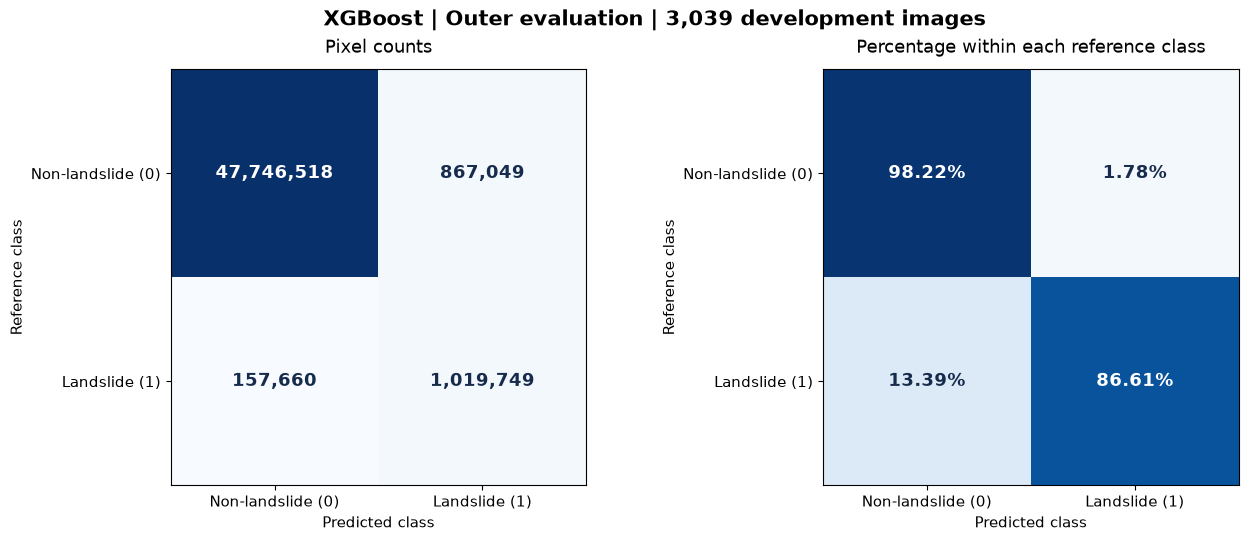

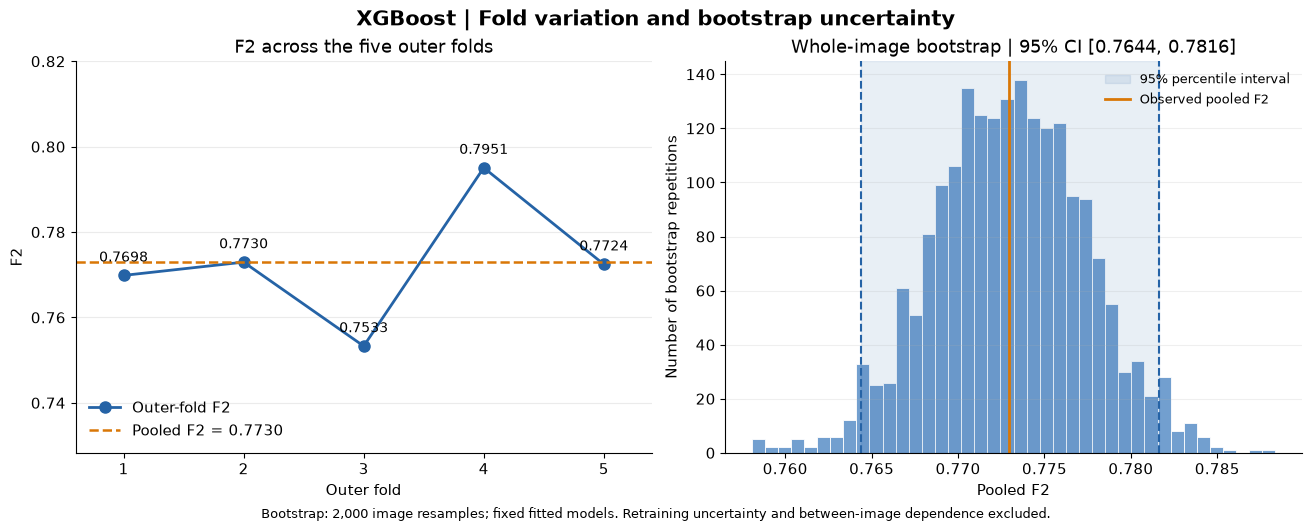

Saved: C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\xgboost\checkpoints\pooled_outer_v1


In [13]:
# XGBoost — Step 7: pooled outer metrics, per-image counts, and whole-image bootstrap.
# Uses the saved outer-fold predictions only. No fitting or new predictions.

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score

XGB_PIXELS_PER_IMAGE = 128 * 128
XGB_BOOTSTRAP_REPETITIONS = 2000
XGB_EPSILON = np.finfo(np.float64).eps

XGB_POOLED_DIR = (
    XGB_PROJECT_PATH / "artifacts" / "xgboost" / "checkpoints" / "pooled_outer_v1"
)
XGB_POOLED_PLOT_DIR = XGB_POOLED_DIR / "plots"
XGB_POOLED_PLOT_DIR.mkdir(parents=True, exist_ok=True)


def xgb_ratio(numerator, denominator):
    numerator = np.asarray(numerator, dtype=float)
    denominator = np.asarray(denominator, dtype=float)
    return np.divide(
        numerator, denominator,
        out=np.zeros_like(numerator), where=denominator != 0,
    )


def xgb_metrics_from_counts(counts):
    tp = np.asarray(counts["TP"], dtype=float)
    fp = np.asarray(counts["FP"], dtype=float)
    fn = np.asarray(counts["FN"], dtype=float)
    tn = np.asarray(counts["TN"], dtype=float)
    return {
        "F2": xgb_ratio(5 * tp, 5 * tp + 4 * fn + fp),
        "Precision": xgb_ratio(tp, tp + fp),
        "Recall": xgb_ratio(tp, tp + fn),
        "Specificity": xgb_ratio(tn, tn + fp),
        "IoU": xgb_ratio(tp, tp + fp + fn),
    }


def xgb_per_image_counts(image_ids, scores, labels, threshold):
    """Confusion counts and probability-loss sums for every complete image."""
    n_images = len(image_ids)
    scores_2d = np.asarray(scores, dtype=np.float64).reshape(n_images, XGB_PIXELS_PER_IMAGE)
    labels_2d = np.asarray(labels, dtype=np.uint8).reshape(n_images, XGB_PIXELS_PER_IMAGE)

    predicted = scores_2d >= threshold
    positive = labels_2d == 1
    clipped = np.clip(scores_2d, XGB_EPSILON, 1 - XGB_EPSILON)

    return pd.DataFrame({
        "image_id": [str(value) for value in image_ids],
        "TN": np.count_nonzero(~predicted & ~positive, axis=1),
        "FP": np.count_nonzero(predicted & ~positive, axis=1),
        "FN": np.count_nonzero(~predicted & positive, axis=1),
        "TP": np.count_nonzero(predicted & positive, axis=1),
        "n_pixels": XGB_PIXELS_PER_IMAGE,
        "brier_sum": np.sum((scores_2d - labels_2d) ** 2, axis=1),
        "log_loss_sum": -np.sum(
            labels_2d * np.log(clipped) + (1 - labels_2d) * np.log1p(-clipped),
            axis=1,
        ),
    })


def xgb_image_bootstrap_f2(per_image, repetitions=XGB_BOOTSTRAP_REPETITIONS,
                           seed=XGB_RANDOM_STATE):
    """Resample complete images; the fitted model and threshold stay fixed."""
    image_counts = per_image[["TN", "FP", "FN", "TP"]].to_numpy(dtype=np.int64)
    rng = np.random.default_rng(seed)
    bootstrap_f2 = np.empty(repetitions, dtype=float)

    for start in range(0, repetitions, 100):
        stop = min(start + 100, repetitions)
        indices = rng.integers(0, len(image_counts), size=(stop - start, len(image_counts)))
        tn, fp, fn, tp = image_counts[indices].sum(axis=1).T
        bootstrap_f2[start:stop] = xgb_ratio(5 * tp, 5 * tp + 4 * fn + fp)

    return bootstrap_f2


def xgb_plot_confusion(counts, title, destination_stem):
    matrix = np.array(
        [[counts["TN"], counts["FP"]], [counts["FN"], counts["TP"]]],
        dtype=np.int64,
    )
    percent = matrix / matrix.sum(axis=1, keepdims=True) * 100
    class_labels = ["Non-landslide (0)", "Landslide (1)"]

    with plt.rc_context({"font.size": 11}):
        fig, axes = plt.subplots(1, 2, figsize=(13, 5.3), constrained_layout=True)

        for ax, values, subtitle, is_percent in (
            (axes[0], matrix, "Pixel counts", False),
            (axes[1], percent, "Percentage within each reference class", True),
        ):
            maximum = 100.0 if is_percent else float(matrix.max())
            ax.imshow(values, cmap="Blues", vmin=0, vmax=maximum)
            ax.set_xticks([0, 1], class_labels)
            ax.set_yticks([0, 1], class_labels)
            ax.set_xlabel("Predicted class")
            ax.set_ylabel("Reference class")
            ax.set_title(subtitle, pad=12)

            for row in range(2):
                for column in range(2):
                    value = values[row, column]
                    ax.text(
                        column, row,
                        f"{value:.2f}%" if is_percent else f"{int(value):,}",
                        ha="center", va="center", fontsize=13, fontweight="bold",
                        color="white" if value > maximum / 2 else "#172B4D",
                    )

        fig.suptitle(title, fontsize=15, fontweight="bold")
        for extension in ("png", "pdf"):
            fig.savefig(
                f"{destination_stem}.{extension}",
                dpi=300, bbox_inches="tight", facecolor="white",
            )
        plt.show()


# ------------------------------------------------------------
# Pool the five saved outer folds.
# ------------------------------------------------------------
xgb_outer_results_sorted = sorted(
    xgb_outer_evaluation_results,
    key=lambda result: int(result["specification"]["outer_fold"]),
)
assert [
    int(result["specification"]["outer_fold"]) for result in xgb_outer_results_sorted
] == [1, 2, 3, 4, 5]

xgb_pooled_specification = {
    "version": "xgb_pooled_outer_v1",
    "fold_specifications": [result["specification"] for result in xgb_outer_results_sorted],
    "bootstrap_repetitions": XGB_BOOTSTRAP_REPETITIONS,
    "random_state": XGB_RANDOM_STATE,
}

xgb_pooled_summary_file = XGB_POOLED_DIR / "summary.joblib"
xgb_pooled_scores_file = XGB_POOLED_DIR / "scores.npy"
xgb_pooled_labels_file = XGB_POOLED_DIR / "labels.npy"

if xgb_pooled_summary_file.is_file():
    xgb_pooled_outer_summary = joblib.load(xgb_pooled_summary_file)
    assert xgb_pooled_outer_summary["specification"] == xgb_pooled_specification
    print("Saved pooled outer summary restored.")

else:
    per_image_parts = []
    fold_rows = []
    ordered_ids = []

    for result in xgb_outer_results_sorted:
        fold = int(result["specification"]["outer_fold"])
        image_ids = [str(value) for value in result["ordered_image_ids"]]
        threshold = float(result["threshold"])
        scores = np.asarray(result["scores"])
        labels = np.asarray(result["labels"])

        assert scores.shape == labels.shape == (len(image_ids) * XGB_PIXELS_PER_IMAGE,)

        fold_per_image = xgb_per_image_counts(image_ids, scores, labels, threshold)
        fold_per_image.insert(1, "outer_fold", fold)
        fold_per_image.insert(2, "threshold", threshold)

        # Per-image counts must reproduce the saved fold counts exactly.
        for name in ("TN", "FP", "FN", "TP"):
            assert int(fold_per_image[name].sum()) == int(result["metrics"][name]), (
                f"Outer {fold}: {name} mismatch."
            )

        per_image_parts.append(fold_per_image)
        ordered_ids.extend(image_ids)

        fold_rows.append({
            "Outer_fold": fold,
            "Candidate": int(result["specification"]["selected_candidate"]),
            "Threshold": threshold,
            "F2": result["metrics"]["F2"],
            "Precision": result["metrics"]["Precision"],
            "Recall": result["metrics"]["Recall"],
            "Specificity": result["metrics"]["Specificity"],
            "IoU": result["metrics"]["IoU"],
            "ROC_AUC": result["metrics"]["ROC_AUC"],
            "Average_precision": result["metrics"]["Average_precision"],
            "Brier_score": result["metrics"]["Brier"],
            "Log_loss": result["metrics"]["Log_loss"],
            "TN": result["metrics"]["TN"],
            "FP": result["metrics"]["FP"],
            "FN": result["metrics"]["FN"],
            "TP": result["metrics"]["TP"],
            "Fit_seconds": result["fit_seconds"],
            "Evaluation_seconds": result["evaluation_seconds"],
        })

    per_image_all = pd.concat(per_image_parts, ignore_index=True)

    assert len(per_image_all) == 3039
    assert per_image_all["image_id"].is_unique
    assert set(per_image_all["image_id"]) == xgb_development_id_set

    counts = {name: int(per_image_all[name].sum()) for name in ("TN", "FP", "FN", "TP")}
    n_pixels = int(per_image_all["n_pixels"].sum())
    assert sum(counts.values()) == n_pixels == 3039 * XGB_PIXELS_PER_IMAGE

    metrics = {name: float(value) for name, value in xgb_metrics_from_counts(counts).items()}
    metrics["Brier_score"] = float(per_image_all["brier_sum"].sum() / n_pixels)
    metrics["Log_loss"] = float(per_image_all["log_loss_sum"].sum() / n_pixels)

    all_scores = np.concatenate([
        np.asarray(result["scores"], dtype=np.float32) for result in xgb_outer_results_sorted
    ])
    all_labels = np.concatenate([
        np.asarray(result["labels"], dtype=np.uint8) for result in xgb_outer_results_sorted
    ])
    np.save(xgb_pooled_scores_file, all_scores)
    np.save(xgb_pooled_labels_file, all_labels)

    print("Calculating pooled ROC-AUC and average precision...", flush=True)
    metrics["ROC_AUC"] = float(roc_auc_score(all_labels, all_scores))
    metrics["Average_precision"] = float(average_precision_score(all_labels, all_scores))
    del all_scores, all_labels

    print("Whole-image bootstrap: 2,000 repetitions...", flush=True)
    bootstrap_f2 = xgb_image_bootstrap_f2(per_image_all)

    xgb_pooled_outer_summary = {
        "specification": xgb_pooled_specification,
        "metrics": metrics,
        "counts": counts,
        "n_pixels": n_pixels,
        "ordered_image_ids": ordered_ids,
        "per_image": per_image_all,
        "fold_metrics": pd.DataFrame(fold_rows),
        "F2_bootstrap_95_interval": np.quantile(bootstrap_f2, [0.025, 0.975]),
        "bootstrap_F2": bootstrap_f2,
        "scores_path": str(xgb_pooled_scores_file),
        "labels_path": str(xgb_pooled_labels_file),
    }
    xgb_atomic_joblib_dump(xgb_pooled_outer_summary, xgb_pooled_summary_file)

xgb_outer_metrics_table = xgb_pooled_outer_summary["fold_metrics"]

# ------------------------------------------------------------
# Display.
# ------------------------------------------------------------
print("\nOUTER-FOLD RESULTS")
print(
    xgb_outer_metrics_table[
        ["Outer_fold", "Candidate", "Threshold", "F2", "Precision", "Recall", "Specificity", "IoU"]
    ].to_string(index=False, float_format=lambda x: f"{x:.6f}")
)

fold_f2 = xgb_outer_metrics_table["F2"].to_numpy()
print(f"\nFold F2 mean ± SD: {fold_f2.mean():.6f} ± {fold_f2.std(ddof=1):.6f}")

print("\nPOOLED OUTER METRICS — ALL 3,039 DEVELOPMENT IMAGES")
for name in ("F2", "Precision", "Recall", "Specificity", "IoU",
             "ROC_AUC", "Average_precision", "Brier_score", "Log_loss"):
    print(f"{name}: {xgb_pooled_outer_summary['metrics'][name]:.6f}")

print("\nPooled confusion counts:", xgb_pooled_outer_summary["counts"])
lower, upper = xgb_pooled_outer_summary["F2_bootstrap_95_interval"]
print(f"F2 95% whole-image bootstrap interval: [{lower:.6f}, {upper:.6f}]")
print("Fixed fitted models; retraining uncertainty and between-image dependence excluded.")

# ------------------------------------------------------------
# Figures.
# ------------------------------------------------------------
xgb_plot_confusion(
    xgb_pooled_outer_summary["counts"],
    "XGBoost | Outer evaluation | 3,039 development images",
    XGB_POOLED_PLOT_DIR / "xgb_outer_confusion_matrices",
)

pooled_f2 = xgb_pooled_outer_summary["metrics"]["F2"]
folds = xgb_outer_metrics_table["Outer_fold"].to_numpy()

with plt.rc_context({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False}):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), constrained_layout=True)

    axes[0].plot(folds, fold_f2, color="#2563A6", marker="o", markersize=8,
                 linewidth=2, label="Outer-fold F2")
    axes[0].axhline(pooled_f2, color="#D97706", linestyle="--", linewidth=1.8,
                    label=f"Pooled F2 = {pooled_f2:.4f}")
    for fold, value in zip(folds, fold_f2):
        axes[0].annotate(f"{value:.4f}", (fold, value), xytext=(0, 10),
                         textcoords="offset points", ha="center", fontsize=10)
    axes[0].set(title="F2 across the five outer folds", xlabel="Outer fold",
                ylabel="F2", xticks=folds, xlim=(0.6, 5.4))
    axes[0].set_ylim(min(fold_f2.min(), pooled_f2) - 0.025,
                     max(fold_f2.max(), pooled_f2) + 0.025)
    axes[0].grid(axis="y", alpha=0.25)
    axes[0].legend(loc="lower left", frameon=False)

    axes[1].hist(xgb_pooled_outer_summary["bootstrap_F2"], bins=40,
                 color="#729FCF", edgecolor="white", linewidth=0.6)
    axes[1].axvspan(lower, upper, color="#2563A6", alpha=0.10,
                    label="95% percentile interval")
    axes[1].axvline(pooled_f2, color="#D97706", linewidth=2, label="Observed pooled F2")
    axes[1].axvline(lower, color="#2563A6", linestyle="--", linewidth=1.5)
    axes[1].axvline(upper, color="#2563A6", linestyle="--", linewidth=1.5)
    axes[1].set(title=f"Whole-image bootstrap | 95% CI [{lower:.4f}, {upper:.4f}]",
                xlabel="Pooled F2", ylabel="Number of bootstrap repetitions")
    axes[1].grid(axis="y", alpha=0.20)
    axes[1].legend(frameon=False, fontsize=9)

    fig.suptitle("XGBoost | Fold variation and bootstrap uncertainty",
                 fontsize=15, fontweight="bold")
    fig.supxlabel("Bootstrap: 2,000 image resamples; fixed fitted models. "
                  "Retraining uncertainty and between-image dependence excluded.", fontsize=9)

    for extension in ("png", "pdf"):
        fig.savefig(XGB_POOLED_PLOT_DIR / f"xgb_outer_f2_stability_bootstrap.{extension}",
                    dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

print("Saved:", XGB_POOLED_DIR)

**Result — pooled outer evaluation.** Across all 3,039 development images, XGBoost reached a pooled outer F2 of 0.7730 (95% whole-image bootstrap interval [0.7644, 0.7816]) at the inner-selected threshold of 0.14. It detected 86.61% of landslide pixels (recall) and correctly rejected 98.22% of non-landslide pixels (specificity). As with HGB, the main weakness is false positives: 867,049 false-positive pixels against 1,019,749 true positives limit precision to 54.05% (IoU 0.4988). Ranking quality is very high (ROC-AUC 0.9903, average precision 0.7887), and the Brier score is low (0.0095). Performance is stable across outer folds (F2 0.7727 ± 0.0149; range 0.7533 in fold 3 to 0.7951 in fold 4). Fold 3 is also the weakest fold for HGB, which points to harder images in that fold rather than a model-specific problem. These outer results are almost identical to HGB (pooled F2 0.7739, interval [0.7652, 0.7826]); whether the small difference is meaningful will be tested later with a paired comparison on the same images.

In [14]:
# XGBoost — Step 8: final development selection.
# Same three development inner folds as HGB (validated_splits.joblib).
# Outer-evaluation results and secondary-test images are not used.

XGB_FINAL_SELECTION_DIR = (
    XGB_PROJECT_PATH / "artifacts" / "xgboost" / "checkpoints" / "final_development_selection_v1"
)
XGB_FINAL_SELECTION_DIR.mkdir(parents=True, exist_ok=True)

xgb_final_inner_splits = xgb_saved_splits["inner_splits"]
assert len(xgb_final_inner_splits) == 3

xgb_final_validation_sets = []
for fold_number, split in enumerate(xgb_final_inner_splits, start=1):
    train_set = set(xgb_checked_id_list(split["train_ids"], f"Final inner {fold_number} training"))
    validation_set = set(xgb_checked_id_list(split["validation_ids"], f"Final inner {fold_number} validation"))
    assert train_set.isdisjoint(validation_set)
    assert train_set | validation_set == xgb_development_id_set
    xgb_final_validation_sets.append(validation_set)

assert all(
    xgb_final_validation_sets[i].isdisjoint(xgb_final_validation_sets[j])
    for i in range(3) for j in range(i + 1, 3)
)
assert set.union(*xgb_final_validation_sets) == xgb_development_id_set


def xgb_threshold_counts(positive_histogram, negative_histogram):
    fn = np.cumsum(positive_histogram)[:-1]
    tn = np.cumsum(negative_histogram)[:-1]
    return {
        "TN": tn,
        "FP": negative_histogram.sum() - tn,
        "FN": fn,
        "TP": positive_histogram.sum() - fn,
    }


def xgb_run_final_candidate(inner_fold, split, candidate):
    candidate_number = int(candidate["candidate"])
    train_ids = xgb_checked_id_list(split["train_ids"], f"Final inner {inner_fold} training")
    validation_ids = xgb_checked_id_list(split["validation_ids"], f"Final inner {inner_fold} validation")
    candidate_parameters = {k: v for k, v in candidate.items() if k != "candidate"}

    specification = {
        "stage": "final_development_selection_v1",
        "inner_fold": inner_fold,
        "candidate": candidate_number,
        "candidate_parameters": candidate_parameters,
        "common_parameters": xgb_common_parameters,
        "train_ids": train_ids,
        "validation_ids": validation_ids,
        "thresholds": xgb_thresholds.tolist(),
        "feature_names": xgb_feature_names,
        "xgboost_version": xgb.__version__,
    }

    checkpoint = XGB_FINAL_SELECTION_DIR / (
        f"inner_{inner_fold:02d}_candidate_{candidate_number:02d}.joblib"
    )

    if checkpoint.is_file():
        saved = joblib.load(checkpoint)
        if saved["specification"] != specification:
            raise ValueError(f"Checkpoint specification mismatch: {checkpoint}")
        print(f"Restored final inner {inner_fold}, candidate {candidate_number}.")
        return saved

    rows = np.asarray([xgb_image_to_row[i] for i in train_ids], dtype=np.int64)
    X_train = xgb_X_by_image[rows].reshape(-1, 14)
    y_train = xgb_y_by_image[rows].reshape(-1)

    model = XGBClassifier(**xgb_common_parameters, **candidate_parameters)

    print(
        f"\nStarting final inner {inner_fold}, candidate {candidate_number}: "
        f"{len(train_ids)} training images, {len(validation_ids)} validation images.",
        flush=True,
    )
    fit_start = time.perf_counter()
    model.fit(X_train, y_train, verbose=False)
    fit_seconds = time.perf_counter() - fit_start
    del X_train, y_train, rows

    positive_histogram, negative_histogram, evaluation_seconds = xgb_evaluate_image_ids(
        model, validation_ids, xgb_thresholds,
        f"Final inner {inner_fold}, candidate {candidate_number}",
    )

    result = {
        "specification": specification,
        "positive_histogram": positive_histogram,
        "negative_histogram": negative_histogram,
        "fit_seconds": fit_seconds,
        "evaluation_seconds": evaluation_seconds,
    }
    xgb_atomic_joblib_dump(result, checkpoint)
    print(
        f"Completed final inner {inner_fold}, candidate {candidate_number} "
        f"| fit={fit_seconds:.1f}s | full-image validation={evaluation_seconds:.1f}s",
        flush=True,
    )
    return result


xgb_final_fold_results = {}
for inner_fold, split in enumerate(xgb_final_inner_splits, start=1):
    for candidate in xgb_candidate_parameters:
        xgb_final_fold_results[(inner_fold, int(candidate["candidate"]))] = (
            xgb_run_final_candidate(inner_fold, split, candidate)
        )

# ------------------------------------------------------------
# Pooled selection across the three inner folds.
# ------------------------------------------------------------
n_candidates = len(xgb_candidate_parameters)
n_thresholds = len(xgb_thresholds)

final_counts = {name: np.zeros((n_candidates, n_thresholds), dtype=np.int64)
                for name in ("TN", "FP", "FN", "TP")}
final_inner_f2 = np.zeros((n_candidates, 3, n_thresholds))

for candidate_index, candidate in enumerate(xgb_candidate_parameters):
    candidate_number = int(candidate["candidate"])
    for inner_fold in range(1, 4):
        result = xgb_final_fold_results[(inner_fold, candidate_number)]
        counts = xgb_threshold_counts(result["positive_histogram"], result["negative_histogram"])
        for name in final_counts:
            final_counts[name][candidate_index] += counts[name]
        final_inner_f2[candidate_index, inner_fold - 1] = xgb_metrics_from_counts(counts)["F2"]

final_metrics = xgb_metrics_from_counts(final_counts)

# Tie rule: earlier candidate, then lower threshold.
best_candidate_index, best_threshold_index = np.unravel_index(
    int(np.argmax(final_metrics["F2"])), final_metrics["F2"].shape
)

candidate_rows = []
for candidate_index, candidate in enumerate(xgb_candidate_parameters):
    threshold_index = int(np.argmax(final_metrics["F2"][candidate_index]))
    candidate_rows.append({
        "Candidate": int(candidate["candidate"]),
        "Threshold": float(xgb_thresholds[threshold_index]),
        **{k: v for k, v in candidate.items() if k != "candidate"},
        **{name: float(values[candidate_index, threshold_index])
           for name, values in final_metrics.items()},
        "Mean_inner_F2": float(final_inner_f2[candidate_index, :, threshold_index].mean()),
        "Fit_seconds_total": float(sum(
            xgb_final_fold_results[(f, int(candidate["candidate"]))]["fit_seconds"] for f in range(1, 4)
        )),
    })

selected = xgb_candidate_parameters[best_candidate_index]

xgb_final_selection = {
    "specification": {
        "stage": "final_development_selection_v1",
        "selection_rule": "maximum pooled inner F2",
        "tie_rule": "earlier candidate, then lower threshold",
        "split_file": str(XGB_SPLIT_FILE),
    },
    "selected_candidate": int(selected["candidate"]),
    "selected_parameters": {k: v for k, v in selected.items() if k != "candidate"},
    "selected_threshold": float(xgb_thresholds[best_threshold_index]),
    "selected_inner_pooled_F2": float(final_metrics["F2"][best_candidate_index, best_threshold_index]),
    "calibration": "none",
    "candidate_summary": pd.DataFrame(candidate_rows),
    "pooled_counts": final_counts,
    "thresholds": xgb_thresholds.copy(),
    "inner_f2": final_inner_f2,
}

xgb_final_selection_file = XGB_FINAL_SELECTION_DIR / "selection.joblib"
xgb_atomic_joblib_dump(xgb_final_selection, xgb_final_selection_file)
xgb_final_selection["candidate_summary"].to_csv(
    XGB_FINAL_SELECTION_DIR / "final_candidate_summary.csv", index=False
)

# ------------------------------------------------------------
# Nested search: best threshold per candidate in each outer fold (appendix table).
# ------------------------------------------------------------
nested_rows = []
for outer_fold in range(1, 6):
    for candidate in xgb_candidate_parameters:
        candidate_number = int(candidate["candidate"])
        positive_total = 0
        negative_total = 0
        for inner_fold in range(1, 4):
            saved = joblib.load(
                XGB_NESTED_SEARCH_DIR
                / f"outer_{outer_fold:02d}_inner_{inner_fold:02d}_candidate_{candidate_number:02d}.joblib"
            )
            positive_total = positive_total + saved["positive_histogram"]
            negative_total = negative_total + saved["negative_histogram"]

        metrics = xgb_metrics_from_counts(xgb_threshold_counts(positive_total, negative_total))
        index = int(np.argmax(metrics["F2"]))
        nested_rows.append({
            "Outer_fold": outer_fold,
            "Candidate": candidate_number,
            "Threshold": float(xgb_thresholds[index]),
            **{name: float(values[index]) for name, values in metrics.items()},
        })

xgb_nested_candidate_table = pd.DataFrame(nested_rows)
xgb_nested_candidate_table.to_csv(
    XGB_FINAL_SELECTION_DIR / "nested_candidate_summary.csv", index=False
)

print("\nNESTED SEARCH — BEST F2 PER CANDIDATE AND OUTER FOLD (inner validation)")
print(
    xgb_nested_candidate_table.pivot(index="Outer_fold", columns="Candidate", values="F2")
    .to_string(float_format=lambda x: f"{x:.6f}")
)

print("\nFINAL DEVELOPMENT SELECTION")
print(
    xgb_final_selection["candidate_summary"][
        ["Candidate", "Threshold", "F2", "Precision", "Recall", "Specificity", "IoU", "Mean_inner_F2"]
    ].to_string(index=False, float_format=lambda x: f"{x:.6f}")
)
print("\nSelected candidate:", xgb_final_selection["selected_candidate"])
print("Selected threshold:", xgb_final_selection["selected_threshold"])
print("Selected parameters:", xgb_final_selection["selected_parameters"])
print(f"Pooled inner F2: {xgb_final_selection['selected_inner_pooled_F2']:.6f}")
print("Additional calibration: none")
print("Saved:", xgb_final_selection_file)
print("The final model has not been fitted yet.")


Starting final inner 1, candidate 1: 2026 training images, 1013 validation images.
Final inner 1, candidate 1: evaluated 300/1013 images in 6.1 seconds
Final inner 1, candidate 1: evaluated 600/1013 images in 12.1 seconds
Final inner 1, candidate 1: evaluated 900/1013 images in 18.1 seconds
Final inner 1, candidate 1: evaluated 1013/1013 images in 20.4 seconds
Completed final inner 1, candidate 1 | fit=31.4s | full-image validation=20.4s

Starting final inner 1, candidate 2: 2026 training images, 1013 validation images.
Final inner 1, candidate 2: evaluated 300/1013 images in 10.1 seconds
Final inner 1, candidate 2: evaluated 600/1013 images in 20.3 seconds
Final inner 1, candidate 2: evaluated 900/1013 images in 30.4 seconds
Final inner 1, candidate 2: evaluated 1013/1013 images in 34.3 seconds
Completed final inner 1, candidate 2 | fit=48.8s | full-image validation=34.3s

Starting final inner 1, candidate 3: 2026 training images, 1013 validation images.
Final inner 1, candidate 3: e

**Result — final development selection.** On the three development inner folds (all 3,039 development images), candidate 2 (600 trees, max_depth = 4, learning_rate = 0.05, min_child_weight = 10, reg_lambda = 10, no class weighting) achieved the highest pooled F2 (0.7734) at threshold 0.14, with precision 54.16%, recall 86.61%, and IoU 0.4998. This matches the nested search, where candidate 2 with threshold 0.14 was selected in all five outer folds, and the ranking candidate 2 > candidate 3 > candidate 1 was identical in every fold. The differences are small (F2 0.7601–0.7734). Candidate 3, which weights landslide pixels three times more (scale_pos_weight = 3), reached nearly the same F2 (0.7707) but at a higher optimal threshold (0.33): class weighting shifts the probability scale rather than improving detection, because the threshold is optimized anyway. No additional calibration was applied. These are selection results, not test results.

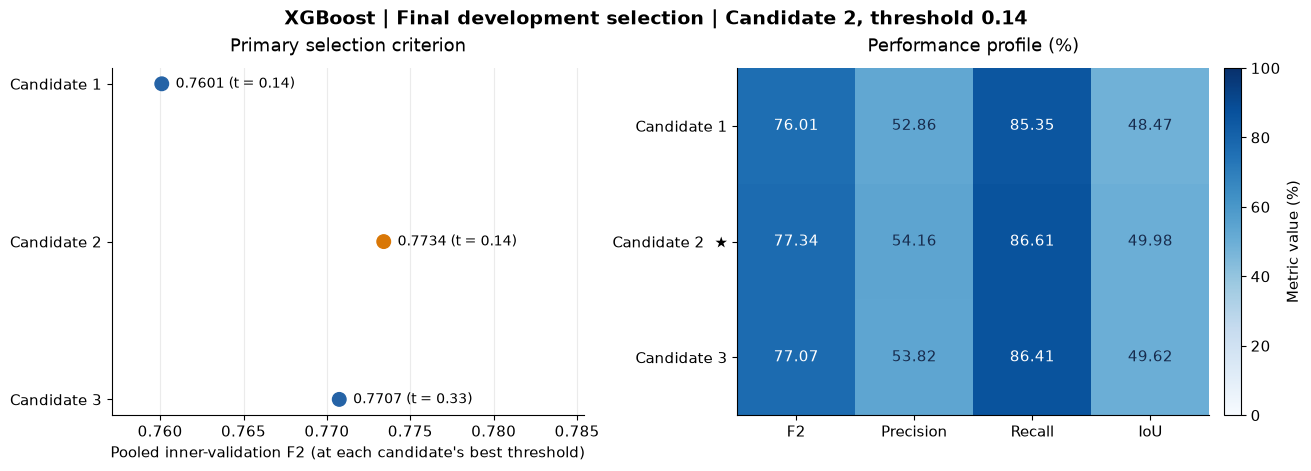

Final training: 3,039 images / 3,111,936 sampled pixels...

FINAL MODEL TRAINED AND SAVED
Candidate: 2
Parameters: {'objective': 'binary:logistic', 'eval_metric': 'logloss', 'tree_method': 'hist', 'n_jobs': 2, 'random_state': 43, 'verbosity': 0, 'n_estimators': 600, 'max_depth': 4, 'learning_rate': 0.05, 'min_child_weight': 10, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_lambda': 10.0, 'scale_pos_weight': 1.0}
Locked threshold: 0.14
Additional calibration: none
Fit time: 73.6 seconds
Model: C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\xgboost\checkpoints\final_model_v1\model.joblib
Secondary test has not yet been evaluated.


In [15]:
# XGBoost — Step 9: visualize the final selection and fit/save the locked final model.
# One final fit on all 3,039 development images. No secondary-test evaluation.

candidate_table = (
    xgb_final_selection["candidate_summary"].sort_values("Candidate").reset_index(drop=True)
)
selected_candidate = int(xgb_final_selection["selected_candidate"])
selected_threshold = float(xgb_final_selection["selected_threshold"])

with plt.rc_context({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False}):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), constrained_layout=True)

    positions = np.arange(len(candidate_table))
    colors = ["#D97706" if int(c) == selected_candidate else "#2563A6"
              for c in candidate_table["Candidate"]]

    axes[0].scatter(candidate_table["F2"], positions, c=colors, s=95, zorder=3)
    for position, row in candidate_table.iterrows():
        axes[0].annotate(
            f"{row['F2']:.4f} (t = {row['Threshold']:.2f})",
            (row["F2"], position), xytext=(10, 0),
            textcoords="offset points", va="center", fontsize=10,
        )
    axes[0].set_yticks(positions, [f"Candidate {int(c)}" for c in candidate_table["Candidate"]])
    axes[0].invert_yaxis()
    axes[0].set_xlim(candidate_table["F2"].min() - 0.003, candidate_table["F2"].max() + 0.012)
    axes[0].set_xlabel("Pooled inner-validation F2 (at each candidate's best threshold)")
    axes[0].set_title("Primary selection criterion", pad=12)
    axes[0].grid(axis="x", alpha=0.25)
    axes[0].set_axisbelow(True)

    metric_names = ["F2", "Precision", "Recall", "IoU"]
    values = candidate_table[metric_names].to_numpy() * 100
    heatmap = axes[1].imshow(values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
    axes[1].set_xticks(range(4), metric_names)
    axes[1].set_yticks(
        positions,
        [f"Candidate {int(c)}" + ("  ★" if int(c) == selected_candidate else "")
         for c in candidate_table["Candidate"]],
    )
    axes[1].set_title("Performance profile (%)", pad=12)
    for row in range(values.shape[0]):
        for column in range(values.shape[1]):
            value = values[row, column]
            axes[1].text(column, row, f"{value:.2f}", ha="center", va="center",
                         color="white" if value >= 65 else "#172B4D")
    fig.colorbar(heatmap, ax=axes[1], fraction=0.04, pad=0.03, label="Metric value (%)")

    fig.suptitle(
        f"XGBoost | Final development selection | "
        f"Candidate {selected_candidate}, threshold {selected_threshold:.2f}",
        fontsize=14, fontweight="bold",
    )
    for extension in ("png", "pdf"):
        fig.savefig(XGB_FINAL_SELECTION_DIR / f"xgb_candidate_selection.{extension}",
                    dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

# ------------------------------------------------------------
# Lock the specification and fit once.
# ------------------------------------------------------------
xgb_final_specification = {
    "version": "xgb_final_model_v1",
    "parameters": {**xgb_common_parameters, **xgb_final_selection["selected_parameters"]},
    "threshold": selected_threshold,
    "calibration": "none",
    "feature_names": xgb_feature_names,
    "development_ids": xgb_development_ids,
    "pixels_per_image": 1024,
    "training_pixels": 3039 * 1024,
    "xgboost_version": xgb.__version__,
    "selection_file": str(xgb_final_selection_file),
}
assert xgb_final_specification["parameters"]["random_state"] == 43
assert xgb_final_specification["calibration"] == "none"

XGB_FINAL_MODEL_DIR = (
    XGB_PROJECT_PATH / "artifacts" / "xgboost" / "checkpoints" / "final_model_v1"
)
XGB_FINAL_MODEL_DIR.mkdir(parents=True, exist_ok=True)
xgb_final_model_file = XGB_FINAL_MODEL_DIR / "model.joblib"

if xgb_final_model_file.is_file():
    checkpoint = joblib.load(xgb_final_model_file)
    if checkpoint["specification"] != xgb_final_specification:
        raise ValueError("Saved final model has a different specification.")
    xgb_final_model = checkpoint["model"]
    xgb_final_fit_seconds = float(checkpoint["fit_seconds"])
    print("Saved final model restored; no retraining.")

else:
    final_rows = np.asarray([xgb_image_to_row[i] for i in xgb_development_ids], dtype=np.int64)
    X_final = xgb_X_by_image[final_rows].reshape(-1, 14)
    y_final = xgb_y_by_image[final_rows].reshape(-1)
    assert X_final.shape == (3_111_936, 14)
    assert y_final.shape == (3_111_936,)

    xgb_final_model = XGBClassifier(**xgb_final_specification["parameters"])
    print("Final training: 3,039 images / 3,111,936 sampled pixels...", flush=True)

    fit_start = time.perf_counter()
    xgb_final_model.fit(X_final, y_final, verbose=False)
    xgb_final_fit_seconds = time.perf_counter() - fit_start
    del X_final, y_final, final_rows

    xgb_atomic_joblib_dump(
        {"specification": xgb_final_specification,
         "model": xgb_final_model,
         "fit_seconds": xgb_final_fit_seconds},
        xgb_final_model_file,
    )
    xgb_final_model.save_model(str(XGB_FINAL_MODEL_DIR / "model.json"))

print("\nFINAL MODEL TRAINED AND SAVED")
print("Candidate:", selected_candidate)
print("Parameters:", xgb_final_specification["parameters"])
print("Locked threshold:", selected_threshold)
print("Additional calibration: none")
print(f"Fit time: {xgb_final_fit_seconds:.1f} seconds")
print("Model:", xgb_final_model_file)
print("Secondary test has not yet been evaluated.")

**Result — final model.** The figure confirms that the three candidates differ only slightly (F2 0.7601–0.7734), with candidate 2 best on all four metrics (F2, precision, recall, IoU). Candidate 3 reaches nearly the same performance but at a much higher threshold (0.33) because of its class weighting. The final XGBoost model (candidate 2: 600 trees, max_depth = 4, learning_rate = 0.05, min_child_weight = 10, subsample = 0.8, colsample_bytree = 0.8, reg_lambda = 10) was trained once on all 3,039 development images (3,111,936 sampled pixels) in 73.6 s. The threshold was locked at 0.14 and no calibration was applied. The model was saved before any secondary-test evaluation.

Evaluating 760 secondary-test images...
Evaluated 100/760 images | 6.3 s
Evaluated 200/760 images | 12.4 s
Evaluated 300/760 images | 19.0 s
Evaluated 400/760 images | 25.5 s
Evaluated 500/760 images | 31.6 s
Evaluated 600/760 images | 38.0 s
Evaluated 700/760 images | 44.3 s
Evaluated 760/760 images | 48.2 s
Calculating ROC-AUC and average precision...
Whole-image bootstrap: 2,000 repetitions...

XGBOOST SECONDARY TEST — LOCKED THRESHOLD 0.14
F2: 0.765123
Precision: 0.530182
Recall: 0.860446
Specificity: 0.983396
IoU: 0.488202
ROC_AUC: 0.990494
Average_precision: 0.773009
Brier_score: 0.008950
Log_loss: 0.031038

Confusion counts: {'TN': 11984111, 'FP': 202348, 'FN': 37035, 'TP': 228346}
F2 95% whole-image bootstrap interval: [0.745674, 0.783658]
Prediction time for 760 images: 48.2 s
Secondary/exploratory evaluation; nothing was tuned on these results.
CI excludes retraining uncertainty and between-image dependence.
Saved: C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\xgboost

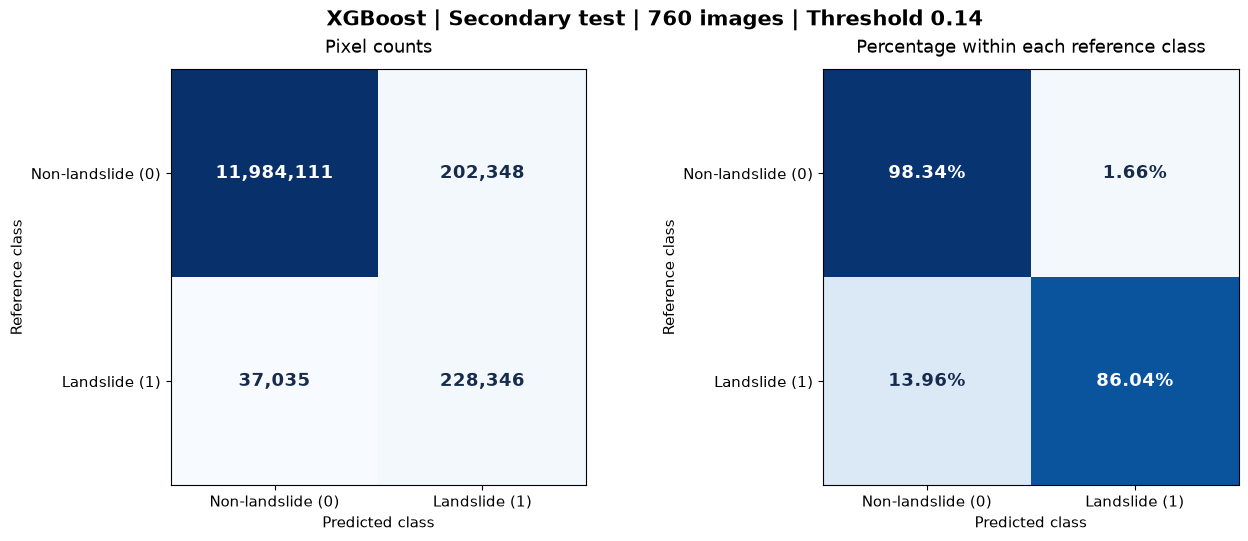

In [16]:
# XGBoost — Step 10: locked-model secondary-test evaluation.
# No training, tuning, calibration fitting, or threshold changes.

xgb_test_ids = list(xgb_secondary_test_ids)
xgb_test_threshold = float(xgb_final_specification["threshold"])

assert len(xgb_test_ids) == len(set(xgb_test_ids)) == 760
assert set(xgb_test_ids).isdisjoint(xgb_development_id_set)
assert xgb_test_threshold == 0.14

xgb_test_specification = {
    "version": "xgb_secondary_test_v1",
    "locked_model": xgb_final_specification,
    "test_ids": xgb_test_ids,
    "bootstrap_repetitions": XGB_BOOTSTRAP_REPETITIONS,
    "random_state": XGB_RANDOM_STATE,
}

XGB_TEST_DIR = XGB_FINAL_MODEL_DIR / "secondary_test_v1"
XGB_TEST_DIR.mkdir(parents=True, exist_ok=True)
xgb_test_result_file = XGB_TEST_DIR / "evaluation.joblib"
xgb_test_scores_file = XGB_TEST_DIR / "scores.npy"
xgb_test_labels_file = XGB_TEST_DIR / "labels.npy"

if xgb_test_result_file.is_file():
    xgb_secondary_result = joblib.load(xgb_test_result_file)
    assert xgb_secondary_result["specification"] == xgb_test_specification
    print("Completed secondary-test evaluation restored.")

else:
    test_scores = np.empty((760, XGB_PIXELS_PER_IMAGE), dtype=np.float32)
    test_labels = np.empty((760, XGB_PIXELS_PER_IMAGE), dtype=np.uint8)

    print("Evaluating 760 secondary-test images...", flush=True)
    evaluation_start = time.perf_counter()

    for index, image_id in enumerate(xgb_test_ids):
        image_X, image_y = xgb_load_source_pair(image_id)
        probabilities = xgb_final_model.predict_proba(image_X)[:, 1]

        assert np.isfinite(probabilities).all()
        assert np.all((probabilities >= 0) & (probabilities <= 1))

        test_scores[index] = probabilities
        test_labels[index] = image_y

        if (index + 1) % 100 == 0 or index + 1 == 760:
            print(f"Evaluated {index + 1}/760 images | "
                  f"{time.perf_counter() - evaluation_start:.1f} s", flush=True)

    evaluation_seconds = time.perf_counter() - evaluation_start

    np.save(xgb_test_scores_file, test_scores)
    np.save(xgb_test_labels_file, test_labels)

    test_per_image = xgb_per_image_counts(
        xgb_test_ids, test_scores, test_labels, xgb_test_threshold
    )
    test_counts = {name: int(test_per_image[name].sum()) for name in ("TN", "FP", "FN", "TP")}
    n_test_pixels = int(test_per_image["n_pixels"].sum())
    assert n_test_pixels == sum(test_counts.values()) == 12_451_840

    test_metrics = {name: float(value)
                    for name, value in xgb_metrics_from_counts(test_counts).items()}

    print("Calculating ROC-AUC and average precision...", flush=True)
    test_metrics["ROC_AUC"] = float(
        roc_auc_score(test_labels.reshape(-1), test_scores.reshape(-1))
    )
    test_metrics["Average_precision"] = float(
        average_precision_score(test_labels.reshape(-1), test_scores.reshape(-1))
    )
    test_metrics["Brier_score"] = float(test_per_image["brier_sum"].sum() / n_test_pixels)
    test_metrics["Log_loss"] = float(test_per_image["log_loss_sum"].sum() / n_test_pixels)

    print("Whole-image bootstrap: 2,000 repetitions...", flush=True)
    test_bootstrap_f2 = xgb_image_bootstrap_f2(test_per_image)

    xgb_secondary_result = {
        "specification": xgb_test_specification,
        "threshold": xgb_test_threshold,
        "ordered_image_ids": xgb_test_ids,
        "metrics": test_metrics,
        "counts": test_counts,
        "per_image": test_per_image,
        "n_pixels": n_test_pixels,
        "F2_bootstrap_95_interval": np.quantile(test_bootstrap_f2, [0.025, 0.975]),
        "bootstrap_F2": test_bootstrap_f2,
        "scores_path": str(xgb_test_scores_file),
        "labels_path": str(xgb_test_labels_file),
        "evaluation_seconds": evaluation_seconds,
    }
    xgb_atomic_joblib_dump(xgb_secondary_result, xgb_test_result_file)
    del test_scores, test_labels

print(f"\nXGBOOST SECONDARY TEST — LOCKED THRESHOLD {xgb_test_threshold:.2f}")
for name in ("F2", "Precision", "Recall", "Specificity", "IoU",
             "ROC_AUC", "Average_precision", "Brier_score", "Log_loss"):
    print(f"{name}: {xgb_secondary_result['metrics'][name]:.6f}")

print("\nConfusion counts:", xgb_secondary_result["counts"])
lower, upper = xgb_secondary_result["F2_bootstrap_95_interval"]
print(f"F2 95% whole-image bootstrap interval: [{lower:.6f}, {upper:.6f}]")
print(f"Prediction time for 760 images: {xgb_secondary_result['evaluation_seconds']:.1f} s")
print("Secondary/exploratory evaluation; nothing was tuned on these results.")
print("CI excludes retraining uncertainty and between-image dependence.")
print("Saved:", xgb_test_result_file)

XGB_TEST_PLOT_DIR = XGB_TEST_DIR / "plots"
XGB_TEST_PLOT_DIR.mkdir(parents=True, exist_ok=True)
xgb_plot_confusion(
    xgb_secondary_result["counts"],
    f"XGBoost | Secondary test | 760 images | Threshold {xgb_test_threshold:.2f}",
    XGB_TEST_PLOT_DIR / "xgb_secondary_confusion",
)

**Result — secondary test.** On the 760 held-out test images (12,451,840 pixels), the locked XGBoost model reached F2 = 0.7651 (95% whole-image bootstrap interval [0.7457, 0.7837]) at the locked threshold of 0.14, with recall 86.04%, precision 53.02%, specificity 98.34%, and IoU 0.4882. Ranking quality is very high (ROC-AUC 0.9905, average precision 0.7730), and probability errors are low (Brier score 0.0090, log loss 0.0310). The test F2 lies within the development bootstrap interval ([0.7644, 0.7816]), so performance transfers to held-out images from the same study areas without a meaningful drop. As in development, false positives remain the main weakness: 202,348 false-positive pixels against 228,346 true positives mean that about every second predicted landslide pixel is incorrect. Compared with HGB on the same test images (F2 0.7663), XGBoost produced slightly fewer false positives (202,348 vs. 205,505) but slightly more missed landslide pixels (37,035 vs. 36,042); the overall difference is very small. Prediction of all 760 images took 48 s. This is a secondary, exploratory evaluation; nothing was tuned on these results.

Locked-threshold count check: PASS
Calibration ECE (15 uniform bins): 0.001120
Calibration MCE (15 uniform bins): 0.052838
Exact ROC-AUC: 0.990494
Exact average precision: 0.773009
F2 at locked threshold 0.14: 0.765123
Diagnostic only — highest test F2 on the grid: 0.765266 at 0.13 (not used for selection)
Maximum IoU on the grid: 0.5427 at 0.37


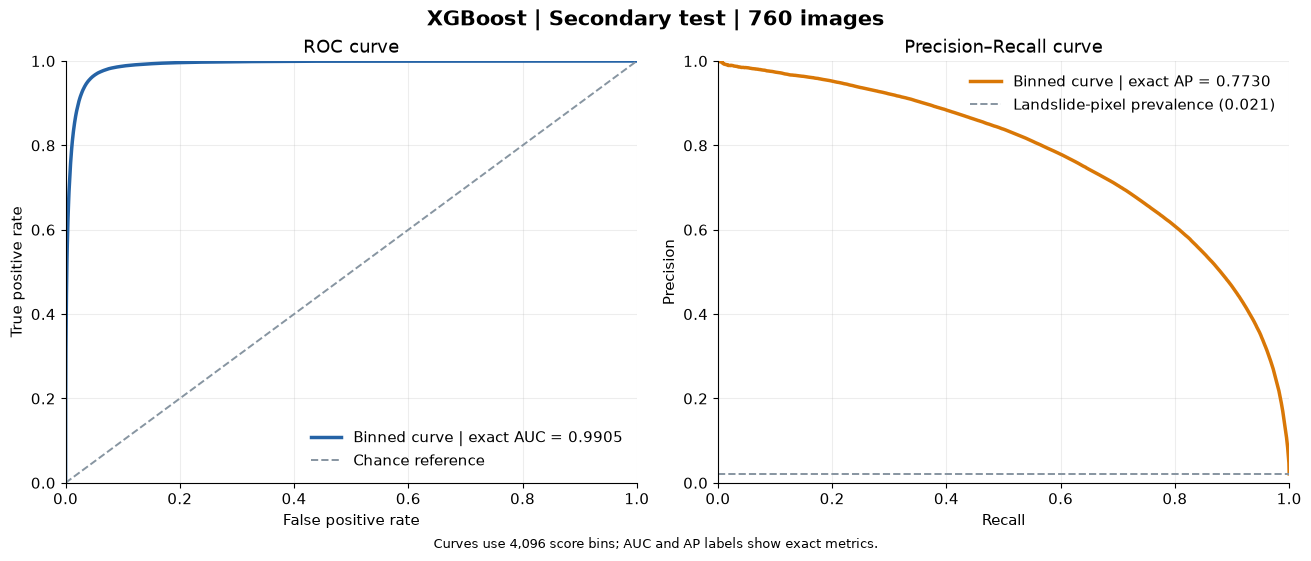

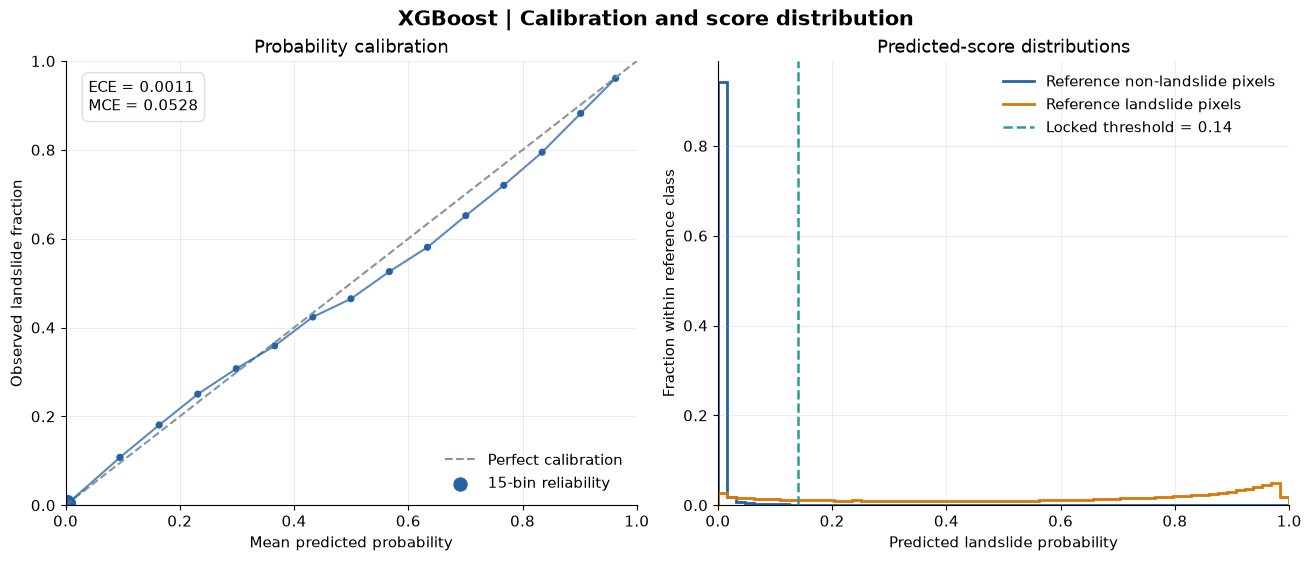

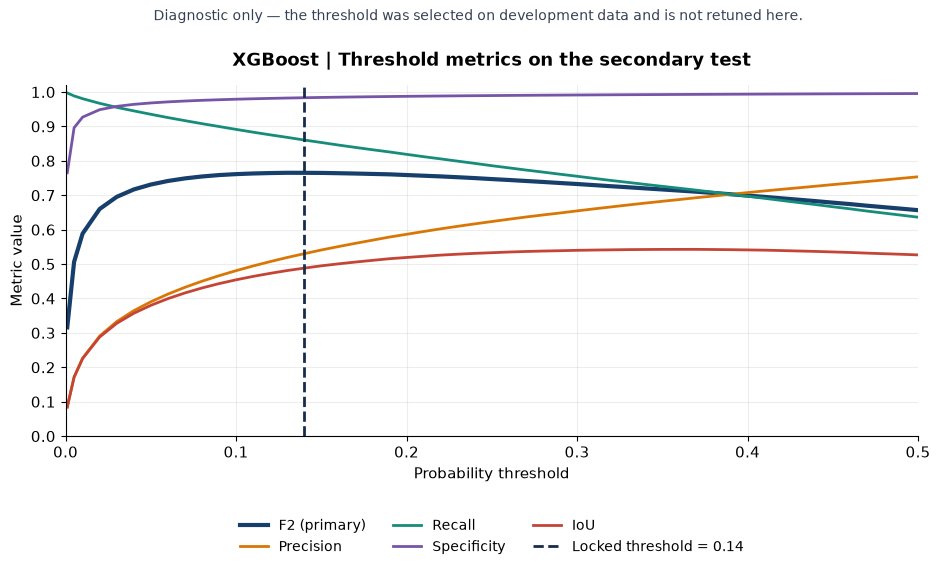

Saved: C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\xgboost\checkpoints\final_model_v1\secondary_test_v1\plots


In [17]:
# XGBoost — Step 11: ROC, PR, calibration, score-distribution, and threshold diagnostics.
# Uses saved secondary-test scores only. The locked threshold is not changed.

locked_threshold = float(xgb_secondary_result["threshold"])
scores = np.load(xgb_secondary_result["scores_path"], mmap_mode="r")
labels = np.load(xgb_secondary_result["labels_path"], mmap_mode="r")
assert scores.shape == labels.shape == (760, XGB_PIXELS_PER_IMAGE)

score_bin_count = 4096
positive_score_hist = np.zeros(score_bin_count, dtype=np.int64)
negative_score_hist = np.zeros(score_bin_count, dtype=np.int64)

calibration_bin_count = 15
calibration_count = np.zeros(calibration_bin_count, dtype=np.int64)
calibration_score_sum = np.zeros(calibration_bin_count)
calibration_positive_sum = np.zeros(calibration_bin_count)

diagnostic_thresholds = np.unique(np.r_[xgb_thresholds, locked_threshold])
positive_threshold_hist = np.zeros(len(diagnostic_thresholds) + 1, dtype=np.int64)
negative_threshold_hist = np.zeros(len(diagnostic_thresholds) + 1, dtype=np.int64)

for start in range(0, 760, 32):
    stop = min(start + 32, 760)
    probability = np.asarray(scores[start:stop], dtype=np.float64).reshape(-1)
    y_true = np.asarray(labels[start:stop]).reshape(-1)
    positive = y_true == 1
    negative = ~positive

    score_bins = np.minimum((probability * score_bin_count).astype(np.int32), score_bin_count - 1)
    positive_score_hist += np.bincount(score_bins[positive], minlength=score_bin_count)
    negative_score_hist += np.bincount(score_bins[negative], minlength=score_bin_count)

    calibration_bins = np.minimum(
        (probability * calibration_bin_count).astype(np.int32), calibration_bin_count - 1
    )
    calibration_count += np.bincount(calibration_bins, minlength=calibration_bin_count)
    calibration_score_sum += np.bincount(calibration_bins, weights=probability,
                                         minlength=calibration_bin_count)
    calibration_positive_sum += np.bincount(calibration_bins, weights=y_true,
                                            minlength=calibration_bin_count)

    threshold_bins = np.searchsorted(diagnostic_thresholds, probability, side="right")
    positive_threshold_hist += np.bincount(threshold_bins[positive],
                                           minlength=len(diagnostic_thresholds) + 1)
    negative_threshold_hist += np.bincount(threshold_bins[negative],
                                           minlength=len(diagnostic_thresholds) + 1)

total_positive = int(positive_score_hist.sum())
total_negative = int(negative_score_hist.sum())

# Binned ROC and PR coordinates.
tp_curve = np.r_[0, np.cumsum(positive_score_hist[::-1])]
fp_curve = np.r_[0, np.cumsum(negative_score_hist[::-1])]
recall_curve = tp_curve / total_positive
fpr_curve = fp_curve / total_negative
precision_curve = np.divide(tp_curve, tp_curve + fp_curve,
                            out=np.ones_like(tp_curve, dtype=float),
                            where=(tp_curve + fp_curve) != 0)

# Calibration (15 uniform bins).
nonempty = calibration_count > 0
mean_predicted = np.divide(calibration_score_sum, calibration_count,
                           out=np.zeros_like(calibration_score_sum), where=nonempty)
observed_fraction = np.divide(calibration_positive_sum, calibration_count,
                              out=np.zeros_like(calibration_positive_sum), where=nonempty)
calibration_gap = np.abs(mean_predicted - observed_fraction)
xgb_ece = float(np.sum(calibration_count[nonempty] / calibration_count.sum()
                       * calibration_gap[nonempty]))
xgb_mce = float(calibration_gap[nonempty].max())

# Exact metrics at every threshold of the grid.
threshold_counts = xgb_threshold_counts(positive_threshold_hist, negative_threshold_hist)
threshold_metrics = xgb_metrics_from_counts(threshold_counts)

locked_index = int(np.flatnonzero(np.isclose(diagnostic_thresholds, locked_threshold))[0])
counts_from_scores = {name: int(threshold_counts[name][locked_index])
                      for name in ("TN", "FP", "FN", "TP")}
assert counts_from_scores == xgb_secondary_result["counts"], (
    "Threshold counts do not match the saved test evaluation."
)

best_test_index = int(np.argmax(threshold_metrics["F2"]))
xgb_calibration_summary = {"ECE_15_uniform": xgb_ece, "MCE_15_uniform": xgb_mce}

print("Locked-threshold count check: PASS")
print(f"Calibration ECE (15 uniform bins): {xgb_ece:.6f}")
print(f"Calibration MCE (15 uniform bins): {xgb_mce:.6f}")
print(f"Exact ROC-AUC: {xgb_secondary_result['metrics']['ROC_AUC']:.6f}")
print(f"Exact average precision: {xgb_secondary_result['metrics']['Average_precision']:.6f}")
print(f"F2 at locked threshold {locked_threshold:.2f}: "
      f"{float(threshold_metrics['F2'][locked_index]):.6f}")
print(f"Diagnostic only — highest test F2 on the grid: "
      f"{float(threshold_metrics['F2'][best_test_index]):.6f} at "
      f"{diagnostic_thresholds[best_test_index]:.2f} (not used for selection)")
print(f"Maximum IoU on the grid: {float(threshold_metrics['IoU'].max()):.4f} at "
      f"{diagnostic_thresholds[int(np.argmax(threshold_metrics['IoU']))]:.2f}")

style = {
    "font.size": 11, "axes.titlesize": 13,
    "axes.spines.top": False, "axes.spines.right": False,
}

with plt.rc_context(style):
    # Figure 1: ROC and PR.
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), constrained_layout=True)
    exact_auc = xgb_secondary_result["metrics"]["ROC_AUC"]
    exact_ap = xgb_secondary_result["metrics"]["Average_precision"]

    axes[0].plot(fpr_curve, recall_curve, color="#2563A6", linewidth=2.5,
                 label=f"Binned curve | exact AUC = {exact_auc:.4f}")
    axes[0].plot([0, 1], [0, 1], color="#8795A1", linestyle="--", linewidth=1.4,
                 label="Chance reference")
    axes[0].set(title="ROC curve", xlabel="False positive rate",
                ylabel="True positive rate", xlim=(0, 1), ylim=(0, 1))
    axes[0].grid(alpha=0.22)
    axes[0].legend(frameon=False, loc="lower right")

    prevalence = total_positive / (total_positive + total_negative)
    axes[1].plot(recall_curve, precision_curve, color="#D97706", linewidth=2.5,
                 label=f"Binned curve | exact AP = {exact_ap:.4f}")
    axes[1].axhline(prevalence, color="#8795A1", linestyle="--", linewidth=1.4,
                    label=f"Landslide-pixel prevalence ({prevalence:.3f})")
    axes[1].set(title="Precision–Recall curve", xlabel="Recall",
                ylabel="Precision", xlim=(0, 1), ylim=(0, 1))
    axes[1].grid(alpha=0.22)
    axes[1].legend(frameon=False, loc="upper right")

    fig.suptitle("XGBoost | Secondary test | 760 images", fontsize=15, fontweight="bold")
    fig.supxlabel("Curves use 4,096 score bins; AUC and AP labels show exact metrics.",
                  fontsize=9)
    for extension in ("png", "pdf"):
        fig.savefig(XGB_TEST_PLOT_DIR / f"xgb_roc_pr.{extension}",
                    dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

    # Figure 2: calibration and score distributions.
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), constrained_layout=True)

    axes[0].plot([0, 1], [0, 1], color="#8795A1", linestyle="--", linewidth=1.5,
                 label="Perfect calibration")
    population = calibration_count[nonempty]
    axes[0].plot(mean_predicted[nonempty], observed_fraction[nonempty],
                 color="#2563A6", linewidth=1.5, alpha=0.75)
    axes[0].scatter(mean_predicted[nonempty], observed_fraction[nonempty],
                    s=35 + 180 * population / population.max(), color="#2563A6",
                    edgecolor="white", linewidth=0.8, label="15-bin reliability")
    axes[0].text(0.04, 0.96, f"ECE = {xgb_ece:.4f}\nMCE = {xgb_mce:.4f}",
                 transform=axes[0].transAxes, va="top", ha="left",
                 bbox={"boxstyle": "round,pad=0.4", "facecolor": "white",
                       "edgecolor": "#D9DEE7"})
    axes[0].set(title="Probability calibration", xlabel="Mean predicted probability",
                ylabel="Observed landslide fraction", xlim=(0, 1), ylim=(0, 1))
    axes[0].grid(alpha=0.22)
    axes[0].legend(frameon=False, loc="lower right")

    positive_hist_64 = positive_score_hist.reshape(64, 64).sum(axis=1)
    negative_hist_64 = negative_score_hist.reshape(64, 64).sum(axis=1)
    edges = np.linspace(0, 1, 65)
    axes[1].stairs(negative_hist_64 / total_negative, edges, color="#2563A6",
                   linewidth=2, label="Reference non-landslide pixels")
    axes[1].stairs(positive_hist_64 / total_positive, edges, color="#D97706",
                   linewidth=2, label="Reference landslide pixels")
    axes[1].axvline(locked_threshold, color="#2A9D8F", linestyle="--", linewidth=1.8,
                    label=f"Locked threshold = {locked_threshold:.2f}")
    axes[1].set(title="Predicted-score distributions",
                xlabel="Predicted landslide probability",
                ylabel="Fraction within reference class", xlim=(0, 1))
    axes[1].grid(alpha=0.22)
    axes[1].legend(frameon=False, loc="upper right")

    fig.suptitle("XGBoost | Calibration and score distribution",
                 fontsize=15, fontweight="bold")
    for extension in ("png", "pdf"):
        fig.savefig(XGB_TEST_PLOT_DIR / f"xgb_calibration_scores.{extension}",
                    dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

    # Figure 3: threshold metrics (diagnostic only).
    display = diagnostic_thresholds <= 0.50
    fig, ax = plt.subplots(figsize=(11, 6.5))
    fig.subplots_adjust(top=0.84, bottom=0.30)

    for name, color, width in (("F2", "#173F6B", 3.0), ("Precision", "#D97706", 2.0),
                               ("Recall", "#168C7A", 2.0), ("Specificity", "#7655A6", 2.0),
                               ("IoU", "#C44536", 2.0)):
        ax.plot(diagnostic_thresholds[display], threshold_metrics[name][display],
                color=color, linewidth=width,
                label="F2 (primary)" if name == "F2" else name)
    ax.axvline(locked_threshold, color="#172B4D", linestyle="--", linewidth=2.0,
               label=f"Locked threshold = {locked_threshold:.2f}")
    ax.set_title("XGBoost | Threshold metrics on the secondary test",
                 pad=14, fontweight="bold")
    ax.set_xlabel("Probability threshold")
    ax.set_ylabel("Metric value")
    ax.set_xlim(0, 0.50)
    ax.set_ylim(0, 1.02)
    ax.set_yticks(np.arange(0, 1.01, 0.1))
    ax.grid(alpha=0.22)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.20), ncol=3,
              frameon=False, fontsize=10)
    fig.text(0.5, 0.94, "Diagnostic only — the threshold was selected on development data "
             "and is not retuned here.", ha="center", fontsize=10, color="#344054")
    for extension in ("png", "pdf"):
        fig.savefig(XGB_TEST_PLOT_DIR / f"xgb_threshold_diagnostic.{extension}",
                    dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

del scores, labels
print("Saved:", XGB_TEST_PLOT_DIR)

**Result — secondary-test diagnostics.** The locked-threshold count check passed, so all diagnostics are consistent with the saved test evaluation. The ROC curve rises steeply (ROC-AUC = 0.9905), and the precision–recall curve (AP = 0.7730) lies far above the landslide-pixel prevalence of 2.1%. Precision stays above 0.9 up to about 40% recall and declines as recall approaches 1, reflecting the difficulty of the rare landslide class.

XGBoost probabilities are well calibrated (ECE = 0.0011, MCE = 0.0528). The overall ECE is dominated by the many non-landslide pixels with scores near zero, but the reliability curve also stays close to the diagonal across the full range: scores between about 0.1 and 0.3 slightly underestimate, and scores between about 0.5 and 0.9 slightly overestimate, the observed landslide fraction. Both deviations are smaller than for HGB (ECE 0.0018, MCE 0.0865), so XGBoost probabilities can be interpreted more directly, even without additional calibration.

The score distributions show that almost all non-landslide pixels receive scores near 0, while landslide pixels are spread over the full range with a peak near 0.9–1.0; landslide pixels below the threshold of 0.14 are the missed detections.

The threshold diagnostic shows a broad, flat F2 maximum around 0.10–0.20. The highest test F2 on the grid (0.7653 at 0.13) differs from the F2 at the locked threshold (0.7651 at 0.14) by only 0.0001, so the threshold chosen on development data is effectively optimal on the test set. Higher thresholds would increase precision and IoU (IoU peaks at 0.543 near 0.37) at the cost of recall, which the F2 objective penalizes. This plot is diagnostic only; the threshold was not changed.

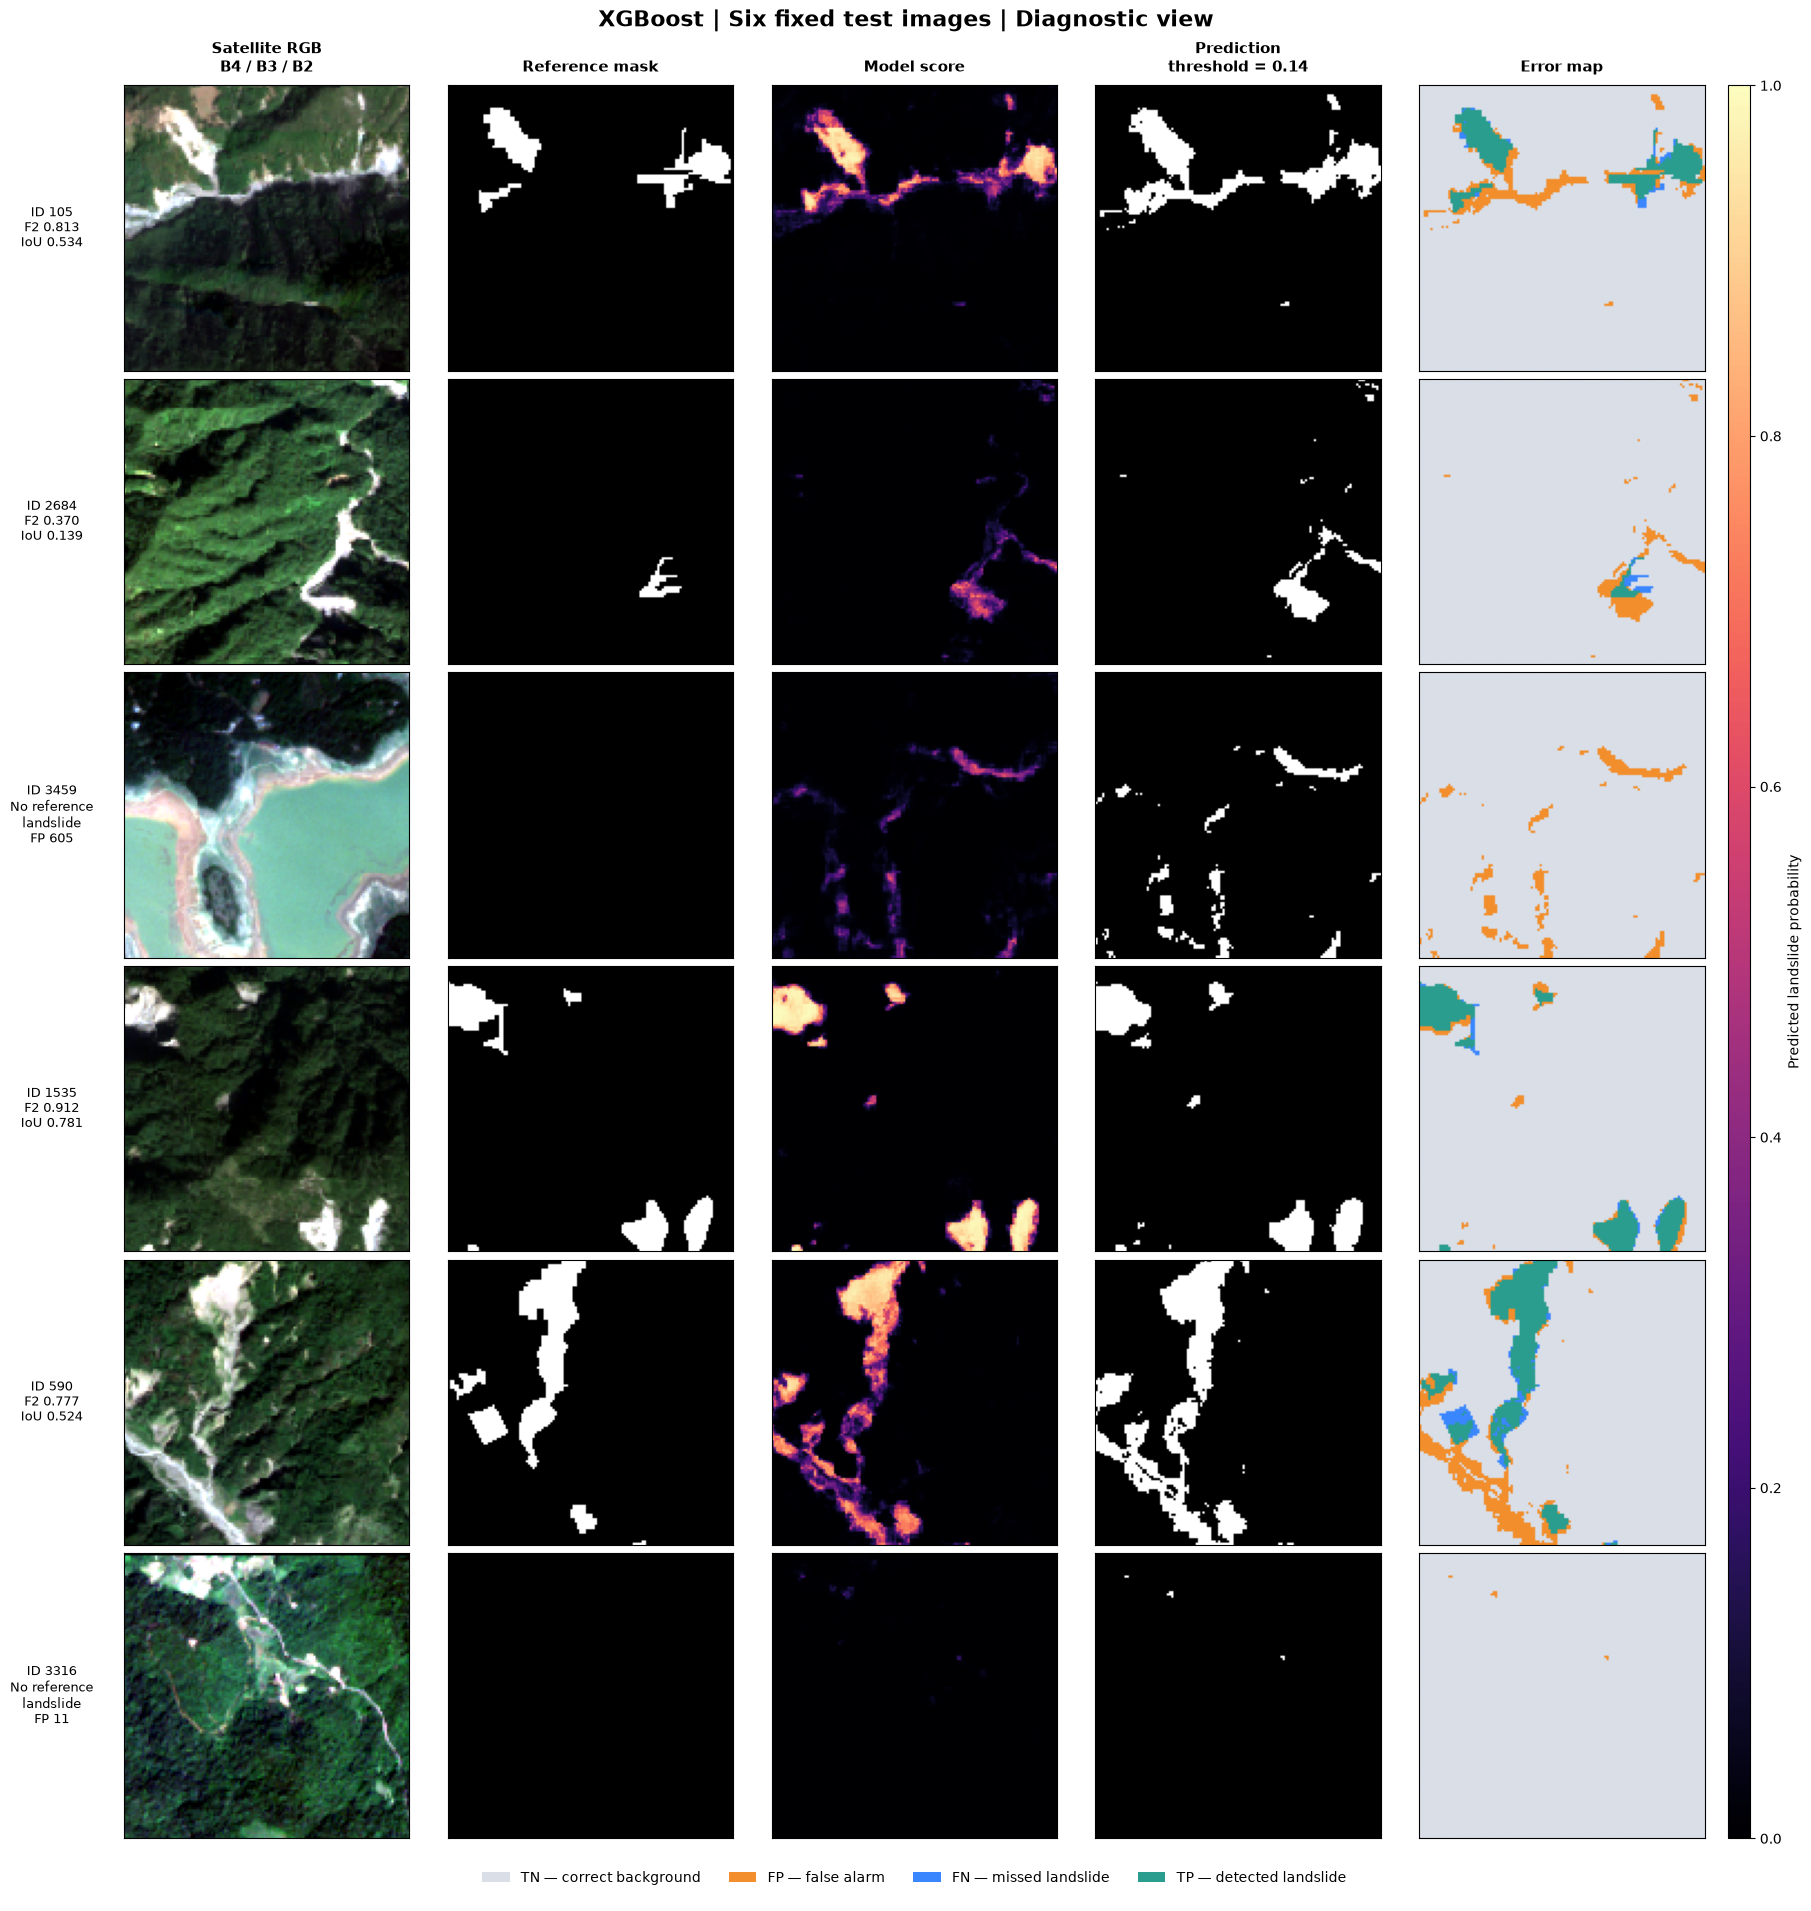

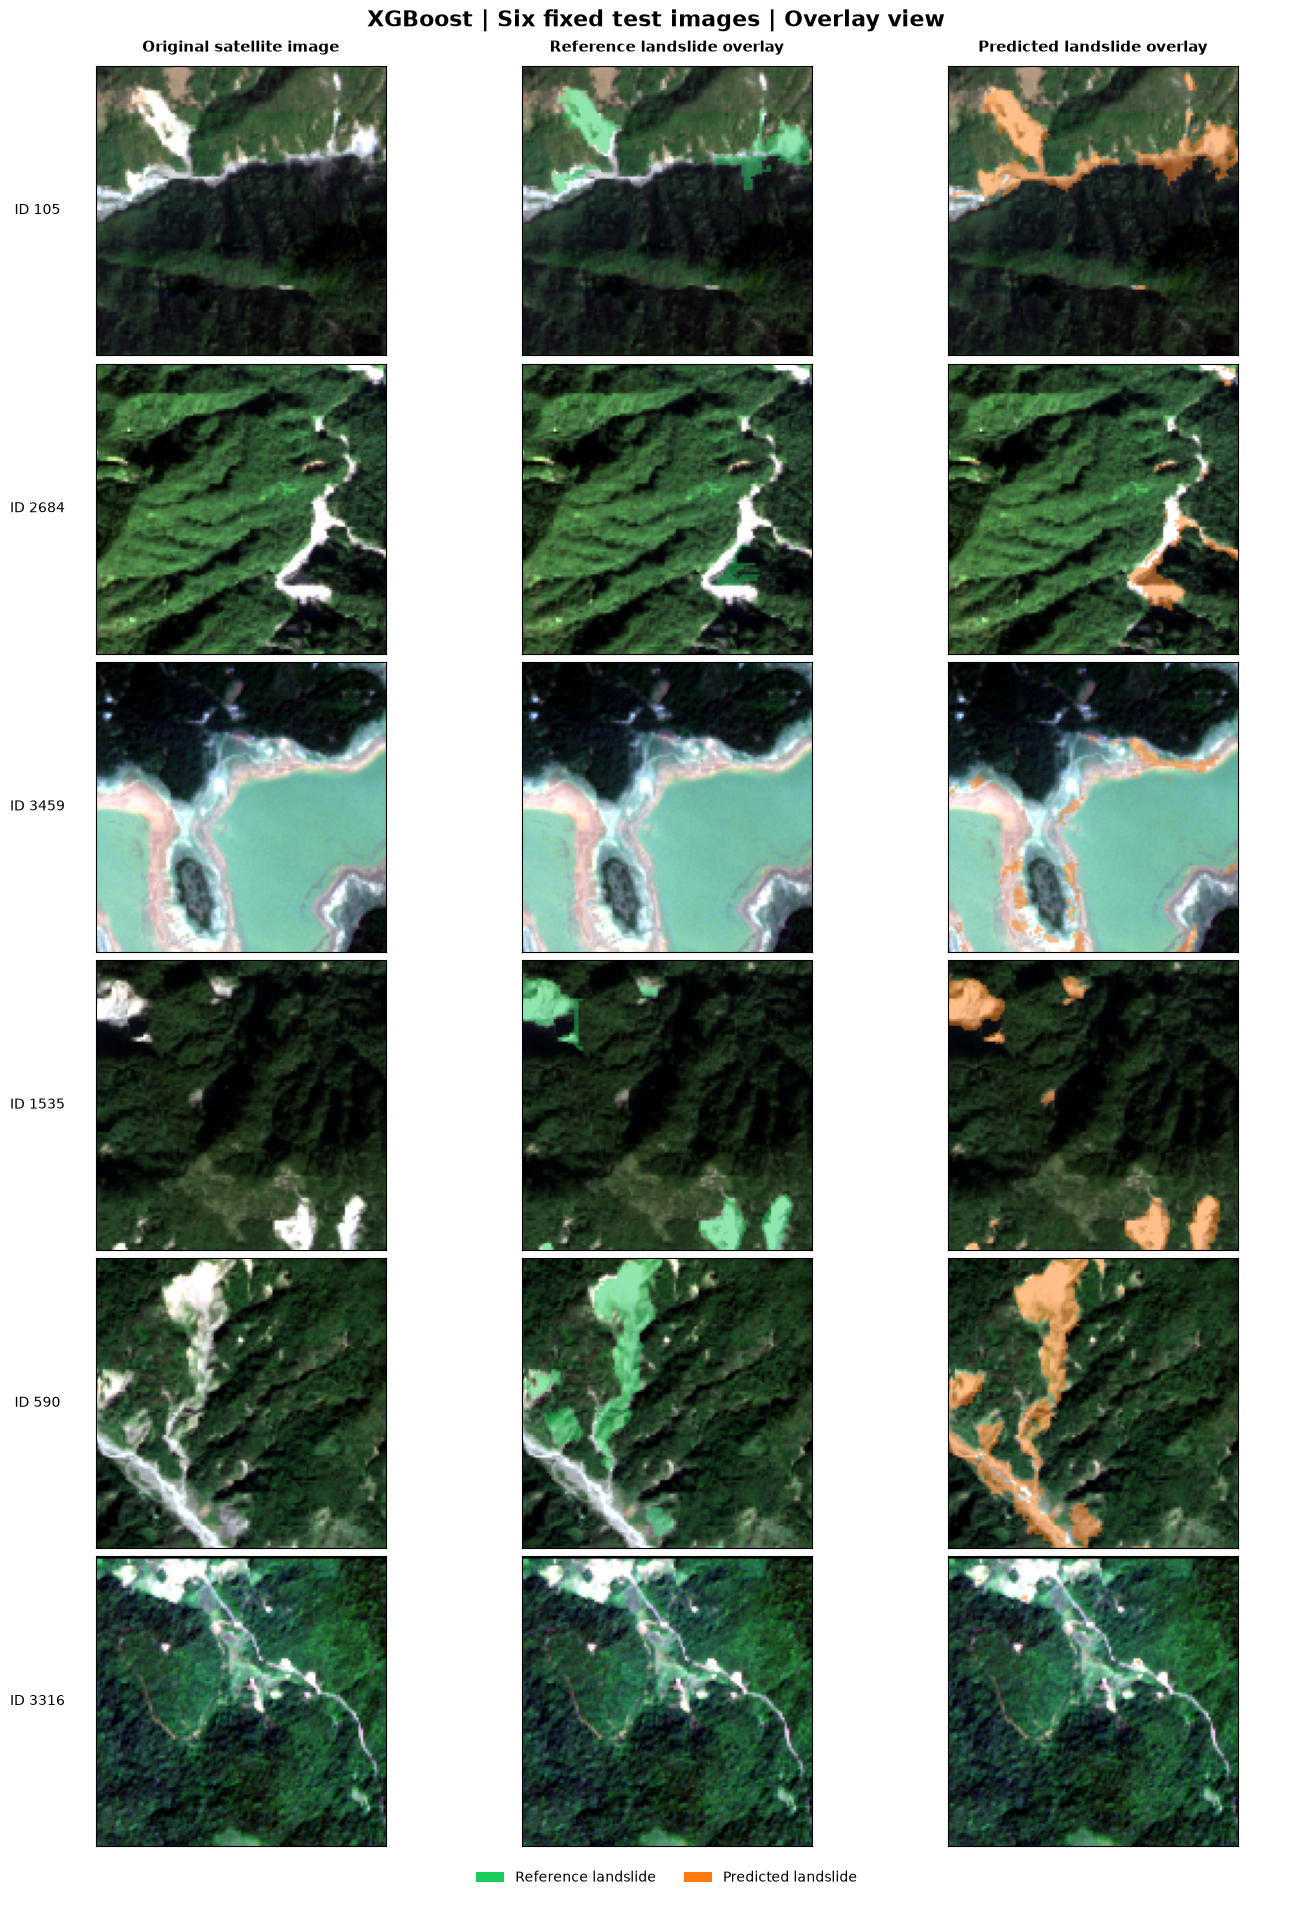

Image order: ['105', '2684', '3459', '1535', '590', '3316']
Saved: C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\xgboost\checkpoints\final_model_v1\secondary_test_v1\plots\six_fixed_images


In [18]:
# XGBoost — Step 12: six fixed secondary-test images (same IDs as HGB).
# Uses saved predictions only. No model training or new predictions.

from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

XGB_FIXED_IMAGE_IDS = ["105", "2684", "3459", "1535", "590", "3316"]
locked_threshold = float(xgb_secondary_result["threshold"])

test_row = {str(image_id): row
            for row, image_id in enumerate(xgb_secondary_result["ordered_image_ids"])}
missing = [image_id for image_id in XGB_FIXED_IMAGE_IDS if image_id not in test_row]
assert not missing, f"IDs not in the secondary test: {missing}"

scores = np.load(xgb_secondary_result["scores_path"], mmap_mode="r")
labels = np.load(xgb_secondary_result["labels_path"], mmap_mode="r")
rgb_channels = [xgb_feature_names.index(band) for band in ("B4", "B3", "B2")]

examples = []
for image_id in XGB_FIXED_IMAGE_IDS:
    row = test_row[image_id]
    features, reference_flat = xgb_load_source_pair(image_id)
    reference = reference_flat.reshape(128, 128).astype(bool)

    # Saved labels must match the original source mask.
    assert np.array_equal(
        np.asarray(labels[row]).reshape(128, 128).astype(bool), reference
    ), f"Saved labels do not match the source mask for image {image_id}."

    probability = np.asarray(scores[row], dtype=np.float64).reshape(128, 128)
    prediction = probability >= locked_threshold

    # RGB from B4/B3/B2 with a per-channel 2nd–98th percentile stretch.
    rgb_raw = features[:, rgb_channels].reshape(128, 128, 3)
    rgb = np.zeros_like(rgb_raw, dtype=np.float32)
    for channel in range(3):
        low, high = np.percentile(rgb_raw[:, :, channel], [2, 98])
        if high > low:
            rgb[:, :, channel] = np.clip(
                (rgb_raw[:, :, channel] - low) / (high - low), 0, 1
            )

    tp = int(np.count_nonzero(prediction & reference))
    fp = int(np.count_nonzero(prediction & ~reference))
    fn = int(np.count_nonzero(~prediction & reference))

    if reference.any():
        label_text = (f"ID {image_id}\nF2 {5 * tp / (5 * tp + 4 * fn + fp):.3f}\n"
                      f"IoU {tp / (tp + fp + fn):.3f}")
    else:
        label_text = f"ID {image_id}\nNo reference\nlandslide\nFP {fp}"

    # Error classes: TN = 0, FP = 1, FN = 2, TP = 3.
    error_map = np.zeros((128, 128), dtype=np.uint8)
    error_map[prediction & ~reference] = 1
    error_map[~prediction & reference] = 2
    error_map[prediction & reference] = 3

    examples.append({
        "image_id": image_id, "rgb": rgb, "reference": reference,
        "probability": probability, "prediction": prediction,
        "error_map": error_map, "label_text": label_text,
    })

del scores, labels

XGB_EXAMPLE_DIR = XGB_TEST_PLOT_DIR / "six_fixed_images"
XGB_EXAMPLE_DIR.mkdir(parents=True, exist_ok=True)

error_colors = ["#D9DEE7", "#F28E2B", "#3A86FF", "#2A9D8F"]
error_cmap = ListedColormap(error_colors)
error_norm = BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 3.5], error_cmap.N)

with plt.rc_context({"font.size": 10, "axes.titlesize": 11}):
    # --------------------------------------------------------
    # Figure 1: five diagnostic panels per image.
    # --------------------------------------------------------
    fig = plt.figure(figsize=(18, 19), layout="constrained")
    grid = fig.add_gridspec(7, 6, width_ratios=[1, 1, 1, 1, 1, 0.07],
                            height_ratios=[1, 1, 1, 1, 1, 1, 0.16])
    axes = np.array([[fig.add_subplot(grid[r, c]) for c in range(5)] for r in range(6)])
    colorbar_axis = fig.add_subplot(grid[:6, 5])
    legend_axis = fig.add_subplot(grid[6, :5])
    legend_axis.axis("off")

    titles = ["Satellite RGB\nB4 / B3 / B2", "Reference mask", "Model score",
              f"Prediction\nthreshold = {locked_threshold:.2f}", "Error map"]
    for column, title in enumerate(titles):
        axes[0, column].set_title(title, pad=10, fontweight="bold")

    for row, item in enumerate(examples):
        axes[row, 0].imshow(item["rgb"])
        axes[row, 1].imshow(item["reference"], cmap="gray", vmin=0, vmax=1)
        score_artist = axes[row, 2].imshow(item["probability"], cmap="magma", vmin=0, vmax=1)
        axes[row, 3].imshow(item["prediction"], cmap="gray", vmin=0, vmax=1)
        axes[row, 4].imshow(item["error_map"], cmap=error_cmap, norm=error_norm)
        axes[row, 0].set_ylabel(item["label_text"], rotation=0, labelpad=52,
                                va="center", fontsize=9)
        for axis in axes[row]:
            axis.set_xticks([])
            axis.set_yticks([])

    fig.colorbar(score_artist, cax=colorbar_axis).set_label("Predicted landslide probability")
    legend_axis.legend(
        handles=[Patch(facecolor=error_colors[0], label="TN — correct background"),
                 Patch(facecolor=error_colors[1], label="FP — false alarm"),
                 Patch(facecolor=error_colors[2], label="FN — missed landslide"),
                 Patch(facecolor=error_colors[3], label="TP — detected landslide")],
        loc="center", ncol=4, frameon=False, fontsize=10,
    )
    fig.suptitle("XGBoost | Six fixed test images | Diagnostic view",
                 fontsize=16, fontweight="bold")
    for extension in ("png", "pdf"):
        fig.savefig(XGB_EXAMPLE_DIR / f"xgb_six_image_diagnostics.{extension}",
                    dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

    # --------------------------------------------------------
    # Figure 2: original RGB and reference/prediction overlays.
    # --------------------------------------------------------
    fig = plt.figure(figsize=(13, 19), layout="constrained")
    grid = fig.add_gridspec(7, 3, height_ratios=[1, 1, 1, 1, 1, 1, 0.16])
    overlay_axes = np.array([[fig.add_subplot(grid[r, c]) for c in range(3)] for r in range(6)])
    overlay_legend_axis = fig.add_subplot(grid[6, :])
    overlay_legend_axis.axis("off")

    for column, title in enumerate(["Original satellite image",
                                    "Reference landslide overlay",
                                    "Predicted landslide overlay"]):
        overlay_axes[0, column].set_title(title, pad=10, fontweight="bold")

    green = np.array([0.10, 0.80, 0.35], dtype=np.float32)
    orange = np.array([1.00, 0.48, 0.05], dtype=np.float32)
    alpha = 0.48

    for row, item in enumerate(examples):
        reference_overlay = item["rgb"].copy()
        reference_overlay[item["reference"]] = (
            (1 - alpha) * reference_overlay[item["reference"]] + alpha * green
        )
        prediction_overlay = item["rgb"].copy()
        prediction_overlay[item["prediction"]] = (
            (1 - alpha) * prediction_overlay[item["prediction"]] + alpha * orange
        )
        for column, visual in enumerate((item["rgb"], reference_overlay, prediction_overlay)):
            overlay_axes[row, column].imshow(visual)
            overlay_axes[row, column].set_xticks([])
            overlay_axes[row, column].set_yticks([])
        overlay_axes[row, 0].set_ylabel(f"ID {item['image_id']}", rotation=0,
                                        labelpad=42, va="center", fontsize=10)

    overlay_legend_axis.legend(
        handles=[Patch(facecolor=green, label="Reference landslide"),
                 Patch(facecolor=orange, label="Predicted landslide")],
        loc="center", ncol=2, frameon=False, fontsize=10,
    )
    fig.suptitle("XGBoost | Six fixed test images | Overlay view",
                 fontsize=16, fontweight="bold")
    for extension in ("png", "pdf"):
        fig.savefig(XGB_EXAMPLE_DIR / f"xgb_six_image_overlays.{extension}",
                    dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

print("Image order:", XGB_FIXED_IMAGE_IDS)
print("Saved:", XGB_EXAMPLE_DIR)

**Result — six fixed test images.** The same six images as in the HGB analysis illustrate typical XGBoost behaviour.

- **Compact, bright landslide scars are detected very well.** Image 1535 (F2 0.912, IoU 0.781) shows almost complete detection with sharp boundaries, and the larger landslides in images 105 (F2 0.813) and 590 (F2 0.777) are largely captured.
- **False positives occur mainly on bright, bare surfaces that are spectrally similar to fresh landslide scars.** In images 105 and 590, river channels and debris-covered valley floors next to the landslides are partly classified as landslide, which extends the predicted areas and lowers IoU (0.534 and 0.524). In image 3459, which contains no reference landslide, 605 pixels along the bare, sediment-covered banks of a reservoir are falsely detected.
- **Small landslides are difficult.** In image 2684, the small landslide is only partly detected, while a bright stream channel nearby is predicted as landslide (F2 0.370, IoU 0.139).
- **Vegetated scenes without landslides produce very few false alarms.** Image 3316 has only 13 false-positive pixels, despite a bright road and river line.
- **Some reference masks contain simplified geometric shapes** (for example, the rectangular block in image 105 and the square polygon in image 590). Such annotation simplifications can lower the measured precision and IoU even when the model follows the visible scar.

These examples confirm that the remaining errors are mostly caused by spectral confusion between landslides and other bare surfaces. A pixel-based classifier cannot resolve this without spatial context, such as shape, neighbourhood or texture.

,image_id,reference_landslide_pixels,predicted_landslide_pixels,TP,FP,FN,TN,F2,Precision,Recall,IoU,reference_coverage_percent,false_positive_rate_percent
0,503,13,458,0,458,13,15913,0.0,0.0,0.0,0.0,0.0793,2.7976
1,3428,41,267,0,267,41,16076,0.0,0.0,0.0,0.0,0.2502,1.6337
2,2322,2,172,0,172,2,16210,0.0,0.0,0.0,0.0,0.0122,1.0499
3,656,4,78,0,78,4,16302,0.0,0.0,0.0,0.0,0.0244,0.4762
4,68,81,59,0,59,81,16244,0.0,0.0,0.0,0.0,0.4944,0.3619
...,...,...,...,...,...,...,...,...,...,...,...,...,...
755,3201,0,0,0,0,0,16384,NaN,NaN,NaN,NaN,0.0000,0.0000
756,3668,0,0,0,0,0,16384,NaN,NaN,NaN,NaN,0.0000,0.0000
757,1626,0,19,0,19,0,16365,NaN,0.0,NaN,NaN,0.0000,0.1160
758,2377,0,0,0,0,0,16384,NaN,NaN,NaN,NaN,0.0000,0.0000


Test images: 760
Images with reference landslides: 446
Images without reference landslides: 314
Mean F2 on images with reference landslides: 0.6573
Median F2 on images with reference landslides: 0.7114
Positive images with F2 = 0 (landslide completely missed): 7
Median false-positive pixels on images without reference landslides: 6
Images without landslides and with zero false positives: 111


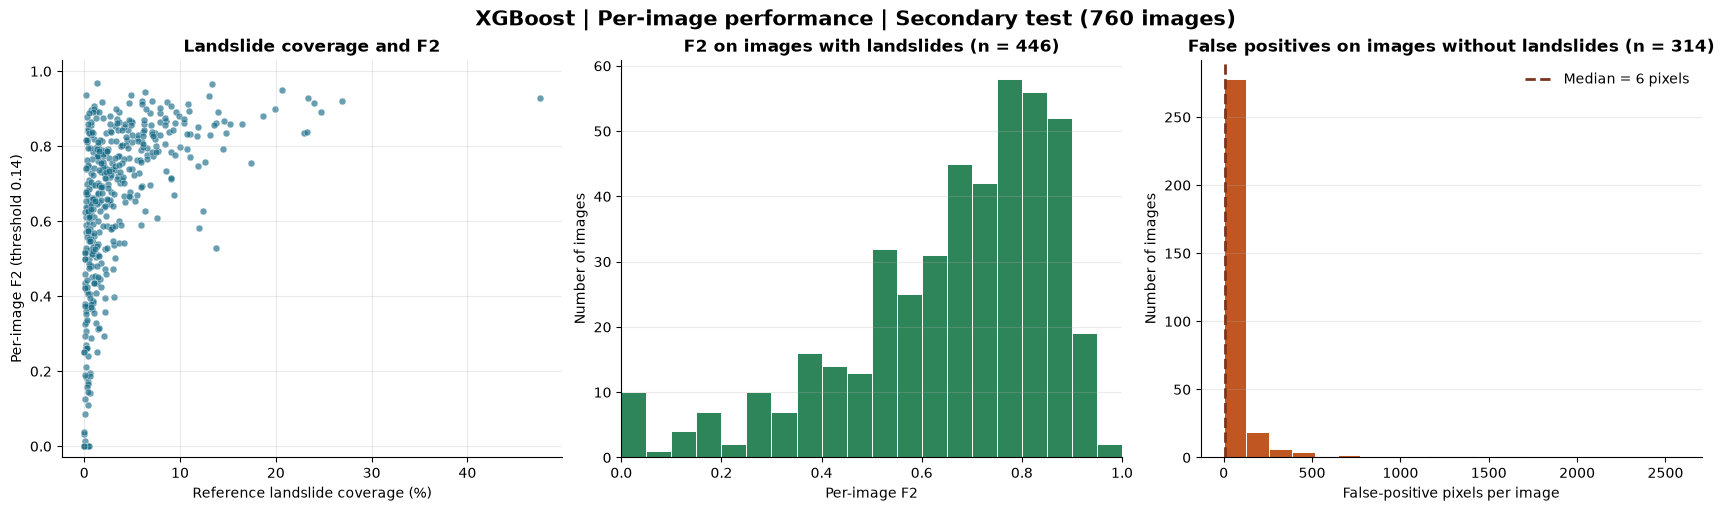

Saved: C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\xgboost\checkpoints\final_model_v1\secondary_test_v1\per_image


In [19]:
# XGBoost — Step 13: per-image secondary-test analysis.
# Uses the saved per-image confusion counts only. No prediction, no threshold change.

from IPython.display import display as show_table


def xgb_per_image_metrics(counts_table):
    """Per-image metrics with undefined values set to NaN, not 0."""
    table = counts_table.copy()
    table["image_id"] = table["image_id"].astype(str)

    tp = table["TP"].to_numpy(dtype=float)
    fp = table["FP"].to_numpy(dtype=float)
    fn = table["FN"].to_numpy(dtype=float)
    tn = table["TN"].to_numpy(dtype=float)
    reference = tp + fn
    predicted = tp + fp
    negatives = tn + fp
    has_reference = reference > 0

    with np.errstate(divide="ignore", invalid="ignore"):
        table["reference_landslide_pixels"] = reference.astype(np.int64)
        table["predicted_landslide_pixels"] = predicted.astype(np.int64)
        table["has_reference_landslide"] = has_reference
        table["F2"] = np.where(has_reference, 5 * tp / (5 * tp + 4 * fn + fp), np.nan)
        table["Precision"] = np.where(predicted > 0, tp / predicted, np.nan)
        table["Recall"] = np.where(has_reference, tp / reference, np.nan)
        table["IoU"] = np.where(has_reference, tp / (tp + fp + fn), np.nan)
        table["reference_coverage_percent"] = (
            100 * reference / table["n_pixels"].to_numpy(dtype=float)
        )
        table["false_positive_rate_percent"] = np.where(
            negatives > 0, 100 * fp / negatives, np.nan
        )
    return table


xgb_test_per_image = xgb_per_image_metrics(xgb_secondary_result["per_image"])

# Consistency with the saved pooled test result.
assert xgb_test_per_image["image_id"].tolist() == [
    str(value) for value in xgb_secondary_result["ordered_image_ids"]
]
for name in ("TN", "FP", "FN", "TP"):
    assert int(xgb_test_per_image[name].sum()) == xgb_secondary_result["counts"][name]
assert int(xgb_test_per_image["n_pixels"].sum()) == xgb_secondary_result["n_pixels"]

positive_images = xgb_test_per_image["has_reference_landslide"].to_numpy()
negative_images = ~positive_images

display_columns = [
    "image_id", "reference_landslide_pixels", "predicted_landslide_pixels",
    "TP", "FP", "FN", "TN", "F2", "Precision", "Recall", "IoU",
    "reference_coverage_percent", "false_positive_rate_percent",
]
show_table(
    xgb_test_per_image[display_columns]
    .sort_values("F2", na_position="last")
    .reset_index(drop=True)
    .round(4)
)

print(f"Test images: {len(xgb_test_per_image)}")
print(f"Images with reference landslides: {positive_images.sum()}")
print(f"Images without reference landslides: {negative_images.sum()}")
print(f"Mean F2 on images with reference landslides: "
      f"{xgb_test_per_image.loc[positive_images, 'F2'].mean():.4f}")
print(f"Median F2 on images with reference landslides: "
      f"{xgb_test_per_image.loc[positive_images, 'F2'].median():.4f}")
print(f"Positive images with F2 = 0 (landslide completely missed): "
      f"{int((xgb_test_per_image.loc[positive_images, 'F2'] == 0).sum())}")
print(f"Median false-positive pixels on images without reference landslides: "
      f"{xgb_test_per_image.loc[negative_images, 'FP'].median():,.0f}")
print(f"Images without landslides and with zero false positives: "
      f"{int((xgb_test_per_image.loc[negative_images, 'FP'] == 0).sum())}")

XGB_PER_IMAGE_DIR = XGB_TEST_DIR / "per_image"
XGB_PER_IMAGE_DIR.mkdir(parents=True, exist_ok=True)
xgb_test_per_image.to_csv(XGB_PER_IMAGE_DIR / "xgb_test_per_image.csv", index=False)

with plt.rc_context({
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
}):
    fig, axes = plt.subplots(1, 3, figsize=(17, 5), constrained_layout=True)

    axes[0].scatter(
        xgb_test_per_image.loc[positive_images, "reference_coverage_percent"],
        xgb_test_per_image.loc[positive_images, "F2"],
        s=24, alpha=0.65, color="#176B87", edgecolor="white", linewidth=0.35,
    )
    axes[0].set_title("Landslide coverage and F2")
    axes[0].set_xlabel("Reference landslide coverage (%)")
    axes[0].set_ylabel(f"Per-image F2 (threshold {xgb_test_threshold:.2f})")
    axes[0].set_ylim(-0.03, 1.03)
    axes[0].grid(True, alpha=0.25)

    axes[1].hist(
        xgb_test_per_image.loc[positive_images, "F2"],
        bins=np.linspace(0, 1, 21),
        color="#2F855A", edgecolor="white", linewidth=0.7,
    )
    axes[1].set_title(f"F2 on images with landslides (n = {positive_images.sum()})")
    axes[1].set_xlabel("Per-image F2")
    axes[1].set_ylabel("Number of images")
    axes[1].set_xlim(0, 1)
    axes[1].grid(axis="y", alpha=0.25)

    negative_fp = xgb_test_per_image.loc[negative_images, "FP"]
    axes[2].hist(negative_fp, bins=20, color="#C05621", edgecolor="white", linewidth=0.7)
    axes[2].axvline(
        negative_fp.median(), color="#7B341E", linewidth=2, linestyle="--",
        label=f"Median = {negative_fp.median():,.0f} pixels",
    )
    axes[2].set_title(
        f"False positives on images without landslides (n = {negative_images.sum()})"
    )
    axes[2].set_xlabel("False-positive pixels per image")
    axes[2].set_ylabel("Number of images")
    axes[2].legend(frameon=False)
    axes[2].grid(axis="y", alpha=0.25)

    fig.suptitle("XGBoost | Per-image performance | Secondary test (760 images)",
                 fontsize=15, fontweight="bold")
    for extension in ("png", "pdf"):
        fig.savefig(XGB_PER_IMAGE_DIR / f"xgb_test_per_image.{extension}",
                    dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

print("Saved:", XGB_PER_IMAGE_DIR)

**Result — per-image performance on the secondary test.** Of the 760 test images, 446 contain reference landslides and 314 do not. On images with landslides, XGBoost reaches a mean per-image F2 of 0.657 (median 0.711), lower than the pooled pixel-level F2 (0.765) because every image counts equally here, including images with very small landslides. Performance depends strongly on landslide size: images with more than about 5% landslide coverage mostly reach F2 between 0.7 and 0.95, whereas images with very small landslides (below about 2% coverage) range from complete misses to very good detection. The F2 distribution is skewed towards high values, with most positive images between 0.6 and 0.9. In 7 images the landslide was missed completely (F2 = 0); these contain only a few to a few dozen landslide pixels (for example 2, 4, 13, 41, and 81 pixels), and in most of them nearby bright surfaces were detected instead.

On images without landslides, false alarms are usually small: the median is 6 false-positive pixels per image, 111 of the 314 negative images (35%) have no false positives at all, and most have fewer than about 100. A small number of images contain several hundred false-positive pixels, and one image reaches about 2,600, which corresponds to the bright bare-surface confusion seen in the example images. These per-image results are very similar to HGB (mean F2 0.654, median 5 false-positive pixels).

Sampling pixels from 760 test images...
  Loaded 100/760 images
  Loaded 200/760 images
  Loaded 300/760 images
  Loaded 400/760 images
  Loaded 500/760 images
  Loaded 600/760 images
  Loaded 700/760 images
  Loaded 760/760 images
Evaluation pixels: 1,556,480 | landslide pixels: 32,945 (2.12%)
Baseline prediction...
Baseline on sample | F2 = 0.7626 (full test: 0.7651) | AP = 0.7680
       B1 | repeat 1/3 | F2 = 0.5379 | AP = 0.4903 | 11 s
       B1 | repeat 2/3 | F2 = 0.5384 | AP = 0.4935 | 16 s
       B1 | repeat 3/3 | F2 = 0.5368 | AP = 0.4922 | 19 s
       B2 | repeat 1/3 | F2 = 0.7363 | AP = 0.7145 | 23 s
       B2 | repeat 2/3 | F2 = 0.7368 | AP = 0.7149 | 26 s
       B2 | repeat 3/3 | F2 = 0.7360 | AP = 0.7148 | 29 s
       B3 | repeat 1/3 | F2 = 0.7617 | AP = 0.7632 | 32 s
       B3 | repeat 2/3 | F2 = 0.7613 | AP = 0.7632 | 36 s
       B3 | repeat 3/3 | F2 = 0.7613 | AP = 0.7633 | 39 s
       B4 | repeat 1/3 | F2 = 0.3236 | AP = 0.2765 | 42 s
       B4 | repeat 2/3 | F2 = 0.32

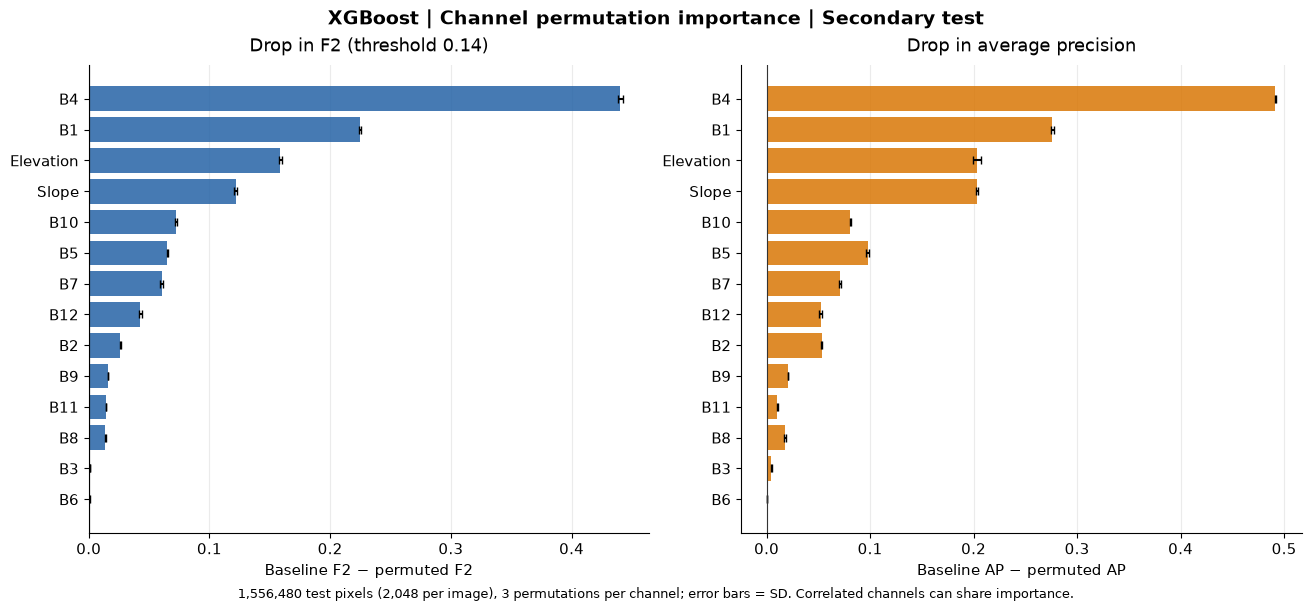


Saved: C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\xgboost\checkpoints\final_model_v1\permutation_importance_v1
Diagnostic only — the model and threshold were not changed.


In [20]:
# XGBoost — Step 14: channel permutation importance on the secondary test.
# Locked final model and locked threshold. No training, tuning, or threshold changes.
# Same sampling rule and seed as HGB, so the test-pixel sample is identical.

import os
from sklearn.metrics import average_precision_score

XGB_PI_PIXELS_PER_IMAGE = 2048
XGB_PI_REPEATS = 3
XGB_PI_SEED = 43

xgb_pi_threshold = float(xgb_final_specification["threshold"])
xgb_pi_test_ids = list(xgb_secondary_test_ids)

assert xgb_pi_threshold == 0.14
assert len(xgb_pi_test_ids) == len(set(xgb_pi_test_ids)) == 760
assert set(xgb_pi_test_ids).isdisjoint(xgb_development_id_set)
assert xgb_final_model.n_features_in_ == len(xgb_feature_names) == 14

XGB_PI_DIR = XGB_FINAL_MODEL_DIR / "permutation_importance_v1"
XGB_PI_DIR.mkdir(parents=True, exist_ok=True)
xgb_pi_sample_file = XGB_PI_DIR / "sample.npz"
xgb_pi_results_file = XGB_PI_DIR / "results.joblib"

xgb_pi_specification = {
    "version": "xgb_channel_permutation_importance_v1",
    "locked_model": xgb_final_specification,
    "test_ids": xgb_pi_test_ids,
    "pixels_per_image": XGB_PI_PIXELS_PER_IMAGE,
    "repeats": XGB_PI_REPEATS,
    "seed": XGB_PI_SEED,
    "features": xgb_feature_names,
}

# ------------------------------------------------------------
# 1. Build (or restore) the fixed test-pixel sample.
# ------------------------------------------------------------
if xgb_pi_sample_file.is_file():
    with np.load(xgb_pi_sample_file) as data:
        xgb_pi_X = np.array(data["X"])
        xgb_pi_y = np.array(data["y"])
    print("Saved test-pixel sample restored.")
else:
    rng = np.random.default_rng(XGB_PI_SEED)
    X_parts, y_parts = [], []
    print("Sampling pixels from 760 test images...", flush=True)
    for index, image_id in enumerate(xgb_pi_test_ids, start=1):
        image_X, image_y = xgb_load_source_pair(image_id)
        rows = rng.choice(image_X.shape[0], size=XGB_PI_PIXELS_PER_IMAGE, replace=False)
        X_parts.append(image_X[rows])
        y_parts.append(image_y[rows])
        if index % 100 == 0 or index == 760:
            print(f"  Loaded {index}/760 images", flush=True)

    xgb_pi_X = np.concatenate(X_parts).astype(np.float32)
    xgb_pi_y = np.concatenate(y_parts).astype(np.uint8)
    del X_parts, y_parts

    temporary = XGB_PI_DIR / "sample_tmp.npz"
    np.savez(temporary, X=xgb_pi_X, y=xgb_pi_y)
    os.replace(temporary, xgb_pi_sample_file)

assert xgb_pi_X.shape == (760 * XGB_PI_PIXELS_PER_IMAGE, 14)
assert np.isfinite(xgb_pi_X).all()

xgb_pi_positive = xgb_pi_y == 1
print(f"Evaluation pixels: {len(xgb_pi_y):,} | landslide pixels: "
      f"{int(xgb_pi_positive.sum()):,} ({xgb_pi_positive.mean() * 100:.2f}%)")


def xgb_pi_evaluate(X_eval):
    """F2 at the locked threshold and average precision."""
    probability = xgb_final_model.predict_proba(X_eval)[:, 1].astype(np.float64)
    predicted = probability >= xgb_pi_threshold
    tp = np.count_nonzero(predicted & xgb_pi_positive)
    fp = np.count_nonzero(predicted & ~xgb_pi_positive)
    fn = np.count_nonzero(~predicted & xgb_pi_positive)
    return {
        "F2": float(xgb_ratio(5 * tp, 5 * tp + 4 * fn + fp)),
        "AP": float(average_precision_score(xgb_pi_y, probability)),
    }


# ------------------------------------------------------------
# 2. Baseline and channel permutations (resumable).
# ------------------------------------------------------------
if xgb_pi_results_file.is_file():
    xgb_pi_results = joblib.load(xgb_pi_results_file)
    assert xgb_pi_results["specification"] == xgb_pi_specification
else:
    xgb_pi_results = {"specification": xgb_pi_specification, "baseline": None, "permuted": {}}

if xgb_pi_results["baseline"] is None:
    print("Baseline prediction...", flush=True)
    xgb_pi_results["baseline"] = xgb_pi_evaluate(xgb_pi_X)
    xgb_atomic_joblib_dump(xgb_pi_results, xgb_pi_results_file)

baseline = xgb_pi_results["baseline"]
print(f"Baseline on sample | F2 = {baseline['F2']:.4f} "
      f"(full test: {xgb_secondary_result['metrics']['F2']:.4f}) | AP = {baseline['AP']:.4f}")

started = time.perf_counter()
for column, name in enumerate(xgb_feature_names):
    for repeat in range(XGB_PI_REPEATS):
        key = f"{name}|{repeat}"
        if key in xgb_pi_results["permuted"]:
            continue

        # Seed per channel and repeat, so resuming gives identical permutations.
        rng = np.random.default_rng([XGB_PI_SEED, column, repeat])
        original = xgb_pi_X[:, column].copy()
        xgb_pi_X[:, column] = original[rng.permutation(len(original))]
        try:
            xgb_pi_results["permuted"][key] = xgb_pi_evaluate(xgb_pi_X)
        finally:
            xgb_pi_X[:, column] = original   # always restore the channel

        xgb_atomic_joblib_dump(xgb_pi_results, xgb_pi_results_file)
        result = xgb_pi_results["permuted"][key]
        print(f"{name:>9} | repeat {repeat + 1}/{XGB_PI_REPEATS} | F2 = {result['F2']:.4f} | "
              f"AP = {result['AP']:.4f} | {time.perf_counter() - started:.0f} s", flush=True)

# ------------------------------------------------------------
# 3. Summary table.
# ------------------------------------------------------------
rows = []
for name in xgb_feature_names:
    runs = [xgb_pi_results["permuted"][f"{name}|{r}"] for r in range(XGB_PI_REPEATS)]
    f2_drop = np.array([baseline["F2"] - run["F2"] for run in runs])
    ap_drop = np.array([baseline["AP"] - run["AP"] for run in runs])
    rows.append({
        "Channel": name,
        "F2_drop_mean": f2_drop.mean(), "F2_drop_sd": f2_drop.std(ddof=1),
        "AP_drop_mean": ap_drop.mean(), "AP_drop_sd": ap_drop.std(ddof=1),
    })

xgb_pi_table = (pd.DataFrame(rows)
                .sort_values("F2_drop_mean", ascending=False)
                .reset_index(drop=True))
xgb_pi_table.to_csv(XGB_PI_DIR / "channel_importance.csv", index=False)

print("\nCHANNEL PERMUTATION IMPORTANCE (drop from baseline; larger = more important)")
print(xgb_pi_table.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# ------------------------------------------------------------
# 4. Figure.
# ------------------------------------------------------------
with plt.rc_context({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False}):
    fig, axes = plt.subplots(1, 2, figsize=(13, 6), constrained_layout=True)
    order = xgb_pi_table.iloc[::-1]   # most important at the top

    for ax, metric, color, title in (
        (axes[0], "F2", "#2563A6", f"Drop in F2 (threshold {xgb_pi_threshold:.2f})"),
        (axes[1], "AP", "#D97706", "Drop in average precision"),
    ):
        ax.barh(order["Channel"], order[f"{metric}_drop_mean"],
                xerr=order[f"{metric}_drop_sd"], color=color, alpha=0.85, capsize=3)
        ax.axvline(0, color="#333333", linewidth=0.8)
        ax.set_xlabel(f"Baseline {metric} − permuted {metric}")
        ax.set_title(title, pad=10)
        ax.grid(axis="x", alpha=0.25)
        ax.set_axisbelow(True)

    fig.suptitle("XGBoost | Channel permutation importance | Secondary test",
                 fontsize=14, fontweight="bold")
    fig.supxlabel(f"{len(xgb_pi_y):,} test pixels ({XGB_PI_PIXELS_PER_IMAGE:,} per image), "
                  f"{XGB_PI_REPEATS} permutations per channel; error bars = SD. "
                  "Correlated channels can share importance.", fontsize=9)
    for extension in ("png", "pdf"):
        fig.savefig(XGB_PI_DIR / f"xgb_channel_permutation_importance.{extension}",
                    dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

print("\nSaved:", XGB_PI_DIR)
print("Diagnostic only — the model and threshold were not changed.")

**Result — channel permutation importance.** Shuffling single channels on 1,556,480 test pixels (the same sample as for HGB; 3 permutations each) shows that XGBoost relies most on **B4**: permuting it lowers F2 by about 0.44 (from 0.763 to about 0.32) and average precision by about 0.49. The next most important inputs are **B1** (F2 drop ≈ 0.22), **elevation** (≈ 0.16) and **slope** (≈ 0.12); both terrain features therefore add clear information beyond the spectral bands. B10, B5, B7, and B12 have moderate effects (≈ 0.04–0.07), B2 a small effect (≈ 0.03), while B9, B11, B8, and especially B3 and B6 have almost no individual effect (< 0.02). The ranking is nearly identical for F2 and average precision, and the very small error bars show that it is stable.

The ranking agrees closely with HGB: the same four inputs lead (B4, B1, elevation, slope), and the same channels (B3, B6) are least important. XGBoost depends somewhat more on B4 and B1 (F2 drops 0.44 and 0.22 vs. 0.41 and 0.19 for HGB) and less on B7 (≈ 0.06 vs. 0.11). The dominance of B4 (red) is physically plausible, because fresh landslide scars expose bright bare soil and rock that contrast with vegetation. The high importance of B1 and B10, which are 60 m atmospheric bands, likely reflects scene-level differences between study areas rather than landslide-specific properties. Low importance of B3 and B6 indicates redundancy with correlated neighbouring bands, not irrelevance.

In [21]:
# XGBoost — Step 15: export all XGBoost results in the standard comparison format.
# Reads saved results only. No training, prediction, or threshold change.

import json

XGB_EXPORT_DIR = XGB_PROJECT_PATH / "artifacts" / "classifier_comparison" / "xgboost"
XGB_EXPORT_DIR.mkdir(parents=True, exist_ok=True)

metric_names = [
    "F2", "Precision", "Recall", "Specificity", "IoU",
    "ROC_AUC", "Average_precision", "Brier_score", "Log_loss",
]


def xgb_with_model_column(table):
    """Copy a table and put a Model column first."""
    table = table.copy()
    if "Model" in table.columns:
        table = table.drop(columns="Model")
    table.insert(0, "Model", "XGBoost")
    return table


# 1. Outer folds.
xgb_export_folds = xgb_with_model_column(
    xgb_outer_metrics_table[["Outer_fold", "Threshold"] + metric_names + ["Fit_seconds"]]
    .sort_values("Outer_fold")
    .reset_index(drop=True)
)

# 2. Per-image tables (needed for paired comparisons between classifiers).
xgb_export_outer_per_image = xgb_with_model_column(
    xgb_per_image_metrics(xgb_pooled_outer_summary["per_image"])
)
xgb_export_test_per_image = xgb_with_model_column(xgb_test_per_image)

assert len(xgb_export_outer_per_image) == 3039
assert set(xgb_export_outer_per_image["image_id"]) == xgb_development_id_set
assert len(xgb_export_test_per_image) == 760
assert set(xgb_export_test_per_image["image_id"]) == xgb_secondary_test_id_set

# 3. One summary row.
outer_low, outer_high = xgb_pooled_outer_summary["F2_bootstrap_95_interval"]
test_low, test_high = xgb_secondary_result["F2_bootstrap_95_interval"]

summary_row = {
    "Model": "XGBoost",
    "Candidates_searched": len(xgb_candidate_parameters),
    "Base_model_fits": 45 + 5 + 9 + 1,
    "Selected_candidate": int(xgb_final_selection["selected_candidate"]),
    **{f"Selected_{key}": value
       for key, value in xgb_final_selection["selected_parameters"].items()},
    "Threshold": float(xgb_final_specification["threshold"]),
    "Calibration": xgb_final_specification["calibration"],
    "Training_images": 3039,
    "Training_pixels": int(xgb_final_specification["training_pixels"]),
    "Final_fit_seconds": float(xgb_final_fit_seconds),
    "Test_prediction_seconds": float(xgb_secondary_result["evaluation_seconds"]),
    "Test_ECE_15_uniform": float(xgb_calibration_summary["ECE_15_uniform"]),
    "Test_MCE_15_uniform": float(xgb_calibration_summary["MCE_15_uniform"]),
}

for name in metric_names:
    summary_row[f"Outer_pooled_{name}"] = float(xgb_pooled_outer_summary["metrics"][name])
for name in metric_names:
    values = xgb_export_folds[name].to_numpy(dtype=float)
    summary_row[f"Outer_fold_mean_{name}"] = float(values.mean())
    summary_row[f"Outer_fold_sd_{name}"] = float(values.std(ddof=1))
summary_row["Outer_F2_CI_low"] = float(outer_low)
summary_row["Outer_F2_CI_high"] = float(outer_high)

for name in metric_names:
    summary_row[f"Test_{name}"] = float(xgb_secondary_result["metrics"][name])
summary_row["Test_F2_CI_low"] = float(test_low)
summary_row["Test_F2_CI_high"] = float(test_high)

for name in ("TN", "FP", "FN", "TP"):
    summary_row[f"Outer_{name}"] = int(xgb_pooled_outer_summary["counts"][name])
    summary_row[f"Test_{name}"] = int(xgb_secondary_result["counts"][name])

# 4. All tables.
xgb_export_tables = {
    "xgb_summary": pd.DataFrame([summary_row]),
    "xgb_outer_folds": xgb_export_folds,
    "xgb_outer_per_image": xgb_export_outer_per_image,
    "xgb_test_per_image": xgb_export_test_per_image,
    "xgb_candidates": xgb_with_model_column(xgb_final_selection["candidate_summary"]),
    "xgb_nested_candidates": xgb_with_model_column(xgb_nested_candidate_table),
    "xgb_channel_importance": xgb_with_model_column(xgb_pi_table),
}

for name, table in xgb_export_tables.items():
    table.to_csv(XGB_EXPORT_DIR / f"{name}.csv", index=False)

# 5. Bundle with paths to scores, labels, and the model.
xgb_atomic_joblib_dump(
    {
        "tables": xgb_export_tables,
        "outer_bootstrap_F2": np.asarray(xgb_pooled_outer_summary["bootstrap_F2"]),
        "test_bootstrap_F2": np.asarray(xgb_secondary_result["bootstrap_F2"]),
        "outer_scores_path": xgb_pooled_outer_summary["scores_path"],
        "outer_labels_path": xgb_pooled_outer_summary["labels_path"],
        "outer_ordered_image_ids": list(xgb_pooled_outer_summary["ordered_image_ids"]),
        "test_scores_path": xgb_secondary_result["scores_path"],
        "test_labels_path": xgb_secondary_result["labels_path"],
        "test_ordered_image_ids": list(xgb_secondary_result["ordered_image_ids"]),
        "final_model_path": str(xgb_final_model_file),
        "locked_specification": xgb_final_specification,
    },
    XGB_EXPORT_DIR / "xgb_comparison_bundle.joblib",
)

manifest = {
    "model": "XGBoost",
    "threshold": float(xgb_final_specification["threshold"]),
    "outer_split_source": str(XGB_STATE_FILE),
    "final_inner_split_source": str(XGB_SPLIT_FILE),
    "outer_scores_path": xgb_pooled_outer_summary["scores_path"],
    "test_scores_path": xgb_secondary_result["scores_path"],
    "final_model_path": str(xgb_final_model_file),
    "files": sorted(f"{name}.csv" for name in xgb_export_tables)
             + ["xgb_comparison_bundle.joblib"],
}
with open(XGB_EXPORT_DIR / "manifest.json", "w", encoding="utf-8") as handle:
    json.dump(manifest, handle, indent=2)

print("XGBOOST COMPARISON EXPORT")
print(f"Outer pooled F2 {summary_row['Outer_pooled_F2']:.4f} "
      f"[{outer_low:.4f}, {outer_high:.4f}] | fold mean ± SD "
      f"{summary_row['Outer_fold_mean_F2']:.4f} ± {summary_row['Outer_fold_sd_F2']:.4f}")
print(f"Test F2 {summary_row['Test_F2']:.4f} [{test_low:.4f}, {test_high:.4f}] | "
      f"Precision {summary_row['Test_Precision']:.4f} | Recall {summary_row['Test_Recall']:.4f}")
print(f"Calibration ECE {summary_row['Test_ECE_15_uniform']:.4f} | "
      f"MCE {summary_row['Test_MCE_15_uniform']:.4f}")
print("Saved files:")
for name in manifest["files"] + ["manifest.json"]:
    print("  ", XGB_EXPORT_DIR / name)

XGBOOST COMPARISON EXPORT
Outer pooled F2 0.7730 [0.7644, 0.7816] | fold mean ± SD 0.7727 ± 0.0149
Test F2 0.7651 [0.7457, 0.7837] | Precision 0.5302 | Recall 0.8604
Calibration ECE 0.0011 | MCE 0.0528
Saved files:
   C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\classifier_comparison\xgboost\xgb_candidates.csv
   C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\classifier_comparison\xgboost\xgb_channel_importance.csv
   C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\classifier_comparison\xgboost\xgb_nested_candidates.csv
   C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\classifier_comparison\xgboost\xgb_outer_folds.csv
   C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\classifier_comparison\xgboost\xgb_outer_per_image.csv
   C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\classifier_comparison\xgboost\xgb_summary.csv
   C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\classifier_comparison\xgboost\xgb_test_per_image.csv
   C:\Users\hadid\Ram

## XGBoost — Interpretation and report summary

### Setup
XGBoost (version 3.4.1; `binary:logistic`, histogram tree method, `random_state = 43`) was trained on the 14 input channels (Sentinel-2 B1–B12, slope, elevation) using the same saved pixel samples as HGB (1,024 pixels per image; 3,111,936 pixels from 3,039 development images). Data, nested image-level splits (5 outer × 3 inner folds), threshold grid, F2 selection rule (β = 2), tie rule, and full-image evaluation were identical to the HGB protocol. Early stopping was disabled and no additional calibration was applied. Three compact candidates were compared (60 base-model fits in total; the nested search took about 73 minutes).

### Model selection
Candidate 2 (600 trees, max_depth = 4, learning_rate = 0.05, min_child_weight = 10, subsample = 0.8, colsample_bytree = 0.8, reg_lambda = 10, no class weighting) with threshold 0.14 was selected in all five outer folds and in the final development selection (pooled inner F2 = 0.7734). The candidate ranking (2 > 3 > 1) was identical in every fold, but differences were small (F2 0.7601–0.7734). The class-weighted candidate 3 (scale_pos_weight = 3) reached nearly the same F2 at a much higher threshold (0.33), showing that class weighting mainly shifts the probability scale when the threshold is optimized. The final model was trained once on all development images (73.6 s) and locked before the secondary test.

### Results

| Metric | Outer evaluation (3,039 images) | Secondary test (760 images) |
|---|---|---|
| F2 (threshold 0.14) | 0.7730 [0.7644, 0.7816] | 0.7651 [0.7457, 0.7837] |
| Fold mean ± SD (F2) | 0.7727 ± 0.0149 | — |
| Precision | 0.5405 | 0.5302 |
| Recall | 0.8661 | 0.8604 |
| Specificity | 0.9822 | 0.9834 |
| IoU | 0.4988 | 0.4882 |
| ROC-AUC | 0.9903 | 0.9905 |
| Average precision | 0.7887 | 0.7730 |
| Brier score | 0.0095 | 0.0090 |
| Log loss | 0.0331 | 0.0310 |
| Calibration ECE / MCE (15 bins) | — | 0.0011 / 0.0528 |

Brackets: 95% whole-image bootstrap intervals (2,000 resamples; fitted model fixed).

### Interpretation
- **Detection vs. false alarms.** XGBoost detects about 86% of landslide pixels while correctly rejecting about 98% of non-landslide pixels. Its main weakness is false positives: on the test set, 202,348 false-positive pixels against 228,346 true positives give a precision of about 53%. This trade-off is intended by the F2 objective, which weights recall more heavily than precision.
- **Stability and transfer.** F2 varies only moderately across outer folds (0.7533–0.7951; fold 3 is also the weakest fold for HGB, indicating harder images rather than a model-specific problem). The test F2 lies within the development bootstrap interval, so performance transfers to held-out images from the same study areas without a meaningful drop.
- **Threshold.** On the test set, F2 has a broad, flat maximum around 0.10–0.20; the best test F2 on the grid (0.7653 at 0.13) differs from the locked threshold's F2 by only 0.0001. Higher thresholds would raise precision and IoU (IoU peaks at 0.543 near 0.37) at the cost of recall.
- **Calibration.** XGBoost probabilities are well calibrated across the full range (ECE 0.0011, MCE 0.0528), noticeably better than HGB (MCE 0.0865), even without additional calibration.
- **Per-image behaviour.** Of the 760 test images, 446 contain landslides and 314 do not. Mean per-image F2 on positive images is 0.657 (median 0.711). Performance depends strongly on landslide size: larger landslides (> ≈ 5% coverage) mostly reach F2 of 0.7–0.95, whereas very small landslides are often missed (7 complete misses, all with only a few to a few dozen landslide pixels). On negative images, the median is 6 false-positive pixels, 111 images (35%) have none, and a few images contain several hundred to about 2,600 false-positive pixels.
- **Error sources.** The example images show that false positives occur mainly on bright, bare surfaces that resemble fresh landslide scars, such as river channels, debris-covered valley floors, and reservoir banks. Some reference masks also contain simplified geometric shapes, which lowers measured precision and IoU.
- **Channel importance.** XGBoost relies most on B4 (F2 drop 0.44), followed by B1 (0.22), elevation (0.16), and slope (0.12); B3 and B6 contribute almost nothing individually. The ranking agrees closely with HGB. The importance of B4 (red) is physically plausible for bare landslide scars, whereas the importance of B1 and B10 (60 m atmospheric bands) likely reflects scene-level differences between study areas.
- **Efficiency.** Training the final model took 73.6 s, and predicting all 12.45 million test pixels took 48 s (HGB: about 300 s), which makes XGBoost the faster model in practical application.

### Comparison with HGB (same data, splits, and test images)

| | HGB | XGBoost |
|---|---|---|
| Outer pooled F2 | 0.7739 [0.7652, 0.7826] | 0.7730 [0.7644, 0.7816] |
| Test F2 | 0.7663 [0.7471, 0.7845] | 0.7651 [0.7457, 0.7837] |
| Test precision / recall | 0.5274 / 0.8642 | 0.5302 / 0.8604 |
| Test MCE (calibration) | 0.0865 | 0.0528 |
| Threshold | 0.13 | 0.14 |
| Test prediction time | ≈ 300 s | 48 s |

The two gradient-boosting models perform practically identically in F2; their intervals overlap almost completely. XGBoost produces slightly fewer false positives and slightly more missed pixels, is better calibrated, and predicts much faster. Whether the small F2 difference is meaningful will be tested with a paired whole-image bootstrap in the comparison notebook.

### Limitations
1. The three-candidate grid was deliberately compact and each candidate changed several hyperparameters at once; the selected configuration is the largest in the grid, so slightly better settings may exist, although all candidates differed by less than 0.014 F2.
2. The secondary-test images are a random image-level split from the same study areas as the development images; transfer to new regions was not tested.
3. Bootstrap intervals keep the fitted model fixed and treat images as independent; retraining uncertainty and spatial dependence are not included.
4. As a pixel-based classifier without spatial context, XGBoost cannot separate landslides from spectrally similar bare surfaces, which limits precision and the detection of very small landslides.

### Notes for the classifier comparison
- All XGBoost results are exported in `artifacts/classifier_comparison/xgboost/` in the same format as HGB.
- Differences between classifiers should be tested with a paired whole-image bootstrap using the exported per-image counts.

Calculating SHAP values...
SHAP calculation: 20.7 s
SHAP additivity check: PASS
Model bias (base log-odds): -3.8226

SHAP IMPORTANCE (100,000 random test pixels; 2,136 landslide pixels)
  Channel  SHAP_rank  Mean_abs_SHAP_all_pixels  Mean_abs_SHAP_landslide_pixels  Mean_SHAP_landslide_pixels  Permutation_rank
       B1          1                    1.5769                          0.6186                      0.3591                 2
       B4          2                    1.2722                          2.2690                      2.1236                 1
Elevation          3                    1.0074                          0.7684                      0.3945                 3
       B7          4                    0.8903                          0.4088                      0.1551                 7
       B5          5                    0.8826                          0.6337                      0.3237                 6
       B2          6                    0.6425                  

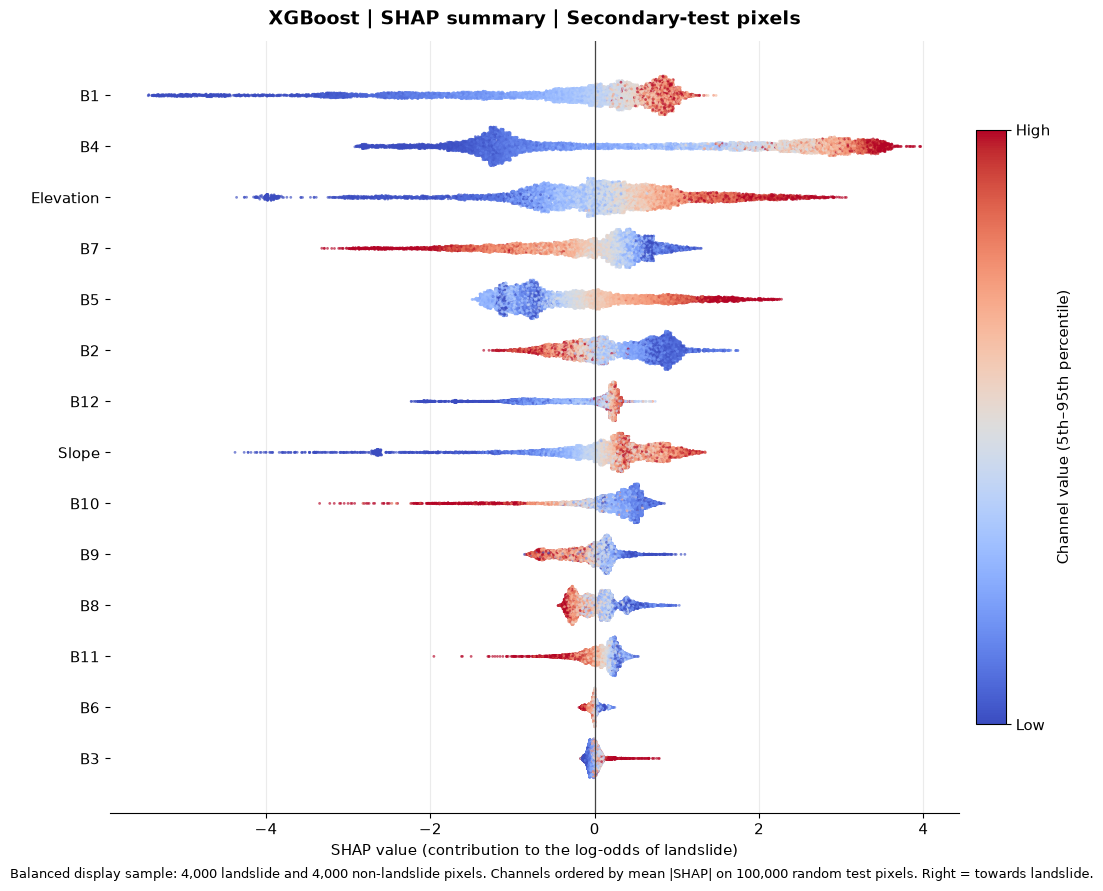

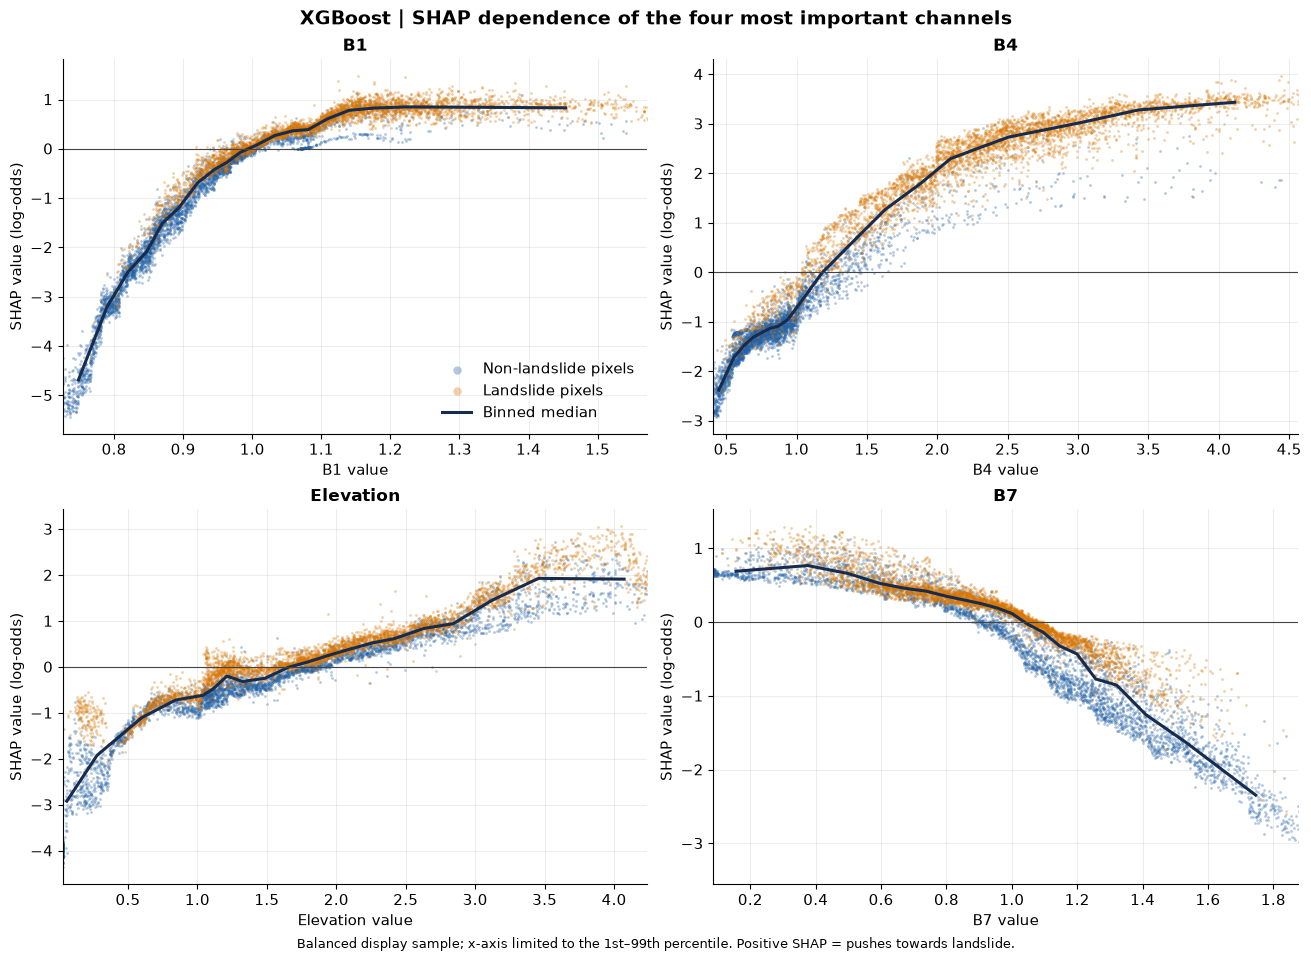

SHAP maps reproduce the saved test probabilities: PASS


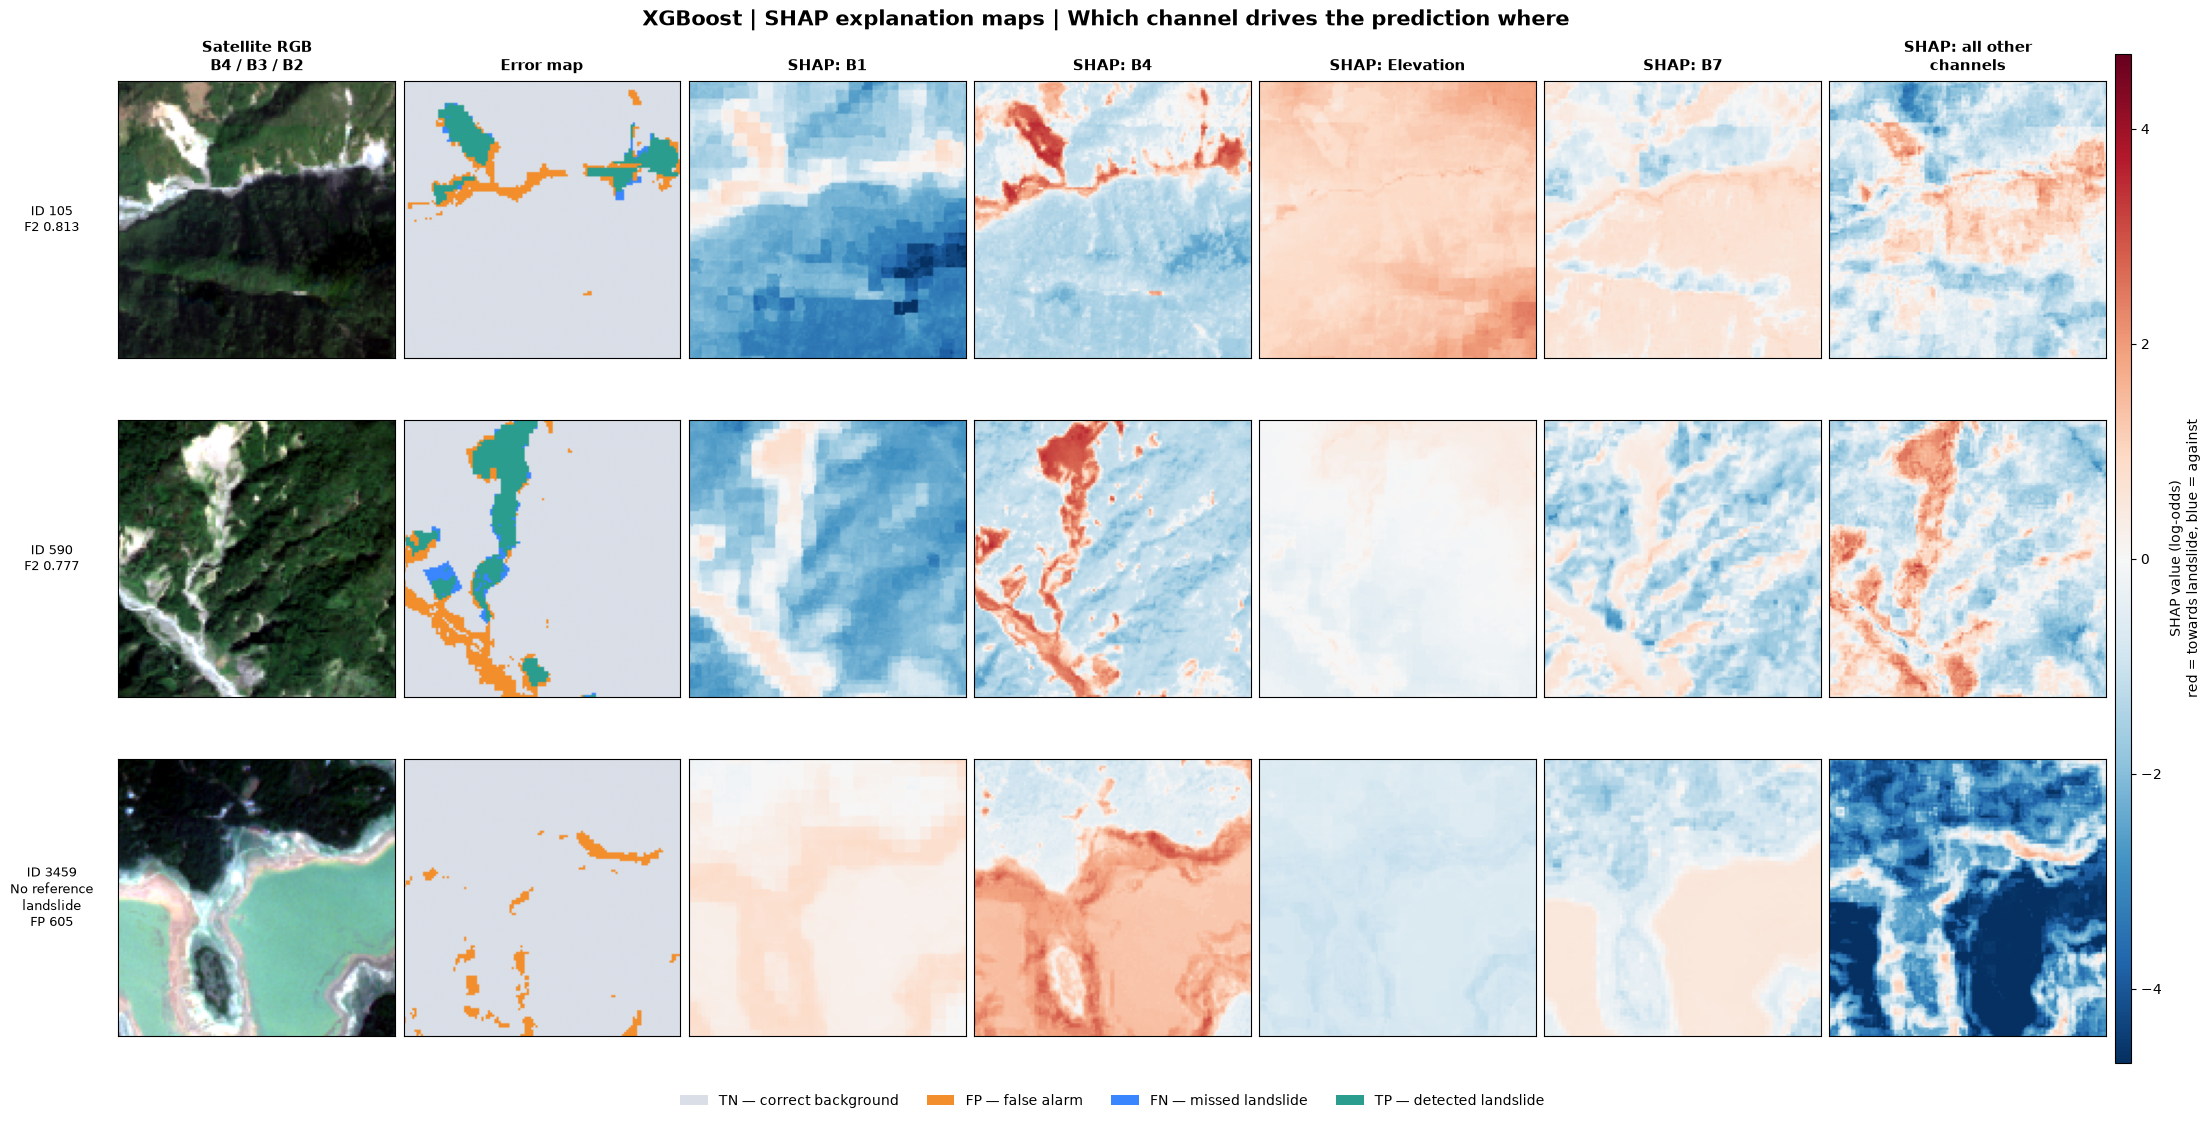


Saved: C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\xgboost\checkpoints\final_model_v1\shap_v1
Diagnostic only — the model and threshold were not changed.


In [22]:
# XGBoost — Step 16: SHAP explainability with XGBoost's built-in exact TreeSHAP.
# Locked final model; secondary-test pixels only. No training, tuning, or threshold changes.
# SHAP values are in log-odds units; per pixel they sum exactly to the model's raw margin.

from matplotlib.colors import ListedColormap, BoundaryNorm, TwoSlopeNorm
from matplotlib.cm import ScalarMappable
from matplotlib.patches import Patch

XGB_SHAP_SEED = 43
XGB_SHAP_GLOBAL_PIXELS = 100_000
XGB_SHAP_PER_CLASS = 4_000
XGB_SHAP_MAP_IMAGE_IDS = ["105", "590", "3459"]

XGB_SHAP_DIR = XGB_FINAL_MODEL_DIR / "shap_v1"
XGB_SHAP_DIR.mkdir(parents=True, exist_ok=True)

assert "xgb_pi_X" in globals() and "xgb_pi_y" in globals(), "Run Step 14 first."
assert xgb_pi_X.shape == (760 * XGB_PI_PIXELS_PER_IMAGE, 14)

xgb_booster = xgb_final_model.get_booster()
n_features = len(xgb_feature_names)


def xgb_shap_values(X):
    """Exact TreeSHAP contributions (log-odds) and bias, with an additivity check."""
    matrix = xgb.DMatrix(np.asarray(X, dtype=np.float32), nthread=2)
    contributions = xgb_booster.predict(matrix, pred_contribs=True)
    margin = xgb_booster.predict(matrix, output_margin=True)
    assert contributions.shape == (len(X), n_features + 1)
    assert np.allclose(contributions.sum(axis=1), margin, atol=1e-3, rtol=1e-4), (
        "SHAP additivity check failed."
    )
    return contributions[:, :n_features], contributions[:, n_features]


# ------------------------------------------------------------
# 1. SHAP values for a global random sample and a balanced display sample.
# ------------------------------------------------------------
xgb_shap_specification = {
    "version": "xgb_shap_v1",
    "locked_model": xgb_final_specification,
    "sample_source": str(xgb_pi_sample_file),
    "global_pixels": XGB_SHAP_GLOBAL_PIXELS,
    "per_class": XGB_SHAP_PER_CLASS,
    "seed": XGB_SHAP_SEED,
}
xgb_shap_file = XGB_SHAP_DIR / "shap_sample.joblib"

if xgb_shap_file.is_file():
    xgb_shap_data = joblib.load(xgb_shap_file)
    assert xgb_shap_data["specification"] == xgb_shap_specification
    print("Saved SHAP sample restored.")
else:
    rng = np.random.default_rng(XGB_SHAP_SEED)
    global_rows = rng.choice(len(xgb_pi_y), size=XGB_SHAP_GLOBAL_PIXELS, replace=False)
    positive_rows = np.flatnonzero(xgb_pi_y == 1)
    negative_rows = np.flatnonzero(xgb_pi_y == 0)
    display_rows = np.r_[
        rng.choice(positive_rows, size=XGB_SHAP_PER_CLASS, replace=False),
        rng.choice(negative_rows, size=XGB_SHAP_PER_CLASS, replace=False),
    ]

    print("Calculating SHAP values...", flush=True)
    started = time.perf_counter()
    global_shap, global_bias = xgb_shap_values(xgb_pi_X[global_rows])
    display_shap, _ = xgb_shap_values(xgb_pi_X[display_rows])
    print(f"SHAP calculation: {time.perf_counter() - started:.1f} s")

    xgb_shap_data = {
        "specification": xgb_shap_specification,
        "global_rows": global_rows,
        "global_shap": global_shap,
        "bias": float(global_bias[0]),
        "display_rows": display_rows,
        "display_shap": display_shap,
    }
    xgb_atomic_joblib_dump(xgb_shap_data, xgb_shap_file)

global_rows = xgb_shap_data["global_rows"]
global_shap = xgb_shap_data["global_shap"]
display_rows = xgb_shap_data["display_rows"]
display_shap = xgb_shap_data["display_shap"]
display_values = xgb_pi_X[display_rows]
display_labels = xgb_pi_y[display_rows]
global_labels = xgb_pi_y[global_rows]

print("SHAP additivity check: PASS")
print(f"Model bias (base log-odds): {xgb_shap_data['bias']:.4f}")

# ------------------------------------------------------------
# 2. Importance table: SHAP vs. permutation ranking.
# ------------------------------------------------------------
mean_abs_all = np.abs(global_shap).mean(axis=0)
mean_abs_landslide = np.abs(global_shap[global_labels == 1]).mean(axis=0)
mean_signed_landslide = global_shap[global_labels == 1].mean(axis=0)
permutation_rank = {channel: rank + 1 for rank, channel in enumerate(xgb_pi_table["Channel"])}

xgb_shap_table = pd.DataFrame({
    "Channel": xgb_feature_names,
    "Mean_abs_SHAP_all_pixels": mean_abs_all,
    "Mean_abs_SHAP_landslide_pixels": mean_abs_landslide,
    "Mean_SHAP_landslide_pixels": mean_signed_landslide,
}).sort_values("Mean_abs_SHAP_all_pixels", ascending=False).reset_index(drop=True)
xgb_shap_table.insert(1, "SHAP_rank", np.arange(1, n_features + 1))
xgb_shap_table["Permutation_rank"] = xgb_shap_table["Channel"].map(permutation_rank)
xgb_shap_table.to_csv(XGB_SHAP_DIR / "xgb_shap_importance.csv", index=False)

print(f"\nSHAP IMPORTANCE ({XGB_SHAP_GLOBAL_PIXELS:,} random test pixels; "
      f"{int((global_labels == 1).sum()):,} landslide pixels)")
print(xgb_shap_table.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

feature_order = [xgb_feature_names.index(c) for c in xgb_shap_table["Channel"]]

# ------------------------------------------------------------
# 3. Figure 1: beeswarm summary.
# ------------------------------------------------------------
rng_plot = np.random.default_rng(XGB_SHAP_SEED + 1)
draw_order = rng_plot.permutation(len(display_rows))

with plt.rc_context({"font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.spines.left": False}):
    fig, ax = plt.subplots(figsize=(10.5, 8.8), constrained_layout=True)

    for position, feature_index in enumerate(feature_order):
        values = display_shap[:, feature_index]
        raw = display_values[:, feature_index]
        low, high = np.percentile(raw, [5, 95])
        colour = (np.clip((raw - low) / (high - low), 0, 1)
                  if high > low else np.full(len(raw), 0.5))

        counts, edges = np.histogram(values, bins=80)
        bins = np.clip(np.digitize(values, edges[1:-1]), 0, len(counts) - 1)
        density = counts[bins] / counts.max()
        y = (n_features - 1 - position) + rng_plot.uniform(-1, 1, len(values)) * 0.38 * density

        ax.scatter(values[draw_order], y[draw_order], c=colour[draw_order],
                   cmap="coolwarm", vmin=0, vmax=1, s=4, alpha=0.65,
                   linewidths=0, rasterized=True)

    ax.axvline(0, color="#444444", linewidth=0.9)
    ax.set_yticks(range(n_features),
                  [xgb_feature_names[i] for i in feature_order][::-1])
    ax.set_xlabel("SHAP value (contribution to the log-odds of landslide)")
    ax.grid(axis="x", alpha=0.25)
    ax.set_axisbelow(True)

    colorbar = fig.colorbar(ScalarMappable(cmap="coolwarm"), ax=ax, pad=0.02,
                            fraction=0.035, ticks=[0, 1])
    colorbar.ax.set_yticklabels(["Low", "High"])
    colorbar.set_label("Channel value (5th–95th percentile)")

    ax.set_title("XGBoost | SHAP summary | Secondary-test pixels",
                 fontsize=14, fontweight="bold", pad=12)
    fig.supxlabel(f"Balanced display sample: {XGB_SHAP_PER_CLASS:,} landslide and "
                  f"{XGB_SHAP_PER_CLASS:,} non-landslide pixels. Channels ordered by mean |SHAP| "
                  f"on {XGB_SHAP_GLOBAL_PIXELS:,} random test pixels. Right = towards landslide.",
                  fontsize=9)
    for extension in ("png", "pdf"):
        fig.savefig(XGB_SHAP_DIR / f"xgb_shap_beeswarm.{extension}",
                    dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

# ------------------------------------------------------------
# 4. Figure 2: dependence plots for the four most important channels.
# ------------------------------------------------------------
with plt.rc_context({"font.size": 10.5, "axes.spines.top": False, "axes.spines.right": False}):
    fig, axes = plt.subplots(2, 2, figsize=(13, 9.5), constrained_layout=True)

    for ax, feature_index in zip(axes.flat, feature_order[:4]):
        raw = display_values[:, feature_index].astype(np.float64)
        values = display_shap[:, feature_index]
        low, high = np.percentile(raw, [1, 99])

        for label, colour, name in ((0, "#2563A6", "Non-landslide pixels"),
                                    (1, "#D97706", "Landslide pixels")):
            mask = display_labels == label
            ax.scatter(raw[mask], values[mask], s=4, alpha=0.35, color=colour,
                       linewidths=0, rasterized=True, label=name)

        edges = np.unique(np.quantile(raw, np.linspace(0, 1, 21)))
        centres, medians = [], []
        for left, right in zip(edges[:-1], edges[1:]):
            mask = (raw >= left) & ((raw < right) | (right == edges[-1]))
            if mask.sum() >= 20:
                centres.append(np.median(raw[mask]))
                medians.append(np.median(values[mask]))
        ax.plot(centres, medians, color="#172B4D", linewidth=2.2, label="Binned median")

        ax.axhline(0, color="#444444", linewidth=0.8)
        ax.set_xlim(low, high)
        ax.set_xlabel(f"{xgb_feature_names[feature_index]} value")
        ax.set_ylabel("SHAP value (log-odds)")
        ax.set_title(xgb_feature_names[feature_index], fontweight="bold")
        ax.grid(alpha=0.22)

    axes.flat[0].legend(frameon=False, markerscale=3, loc="best")
    fig.suptitle("XGBoost | SHAP dependence of the four most important channels",
                 fontsize=14, fontweight="bold")
    fig.supxlabel("Balanced display sample; x-axis limited to the 1st–99th percentile. "
                  "Positive SHAP = pushes towards landslide.", fontsize=9)
    for extension in ("png", "pdf"):
        fig.savefig(XGB_SHAP_DIR / f"xgb_shap_dependence.{extension}",
                    dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

# ------------------------------------------------------------
# 5. Figure 3: SHAP explanation maps for selected test images.
# ------------------------------------------------------------
locked_threshold = float(xgb_secondary_result["threshold"])
test_row = {str(image_id): row
            for row, image_id in enumerate(xgb_secondary_result["ordered_image_ids"])}
saved_scores = np.load(xgb_secondary_result["scores_path"], mmap_mode="r")
rgb_channels = [xgb_feature_names.index(band) for band in ("B4", "B3", "B2")]
top_features = feature_order[:4]
other_features = feature_order[4:]

map_items = []
for image_id in XGB_SHAP_MAP_IMAGE_IDS:
    features, reference_flat = xgb_load_source_pair(image_id)
    reference = reference_flat.reshape(128, 128).astype(bool)

    contributions, bias = xgb_shap_values(features)
    probability_from_shap = 1 / (1 + np.exp(-(contributions.sum(axis=1) + bias)))
    saved_probability = np.asarray(saved_scores[test_row[image_id]], dtype=np.float64)
    assert np.allclose(probability_from_shap, saved_probability, atol=1e-4), (
        f"Image {image_id}: SHAP margins do not reproduce the saved probabilities."
    )

    prediction = (saved_probability >= locked_threshold).reshape(128, 128)

    rgb_raw = features[:, rgb_channels].reshape(128, 128, 3)
    rgb = np.zeros_like(rgb_raw, dtype=np.float32)
    for channel in range(3):
        low, high = np.percentile(rgb_raw[:, :, channel], [2, 98])
        if high > low:
            rgb[:, :, channel] = np.clip((rgb_raw[:, :, channel] - low) / (high - low), 0, 1)

    error_map = np.zeros((128, 128), dtype=np.uint8)
    error_map[prediction & ~reference] = 1
    error_map[~prediction & reference] = 2
    error_map[prediction & reference] = 3

    tp = int(np.count_nonzero(prediction & reference))
    fp = int(np.count_nonzero(prediction & ~reference))
    fn = int(np.count_nonzero(~prediction & reference))
    label_text = (f"ID {image_id}\nF2 {5 * tp / (5 * tp + 4 * fn + fp):.3f}"
                  if reference.any() else f"ID {image_id}\nNo reference\nlandslide\nFP {fp}")

    shap_maps = [contributions[:, i].reshape(128, 128) for i in top_features]
    shap_maps.append(contributions[:, other_features].sum(axis=1).reshape(128, 128))

    map_items.append({"rgb": rgb, "error_map": error_map,
                      "shap_maps": shap_maps, "label_text": label_text})

del saved_scores
print("SHAP maps reproduce the saved test probabilities: PASS")

limit = float(np.percentile(
    np.abs(np.concatenate([np.ravel(m) for item in map_items for m in item["shap_maps"]])), 99
))
shap_norm = TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit)

error_colors = ["#D9DEE7", "#F28E2B", "#3A86FF", "#2A9D8F"]
error_cmap = ListedColormap(error_colors)
error_norm = BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 3.5], error_cmap.N)

column_titles = (["Satellite RGB\nB4 / B3 / B2", "Error map"]
                 + [f"SHAP: {xgb_feature_names[i]}" for i in top_features]
                 + ["SHAP: all other\nchannels"])
n_rows = len(map_items)

with plt.rc_context({"font.size": 10, "axes.titlesize": 11}):
    fig = plt.figure(figsize=(22, 3.3 * n_rows + 1.4), layout="constrained")
    grid = fig.add_gridspec(n_rows + 1, 8, width_ratios=[1] * 7 + [0.06],
                            height_ratios=[1] * n_rows + [0.18])

    for row, item in enumerate(map_items):
        panels = [fig.add_subplot(grid[row, column]) for column in range(7)]
        panels[0].imshow(item["rgb"])
        panels[1].imshow(item["error_map"], cmap=error_cmap, norm=error_norm)
        for column, shap_map in enumerate(item["shap_maps"], start=2):
            shap_artist = panels[column].imshow(shap_map, cmap="RdBu_r", norm=shap_norm)
        for column, panel in enumerate(panels):
            panel.set_xticks([])
            panel.set_yticks([])
            if row == 0:
                panel.set_title(column_titles[column], pad=8, fontweight="bold")
        panels[0].set_ylabel(item["label_text"], rotation=0, labelpad=48,
                             va="center", fontsize=9.5)

    colorbar = fig.colorbar(shap_artist, cax=fig.add_subplot(grid[:n_rows, 7]))
    colorbar.set_label("SHAP value (log-odds)\nred = towards landslide, blue = against")

    legend_axis = fig.add_subplot(grid[n_rows, :7])
    legend_axis.axis("off")
    legend_axis.legend(
        handles=[Patch(facecolor=error_colors[0], label="TN — correct background"),
                 Patch(facecolor=error_colors[1], label="FP — false alarm"),
                 Patch(facecolor=error_colors[2], label="FN — missed landslide"),
                 Patch(facecolor=error_colors[3], label="TP — detected landslide")],
        loc="center", ncol=4, frameon=False, fontsize=10,
    )

    fig.suptitle("XGBoost | SHAP explanation maps | Which channel drives the prediction where",
                 fontsize=15, fontweight="bold")
    for extension in ("png", "pdf"):
        fig.savefig(XGB_SHAP_DIR / f"xgb_shap_explanation_maps.{extension}",
                    dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

print("\nSaved:", XGB_SHAP_DIR)
print("Diagnostic only — the model and threshold were not changed.")

**Result — SHAP explainability (exact TreeSHAP, locked model).** SHAP decomposes each pixel's prediction into additive channel contributions (log-odds); the additivity check passed, and the explanation maps reproduce the saved test probabilities exactly. The model's baseline log-odds is −3.82 (≈ 2% landslide probability), so each pixel starts from the landslide prevalence, and the channels push it up or down.

*Global importance.* On 100,000 random test pixels, the largest mean |SHAP| values belong to B1 (1.58), B4 (1.27), elevation (1.01), B7 (0.89), and B5 (0.88); B6 and B3 contribute almost nothing. On landslide pixels alone, B4 dominates clearly (mean |SHAP| 2.27; mean signed contribution +2.14), followed by elevation, B5, B1, and slope. The ranking differs slightly from permutation importance because the two methods measure different things: mean |SHAP| over all pixels is dominated by the ~98% non-landslide pixels, whereas permutation importance measures the loss in F2, which depends on correctly detecting landslide pixels. Both agree that B4, B1, and elevation are the key inputs and that B3 and B6 are redundant.

*How the channels act (beeswarm and dependence plots).*
- **B4 (red) is the main positive evidence for landslides.** Its contribution rises monotonically with its value and saturates at about +3.4 log-odds, consistent with the bright, bare soil and rock of fresh landslide scars.
- **B1 acts mainly as a rule-out variable.** Low B1 values push predictions strongly towards non-landslide (down to about −5), whereas high values add only a moderate, saturating positive contribution (about +0.9).
- **Vegetation-sensitive bands act as a veto.** High B7 and B8 values push against landslide, which is consistent with vegetated surfaces, while high B5 pushes towards landslide.
- **Terrain adds physically plausible information.** Steeper slopes increase, and flat terrain strongly decreases, the landslide probability; elevation increases it almost monotonically.
- The vertical spread between landslide and non-landslide pixels at the same channel value shows that the model combines channels through interactions rather than single thresholds.

*Explanation maps.*
- In images 105 and 590, the true landslides and the falsely detected river channels both receive strong positive B4 contributions; the vegetation and other bands do not counteract them on these bright, bare valley floors, which explains the false alarms.
- In image 3459, B4 favours landslide over the entire reservoir and its banks; over open water, the remaining channels cancel this strongly, but on the bare, sediment-covered banks the cancellation is weaker, producing the 605 false-positive pixels.
- The B1 and elevation maps are spatially smooth (B1 even shows its coarse 60 m pixel structure) and shift the probability of whole image regions up or down. This supports the interpretation that these inputs act partly as scene- or region-level variables rather than as landslide-specific signals.

Overall, SHAP shows that XGBoost has learned physically meaningful relationships (bare-surface brightness, vegetation, steepness), but as a pixel-based model it cannot distinguish landslide scars from other bright, bare surfaces with similar spectra. This points directly to spatial context (shape, neighbourhood, texture) as the most promising improvement.